In [35]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [36]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr

from cordex2energy.conversion_energy.tyndp import (
    load_tyndp_supply_capacities,
)
from cordex2energy_analysis.extreme_value import (
    calculate_climatological_baseline,
    compute_continuous_system_metrics,
    resolve_gwl_period_definitions,
    compute_seasonal_evt_metrics,
    compute_seasonal_exceedance_fractions,
    compute_zone_pair_cooccurrence,
    compute_unserved_energy_fraction,
    compute_flexibility_attenuation_metrics,
)
from cordex2energy_analysis.extremes_thresholds import (
    compute_active_threshold,
    calibrate_seasonal_active_thresholds,
)
from cordex2energy_analysis.extremes_analysis import (
    extract_event_diurnal_profiles,
)
from cordex2energy_analysis.plotting_extremes import (
    resolve_model_periods,
    plot_component_anomaly_distributions,
    plot_residual_load_kde,
    plot_seasonal_exceedance_distribution,
    plot_seasonal_conditional_metrics,
    plot_seasonal_attribution,
    plot_seasonal_attribution_change,
    plot_seasonal_component_anomaly_distributions,
    plot_zone_cooccurrence_heatmaps,
    plot_zone_cooccurrence_boxplots,
    plot_event_diurnal_profile,
)
from cordex2energy.utils.constants import (
    END_CENTURY_PERIOD,
    MID_CENTURY_PERIOD,
    REFERENCE_PERIOD,
)

sns.set_style("whitegrid", {"grid.color": ".93"})

In [37]:
paths = json.load(open("../paths.json"))

path_data_processed = Path(paths["path_data_processed"])
path_data_extremes  = path_data_processed / "extremes"
path_tyndp          = path_data_extremes / "tyndp"
path_residual_load  = path_data_extremes / "residual_load"


In [38]:
climate_scenario = "rcp85"
demand_scenario  = "DE"
demand_year      = 2050
supply_scenario  = "HIGH"
supply_year      = 2040
rolling_window_residual_load = 1
use_reservoir_hydro = True
use_batteries = True
use_prosumer_batteries = True

run_tag = f"{demand_scenario}_{demand_year}_{supply_scenario}_{supply_year}"
if rolling_window_residual_load and rolling_window_residual_load > 1:
    run_tag += f"_rlsmooth_{rolling_window_residual_load}"
if use_reservoir_hydro:
    run_tag += "_reservoirdispatch"
if use_batteries:
    run_tag += "_batteries"
    if use_prosumer_batteries:
        run_tag += "_prosumer"

# ── Threshold method ──────────────────────────────────────────────────────────
# "EVT"   → Peaks-Over-Threshold / GPD stability test
# "TAILS" → TAILS automated selection (95 % floor; ~25 s per model)
THRESHOLD_METHOD = "TAILS"  # "EVT" or "TAILS"

# ── Threshold data source ─────────────────────────────────────────────────────
# False → per-CORDEX-model thresholds calibrated on each model's own reference period
# True  → single threshold calibrated on CERRA and applied to all models
USE_CERRA_THRESHOLDS = True

USE_WARMING_LEVELS = True
WARMING_LEVELS     = [1.5, 2.0, 3.0]

# ── Event detection method ────────────────────────────────────────────────────
# "run_length" → contiguous blocks of rl > threshold (default)
# "spa"        → Sequent Peak Algorithm: brief dips below threshold are absorbed
#                into an ongoing event as long as the cumulative energy surplus
#                above the threshold has not been fully discharged.
#                Typically yields fewer but longer events than run_length.
EVENT_DETECTION_METHOD = "spa"  # "run_length" or "spa"

# Load data

In [39]:
path_supply_excel = (
    path_tyndp / "20231103 - Final Supply Inputs for TYNDP 2024 Scenarios.xlsx"
)
df_tyndp_solar, df_tyndp_wind_onshore, df_tyndp_wind_offshore = (
    load_tyndp_supply_capacities(path_supply_excel)
)
path_demand_excel = (
    path_tyndp / "Demand_Scenarios_TYNDP_2024_After_Public_Consultation.xlsb"
)

In [40]:
ds_residual_load_zonal = []
ds_components_zonal    = []

for folder in sorted(path_residual_load.glob("*")):
    if not folder.is_dir() or folder.name == "cerra":
        continue
    run_dir = folder / run_tag
    if not run_dir.exists():
        print(f"  Skipping {folder.name}: no '{run_tag}' subfolder")
        continue
    model_name = "_".join(folder.name.split("_")[:-1])
    ds_residual_load_zonal.append(
        xr.open_dataset(run_dir / "residual_load_zonal.nc").expand_dims(dim={"model": [model_name]})
    )
    ds_components_zonal.append(
        xr.open_dataset(run_dir / "components_zonal.nc").expand_dims(dim={"model": [model_name]})
    )

ds_residual_load_zonal = xr.concat(ds_residual_load_zonal, dim="model", join="outer")
ds_components_zonal    = xr.concat(ds_components_zonal,    dim="model", join="outer")
print(f"Loaded {len(ds_residual_load_zonal.model)} models for run '{run_tag}'")


Loaded 9 models for run 'DE_2050_HIGH_2040_reservoirdispatch_batteries_prosumer'


In [41]:
season_map = {
    3: "MAM",  4: "MAM",  5: "MAM",
    6: "JJA",  7: "JJA",  8: "JJA",
    9: "SON",  10: "SON", 11: "SON",
    12: "DJF", 1: "DJF",  2: "DJF",
}
season_order = ["DJF", "MAM", "JJA", "SON"]
season_months = {s: [m for m, ss in season_map.items() if ss == s] for s in season_order}

period_defs = {
    "Reference":   (REFERENCE_PERIOD[0],   REFERENCE_PERIOD[1]),
    "Mid-Century": (MID_CENTURY_PERIOD[0], MID_CENTURY_PERIOD[1]),
    "End-Century": (END_CENTURY_PERIOD[0], END_CENTURY_PERIOD[1]),
}
PERIOD_LABEL = {
    "Reference":   "1_Reference",
    "Mid-Century": "2_Mid-Century",
    "End-Century": "3_End-Century",
}
PERIOD_SHORT          = {v: k for k, v in PERIOD_LABEL.items()}
period_colors         = {"Reference": "#4A90E2", "Mid-Century": "#F5A623", "End-Century": "#E24A4A"}
period_colors_internal = {v: period_colors[k] for k, v in PERIOD_LABEL.items()}

driver_palette = {
    "Demand":           "#D95F02",
    "PV":               "#E6AB02",
    "Wind Onshore":     "#7570B3",
    "Wind Offshore":    "#1B7C3D",
    "Hydro RoR":        "#3182BD",
    "Reservoir Hydro":  "#08519C",
    "Battery":          "#8B5A2B",
}
driver_cols = {
    "Demand":           "Demand_Driven_Share_%",
    "PV":               "PV_Driven_Share_%",
    "Wind Onshore":     "Wind_Onshore_Driven_Share_%",
    "Wind Offshore":    "Wind_Offshore_Driven_Share_%",
    "Hydro RoR":        "Hydro_RoR_Driven_Share_%",
    "Reservoir Hydro":  "Reservoir_Hydro_Driven_Share_%",
    "Battery":          "Battery_Driven_Share_%",
}

# ── Absolute anomaly GWh columns (for plot_component_anomaly_distributions) ──
anomaly_component_cols = {
    "Demand":           "Avg_Demand_Anomaly_GWh",
    "PV":               "Avg_PV_Anomaly_GWh",
    "Wind Onshore":     "Avg_Wind_Onshore_Anomaly_GWh",
    "Wind Offshore":    "Avg_Wind_Offshore_Anomaly_GWh",
    "Hydro RoR":        "Avg_Hydro_RoR_Anomaly_GWh",
    "Reservoir Hydro":  "Avg_Reservoir_Anomaly_GWh",
    "Battery":          "Avg_Battery_Anomaly_GWh",
}

zones    = ds_residual_load_zonal["zone"].values
models   = ds_residual_load_zonal["model"].values
n_models = len(models)
print(f"Zones  : {zones}")
print(f"Models : {n_models}  →  {list(models)}")

Zones  : ['British_Isles' 'Central_Eastern' 'Central_Western' 'Iberian_Peninsula'
 'Nordic' 'South_East']
Models : 9  →  ['CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1', 'CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1', 'CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1', 'CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1', 'MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1', 'MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1', 'MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1', 'MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1', 'MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1']


In [42]:
if USE_WARMING_LEVELS:
    period_defs, PERIOD_LABEL, period_colors = resolve_gwl_period_definitions(
        warming_levels=WARMING_LEVELS,
        models=models,
        chain_meta_path="../models.json",
        gwl_yaml_path=path_data_processed / "cmip5_warming_levels_all_ens_1861_1900.yml",
        climate_scenario=climate_scenario,
    )
    PERIOD_SHORT = {v: k for k, v in PERIOD_LABEL.items()}
    period_colors_internal = {v: period_colors[k] for k, v in PERIOD_LABEL.items()}

    print(f"GWL periods (scenario: {climate_scenario}):")
    for label, windows in period_defs.items():
        print(f"  {label}: {len(windows)}/{len(models)} models")
else:
    print(f"Fixed calendar periods: {list(period_defs.keys())}")


GWL periods (scenario: rcp85):
  +1.5°C: 9/9 models
  +2.0°C: 9/9 models
  +3.0°C: 9/9 models


## Multi-model KDE by zone and season

One figure per TYNDP balancing zone; each panel shows one season.  For each period the **ensemble
median KDE** is drawn as a bold line; the **10–90th-percentile band across models** is shaded.
The x-axis is shared across periods within a panel so distributional shifts are immediately visible.

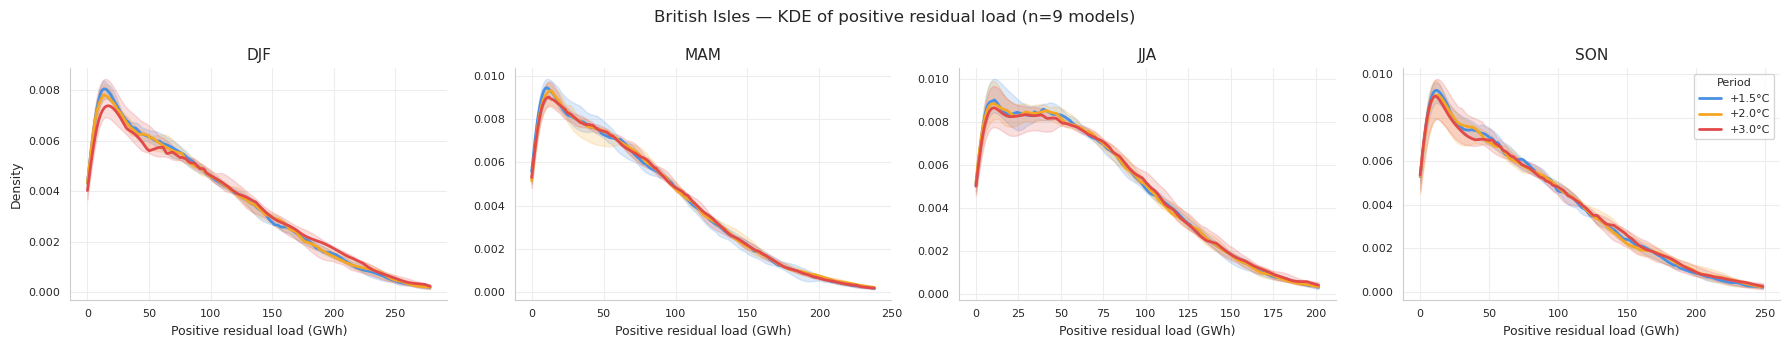

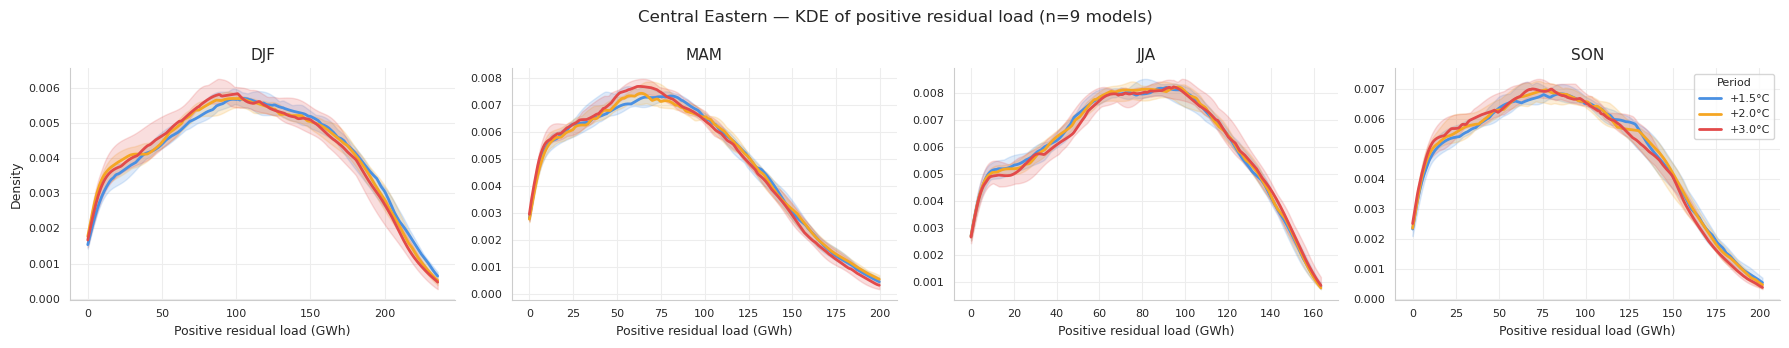

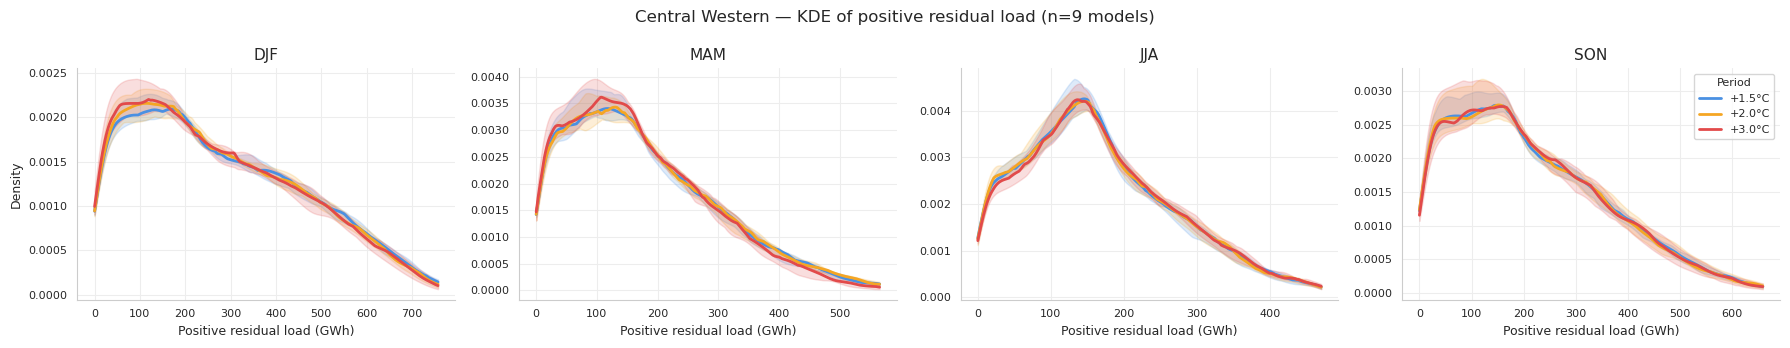

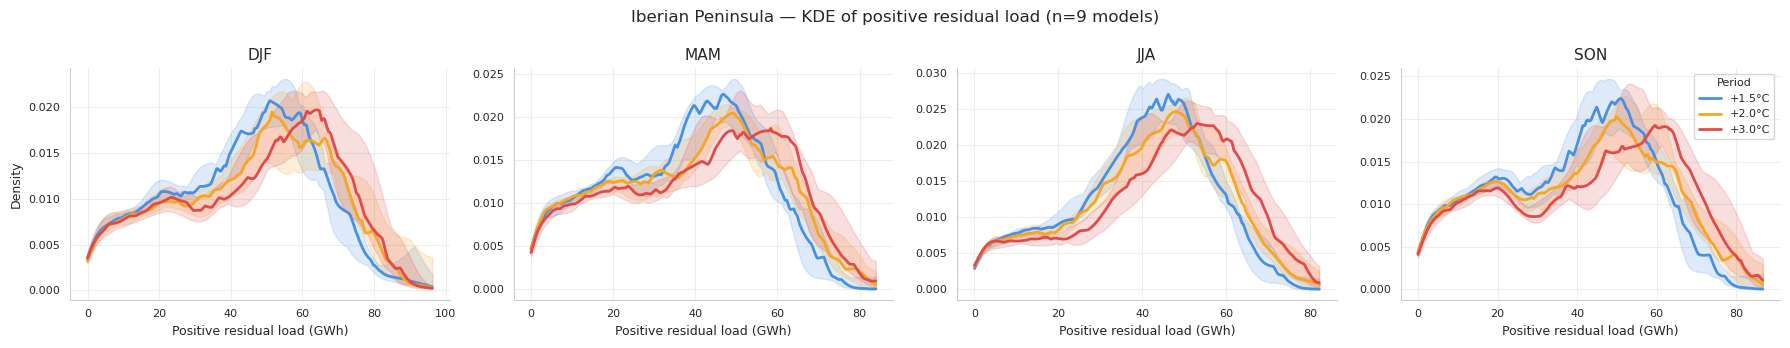

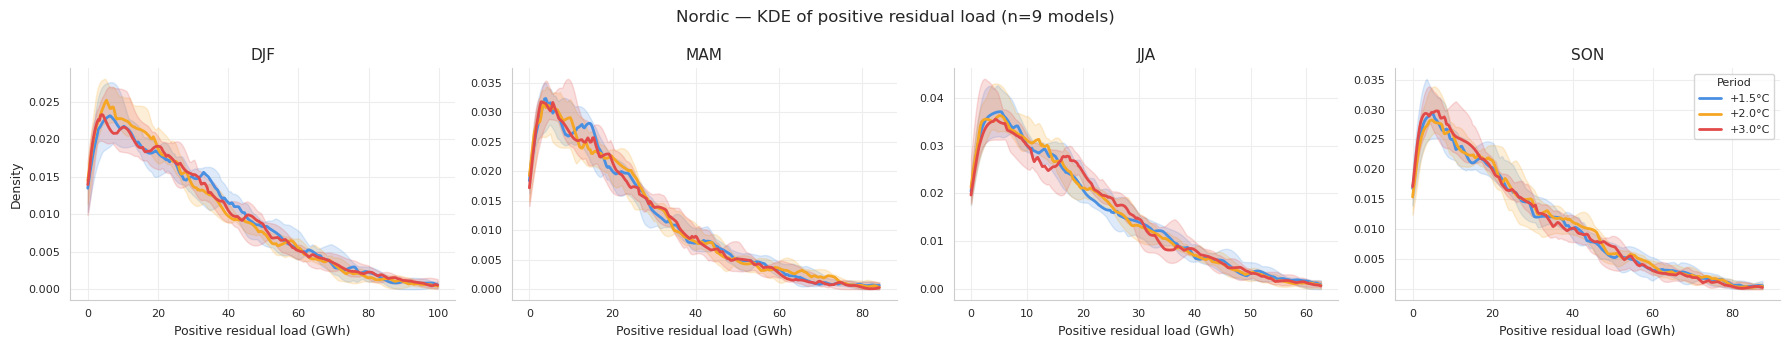

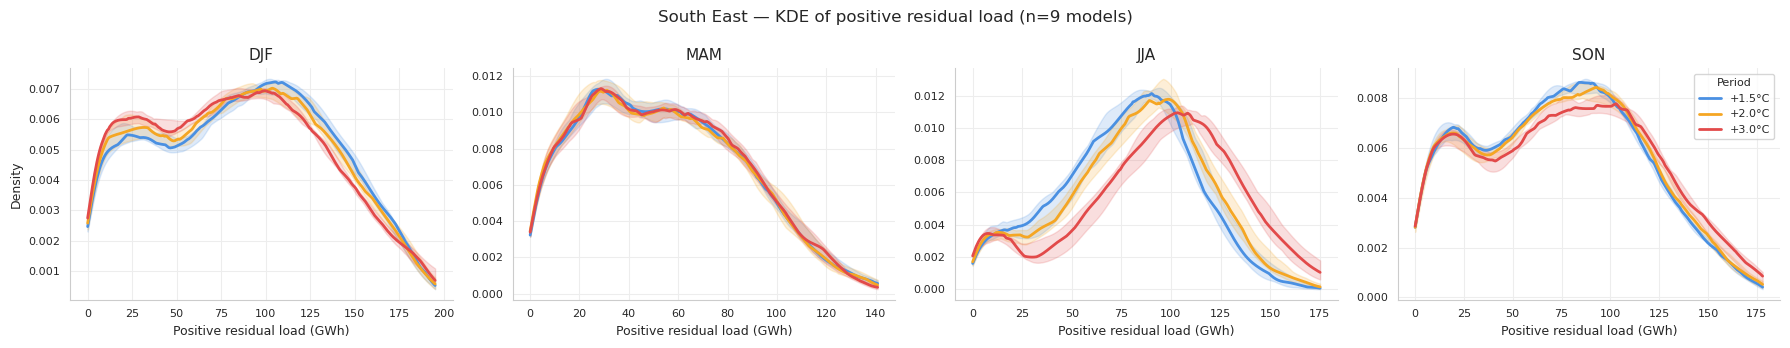

In [43]:
plot_residual_load_kde(
    ds_residual_load_zonal,
    zones=zones,
    period_defs=period_defs,
    period_colors=period_colors,
    models=models,
    season_map=season_map,
    season_order=season_order,
    threshold=0,  # None → full distribution; 0.0 → positive RL only
)

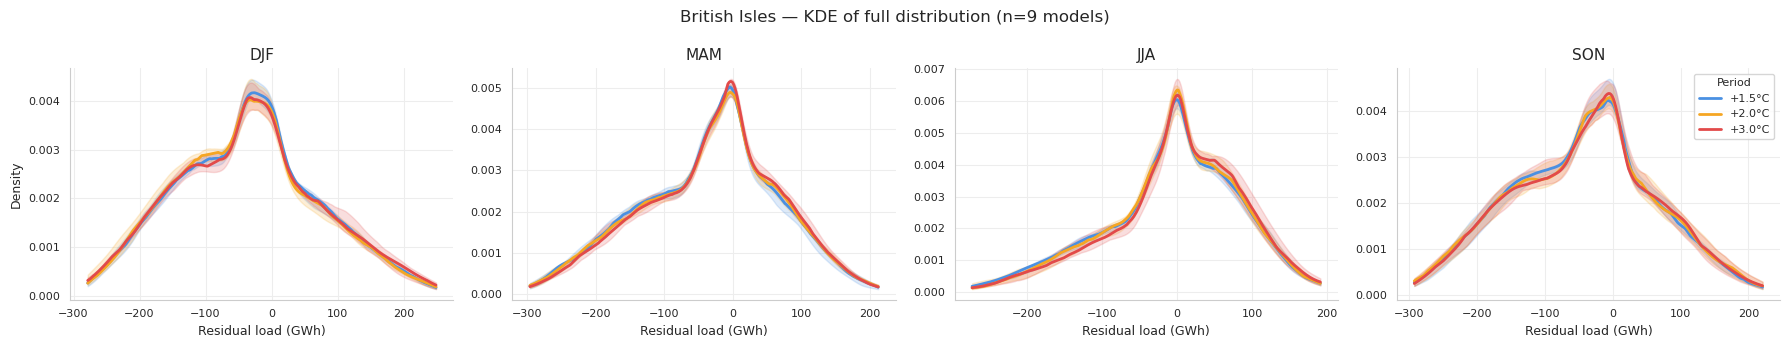

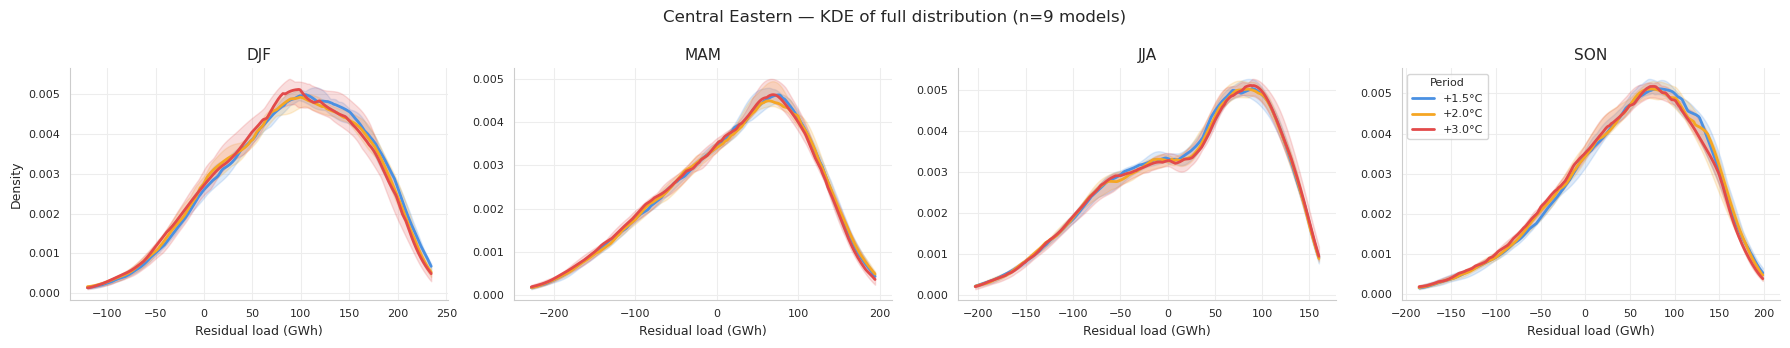

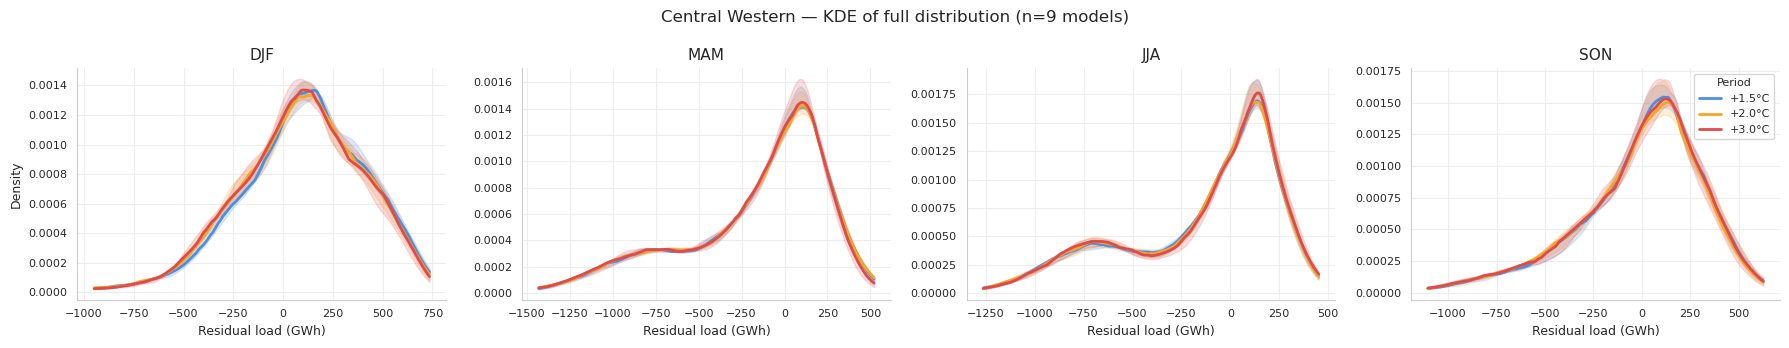

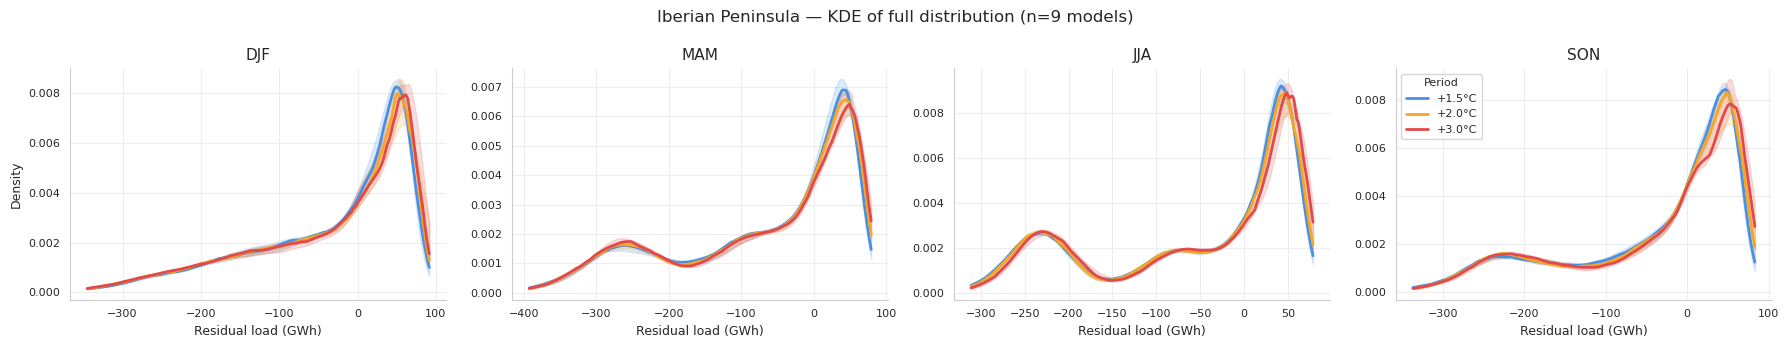

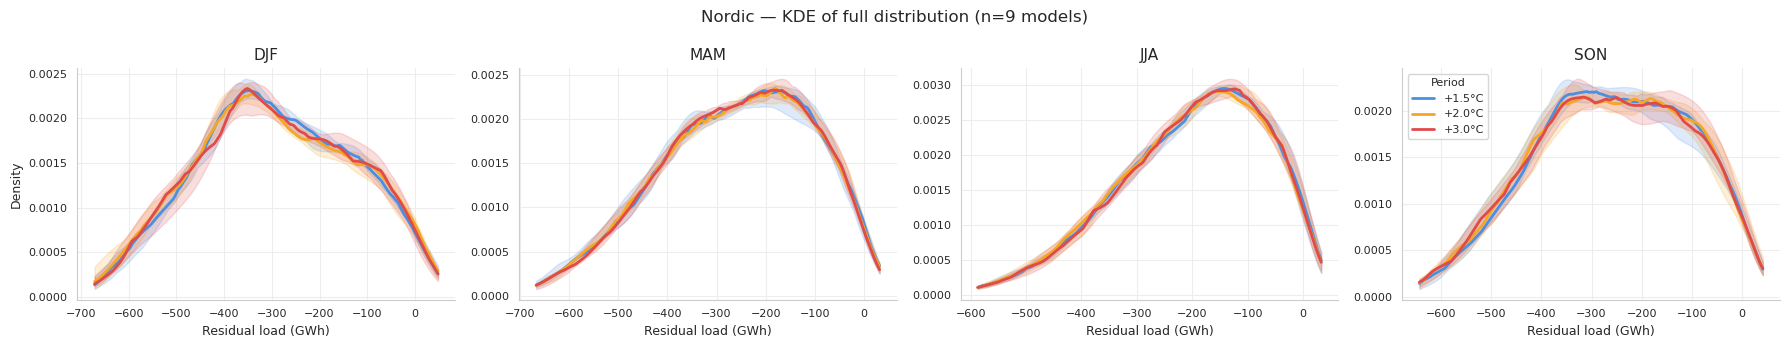

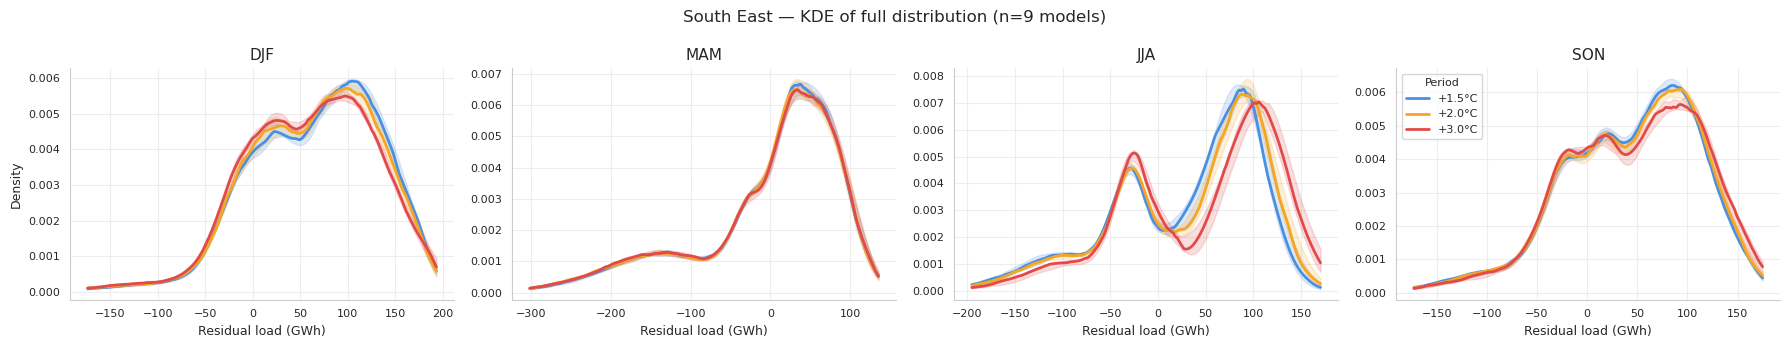

In [44]:
plot_residual_load_kde(
    ds_residual_load_zonal,
    zones=zones,
    period_defs=period_defs,
    period_colors=period_colors,
    models=models,
    season_map=season_map,
    season_order=season_order,
    threshold=None,  # None → full distribution including negative RL
)

In [45]:
import time

# ── Pre-compute CERRA thresholds when USE_CERRA_THRESHOLDS = True ─────────────
if USE_CERRA_THRESHOLDS:
    _cerra_run_dir = path_residual_load / "cerra" / run_tag
    print(f"Loading CERRA from: {_cerra_run_dir}")
    _ds_rl_c   = xr.open_dataset(_cerra_run_dir / "residual_load_zonal.nc")
    _ds_comp_c = xr.open_dataset(_cerra_run_dir / "components_zonal.nc")
    _common_c  = np.intersect1d(_ds_rl_c.time.values, _ds_comp_c.time.values)
    _ds_rl_c   = _ds_rl_c.sel(time=_common_c)
    _ds_comp_c = _ds_comp_c.sel(time=_common_c)
    _ds_clim_c = calculate_climatological_baseline(_ds_comp_c)
    _ds_met_c  = compute_continuous_system_metrics(_ds_rl_c, _ds_comp_c, _ds_clim_c)
    _da_rl_c   = _ds_met_c["residual_load"]

    _t0 = time.perf_counter()
    da_cerra_threshold = compute_active_threshold(_da_rl_c, THRESHOLD_METHOD)
    cerra_season_thresholds, _ = calibrate_seasonal_active_thresholds(
        _da_rl_c, zones, season_order, season_months, THRESHOLD_METHOD
    )
    print(
        f"CERRA {THRESHOLD_METHOD} annual thresholds (GWh): "
        f"{{{', '.join(f'{z}: {float(da_cerra_threshold.sel(zone=z)):.1f}' for z in da_cerra_threshold.zone.values)}}}  "
        f"[{time.perf_counter() - _t0:.1f}s]"
    )
else:
    da_cerra_threshold     = None   # unused; per-model thresholds computed in the loop
    cerra_season_thresholds = None  # same

Loading CERRA from: /net/exo/landclim/yhaddad/clim2energy-ch/extremes/residual_load/cerra/DE_2050_HIGH_2040_reservoirdispatch_batteries_prosumer


CERRA TAILS annual thresholds (GWh): {British_Isles: 163.3, Central_Eastern: 227.1, Central_Western: 520.5, Iberian_Peninsula: 67.6, Nordic: 0.2, South_East: 172.1}  [76.0s]


In [46]:
_cache_rl   = {}
_cache_comp = {}
_cache_clim = {}
active_thresholds        = {}   # annual: {model: DataArray(zone)}
season_active_thresholds = {}   # seasonal: {model: {zone: {season: float}}}

_thr_source = "CERRA" if USE_CERRA_THRESHOLDS else "model-specific"

for model in models:
    print(f"\n── {model}")

    ds_rl_m = (
        ds_residual_load_zonal.sel(model=model)
        .drop_vars("model", errors="ignore")
        .dropna("time", how="all")
    )
    ds_comp_m = (
        ds_components_zonal.sel(model=model)
        .drop_vars("model", errors="ignore")
        .dropna("time", how="all")
    )
    _common_time = np.intersect1d(ds_rl_m.time.values, ds_comp_m.time.values)
    ds_rl_m   = ds_rl_m.sel(time=_common_time)
    ds_comp_m = ds_comp_m.sel(time=_common_time)

    ds_clim = calculate_climatological_baseline(ds_comp_m.sel(time=slice(*REFERENCE_PERIOD)))

    t0_ref, t1_ref = REFERENCE_PERIOD
    ds_rl_ref   = ds_rl_m.sel(time=slice(t0_ref, t1_ref))
    ds_comp_ref = ds_comp_m.sel(time=slice(t0_ref, t1_ref))
    ds_met_ref  = compute_continuous_system_metrics(ds_rl_ref, ds_comp_ref, ds_clim)
    da_rl_ref   = ds_met_ref["residual_load"]

    if USE_CERRA_THRESHOLDS:
        da_active       = da_cerra_threshold
        season_active   = cerra_season_thresholds
    else:
        _t0 = time.perf_counter()
        da_active = compute_active_threshold(da_rl_ref, THRESHOLD_METHOD)
        season_active, _s_pct = calibrate_seasonal_active_thresholds(
            da_rl_ref, zones, season_order, season_months, THRESHOLD_METHOD
        )
        print(
            f"  {THRESHOLD_METHOD} thresholds (GWh): "
            f"{{{', '.join(f'{z}: {float(da_active.sel(zone=z)):.1f}' for z in da_active.zone.values)}}}  "
            f"[{time.perf_counter() - _t0:.1f}s]"
        )
        print(f"  Seasonal {THRESHOLD_METHOD} percentiles (%):")
        for zone in zones:
            row = "    " + str(zone) + ": " + "  ".join(
                f"{s}={_s_pct[str(zone)][s]:.1f}" for s in season_order
            )
            print(row)

    active_thresholds[model]        = da_active
    season_active_thresholds[model] = season_active

    _cache_rl[model]   = ds_rl_m
    _cache_comp[model] = ds_comp_m
    _cache_clim[model] = ds_clim

print(f"\n✓ Setup complete for all models  [{THRESHOLD_METHOD} · {_thr_source}]")


── CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1

── CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1

── CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1

── CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1

── MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1

── MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1

── MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1

── MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1

── MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1

✓ Setup complete for all models  [TAILS · CERRA]


# Seasonal Analysis

## Seasonal-conditional EVT metrics

Computes event frequency, duration, severity, PCIT, and driver attribution
for each (zone, season) using **season-specific thresholds** calibrated from
the reference period. Events are constrained to each season (cross-season
connections are blocked). This answers: *how does each season's own extreme
tail evolve with warming?*

In [47]:
all_rows = []
for model in models:
    resolved = {
        k: v for k, v in resolve_model_periods(period_defs, model).items()
        if v is not None
    }
    for period_name, (t0, t1) in resolved.items():
        ds_rl_p   = _cache_rl[model].sel(time=slice(t0, t1))
        ds_comp_p = _cache_comp[model].sel(time=slice(t0, t1))
        ds_met_p  = compute_continuous_system_metrics(ds_rl_p, ds_comp_p, _cache_clim[model])
        all_rows += compute_seasonal_evt_metrics(
            ds_rl_p, ds_met_p,
            season_order, season_months,
            season_active_thresholds[model],
            model, period_name, zones,
            method=EVENT_DETECTION_METHOD,
        )

df_seasonal_evt = pd.DataFrame(all_rows)
print(f"df_seasonal_evt: {df_seasonal_evt.shape[0]} rows × {df_seasonal_evt.shape[1]} columns  "
      f"[{THRESHOLD_METHOD} · events={EVENT_DETECTION_METHOD}]")
df_seasonal_evt.groupby(["zone", "season", "Period"])["Frequency"].median().unstack("Period").round(0)

df_seasonal_evt: 648 rows × 29 columns  [TAILS · events=spa]


Period                    +1.5°C  +2.0°C  +3.0°C
zone              season                        
British_Isles     DJF      105.0   102.0   132.0
                  JJA      154.0   163.0   190.0
                  MAM      143.0   152.0   152.0
                  SON      242.0   229.0   260.0
Central_Eastern   DJF      124.0   110.0    93.0
                  JJA      152.0   145.0   150.0
                  MAM      272.0   270.0   241.0
                  SON       69.0    61.0    52.0
Central_Western   DJF      244.0   222.0   206.0
                  JJA      205.0   192.0   218.0
                  MAM      326.0   329.0   287.0
                  SON      235.0   216.0   219.0
Iberian_Peninsula DJF      229.0   245.0   292.0
                  JJA      162.0   242.0   432.0
                  MAM      144.0   271.0   366.0
                  SON       12.0    80.0    96.0
Nordic            DJF      100.0   102.0    96.0
                  JJA      278.0   261.0   262.0
                  MAM      114.0   108.0   106.0
                  SON       30.0    34.0    26.0
South_East        DJF      374.0   353.0   391.0
                  JJA       44.0    92.0   317.0
                  MAM       36.0    29.0    15.0
                  SON      265.0   305.0   448.0

In [48]:
# Ensemble-median season-specific thresholds vs common annual threshold
print(f"Season-specific {THRESHOLD_METHOD} thresholds — ensemble median (GWh)\n")
header = f"{'Zone':<22}" + "".join(f"{s:>8}" for s in season_order) + f"{'Annual':>10}"
print(header)
print("-" * len(header))
for zone in zones:
    annual_med = np.median([float(active_thresholds[m].sel(zone=zone)) for m in models])
    row = f"{str(zone):<22}"
    for season in season_order:
        s_med = np.median([season_active_thresholds[m][str(zone)][season] for m in models])
        row += f"{s_med:>8.1f}"
    row += f"{annual_med:>10.1f}"
    print(row)

Season-specific TAILS thresholds — ensemble median (GWh)

Zone                       DJF     MAM     JJA     SON    Annual
----------------------------------------------------------------
British_Isles            211.0   180.5   171.0   139.8     163.3
Central_Eastern          214.1   149.3   152.5   186.5     227.1
Central_Western          616.8   368.1   407.9   476.6     520.5
Iberian_Peninsula         73.7    64.0    63.6    77.7      67.6
Nordic                     6.0     5.1    -9.8    46.1       0.2
South_East               167.3   144.7   156.1   152.8     172.1


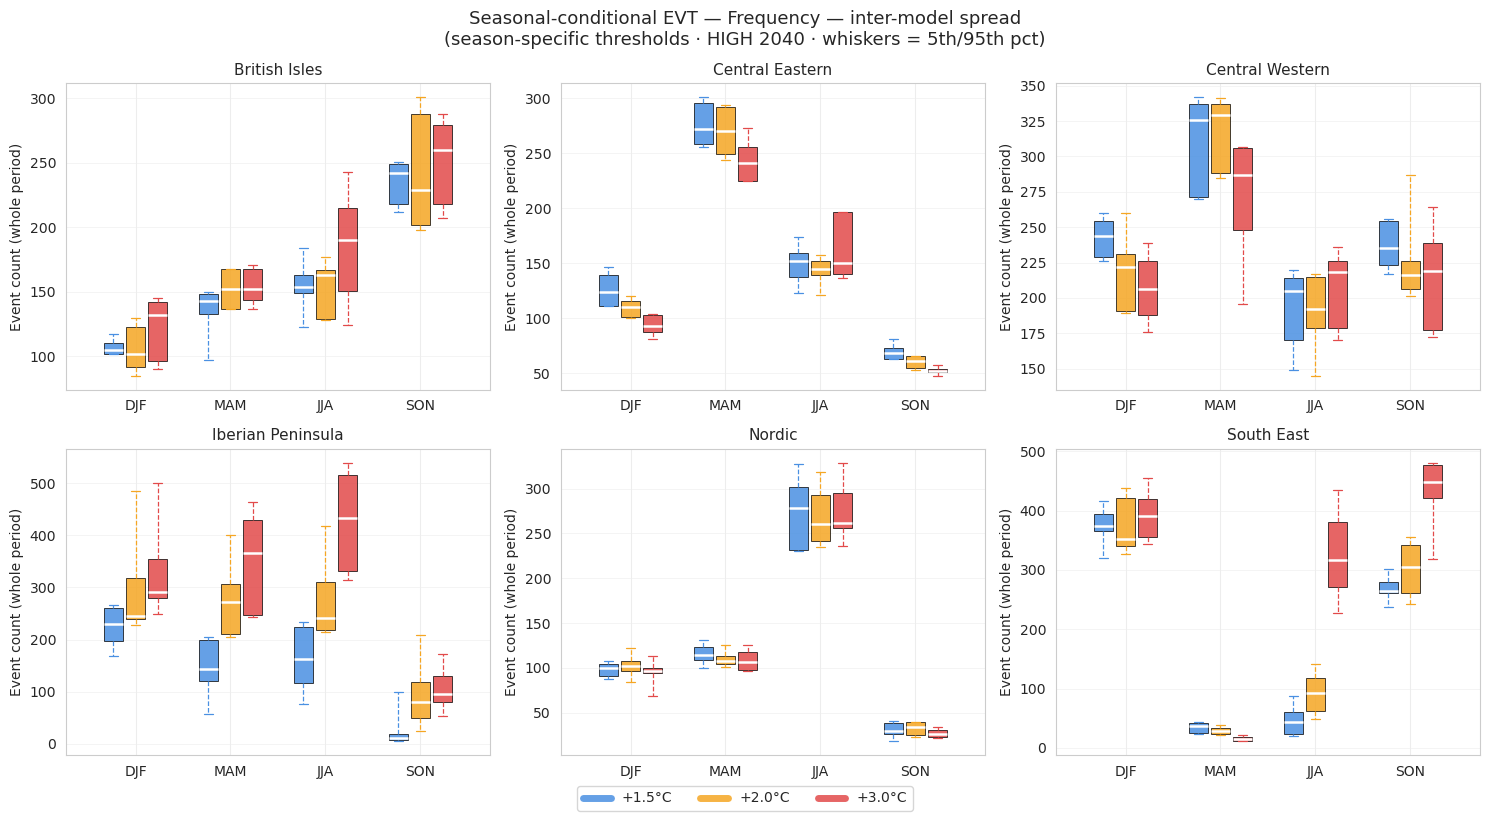

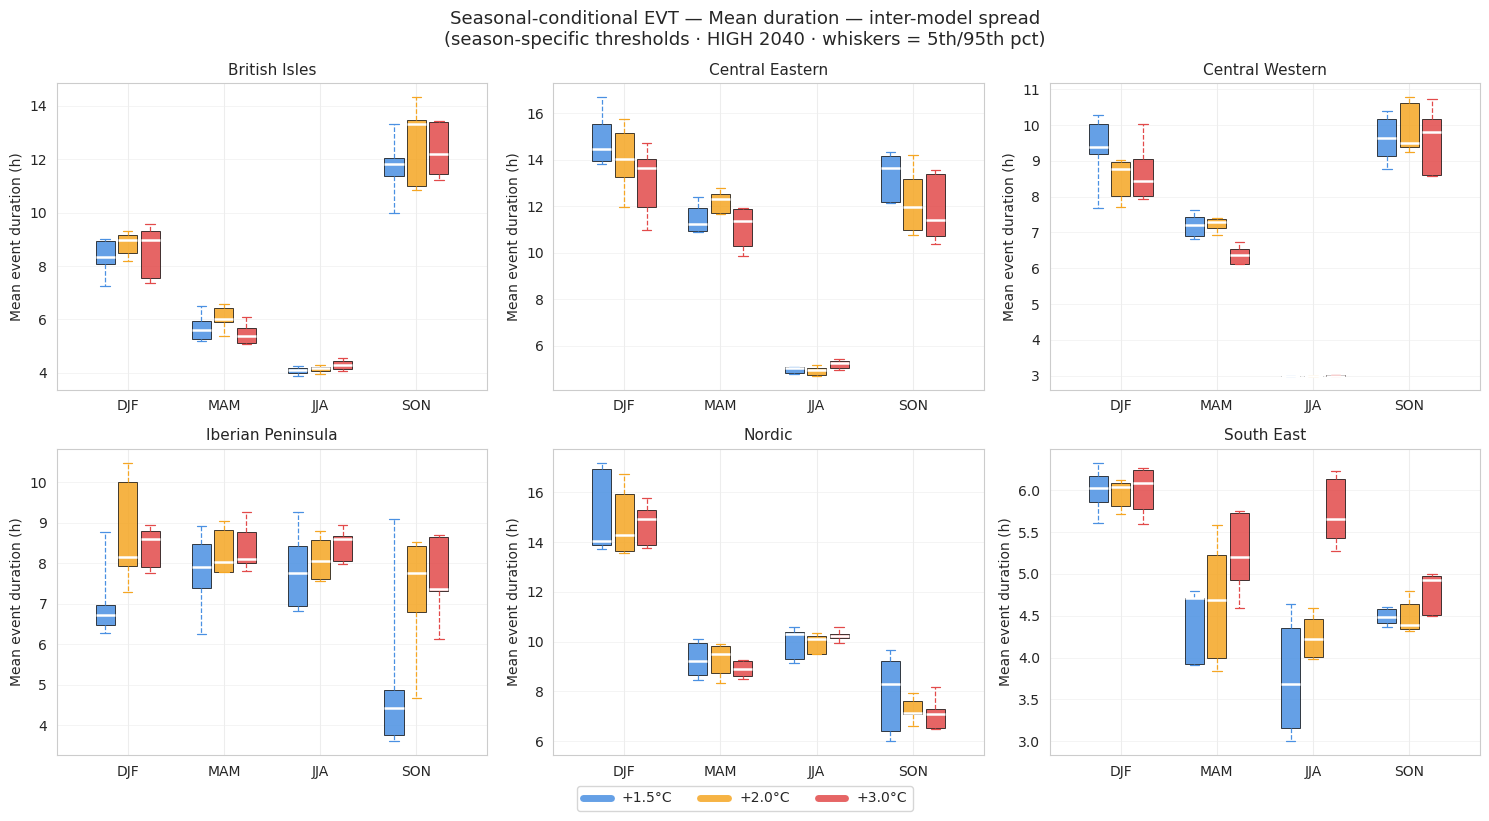

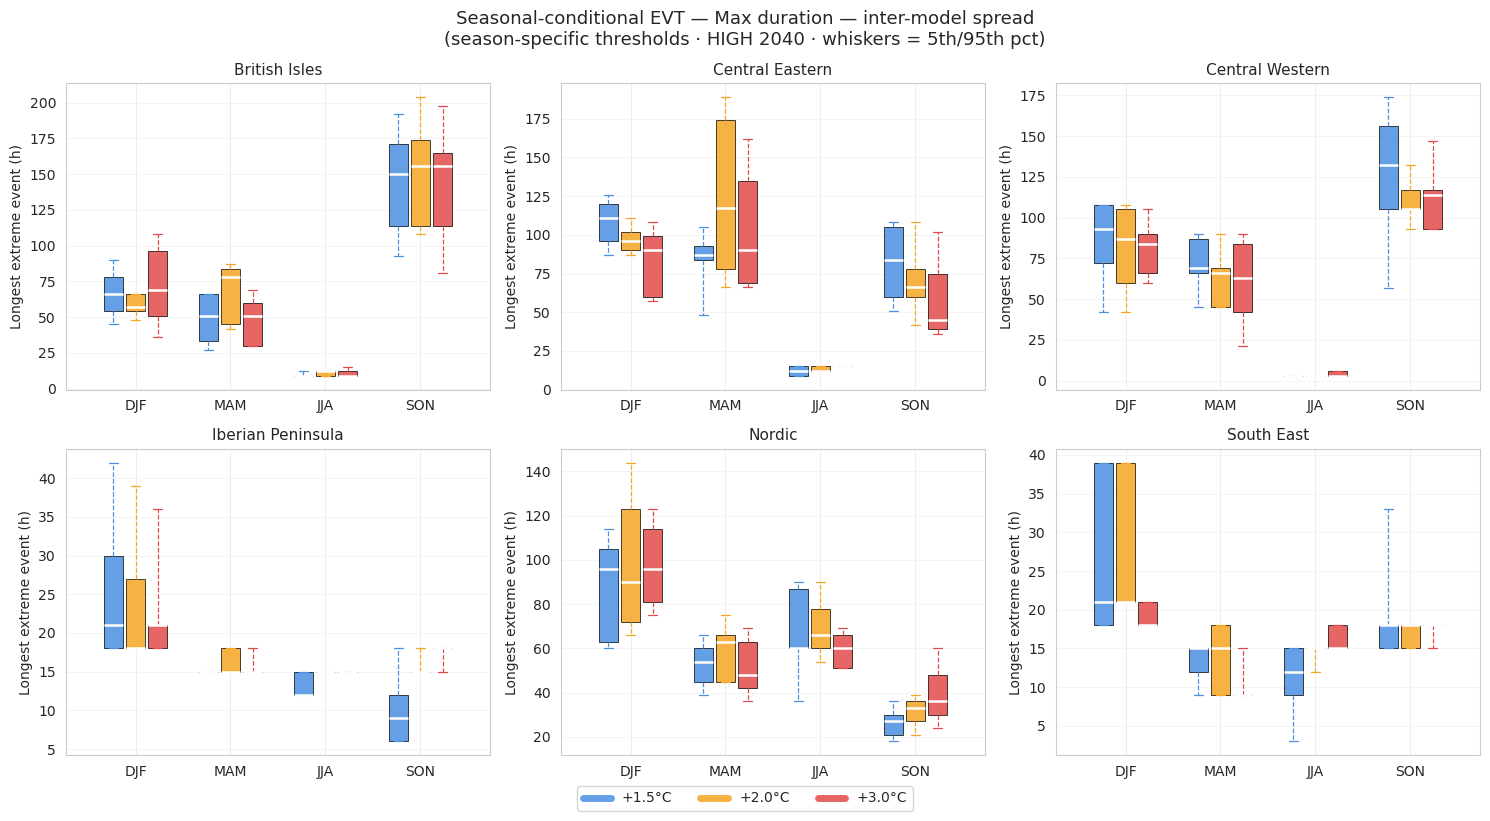

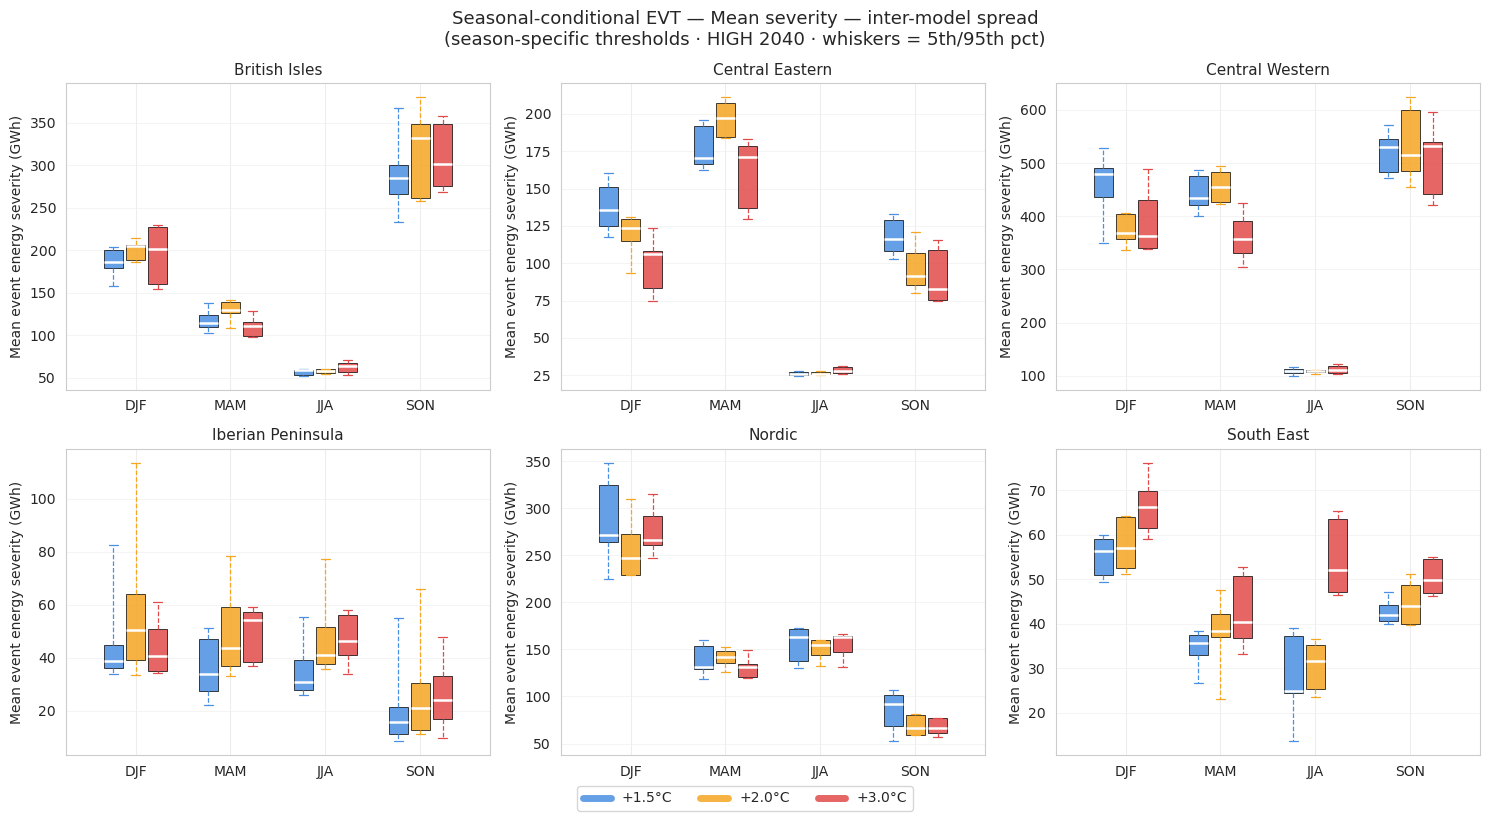

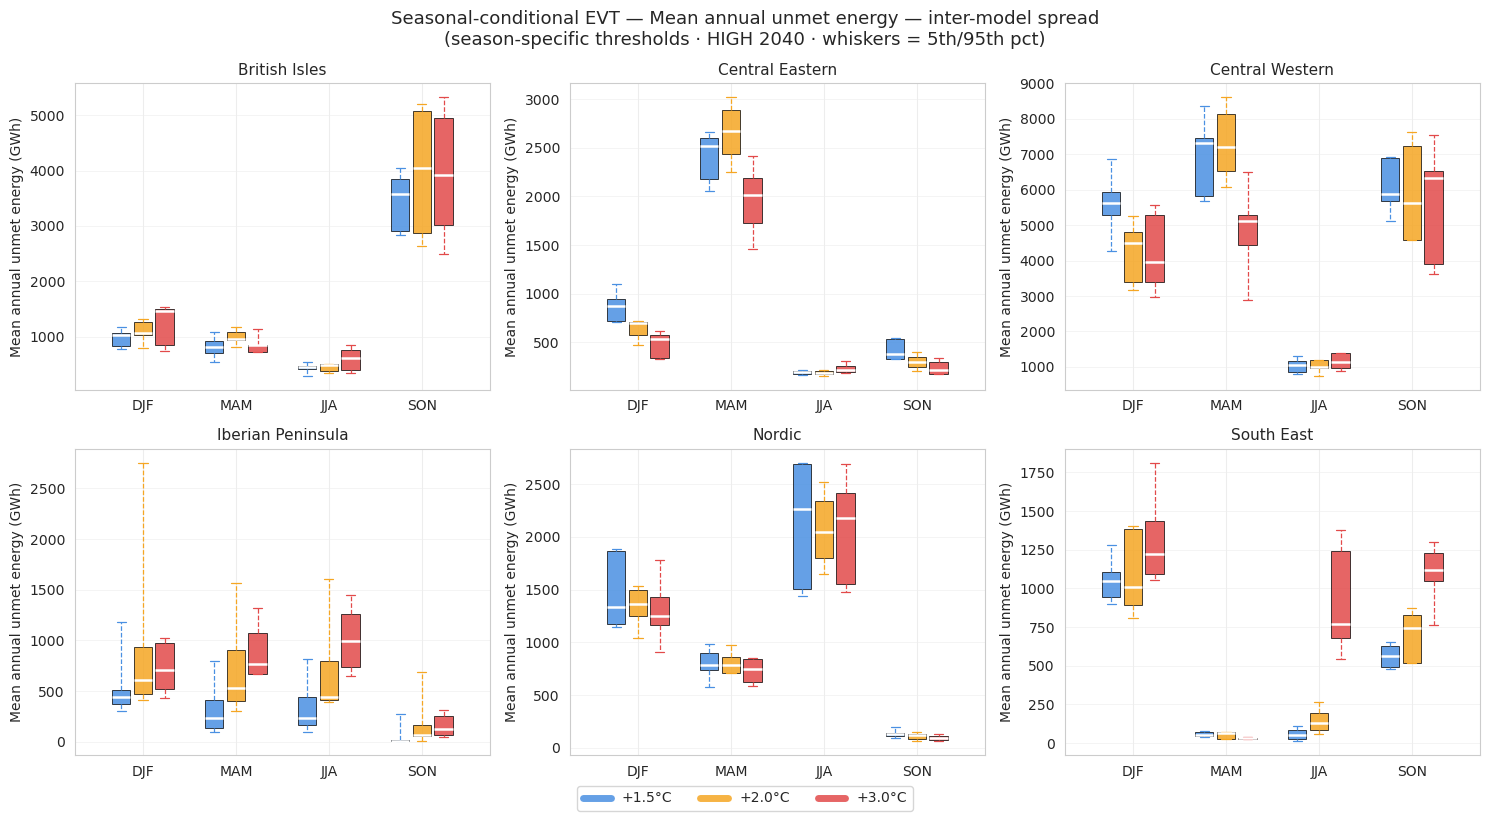

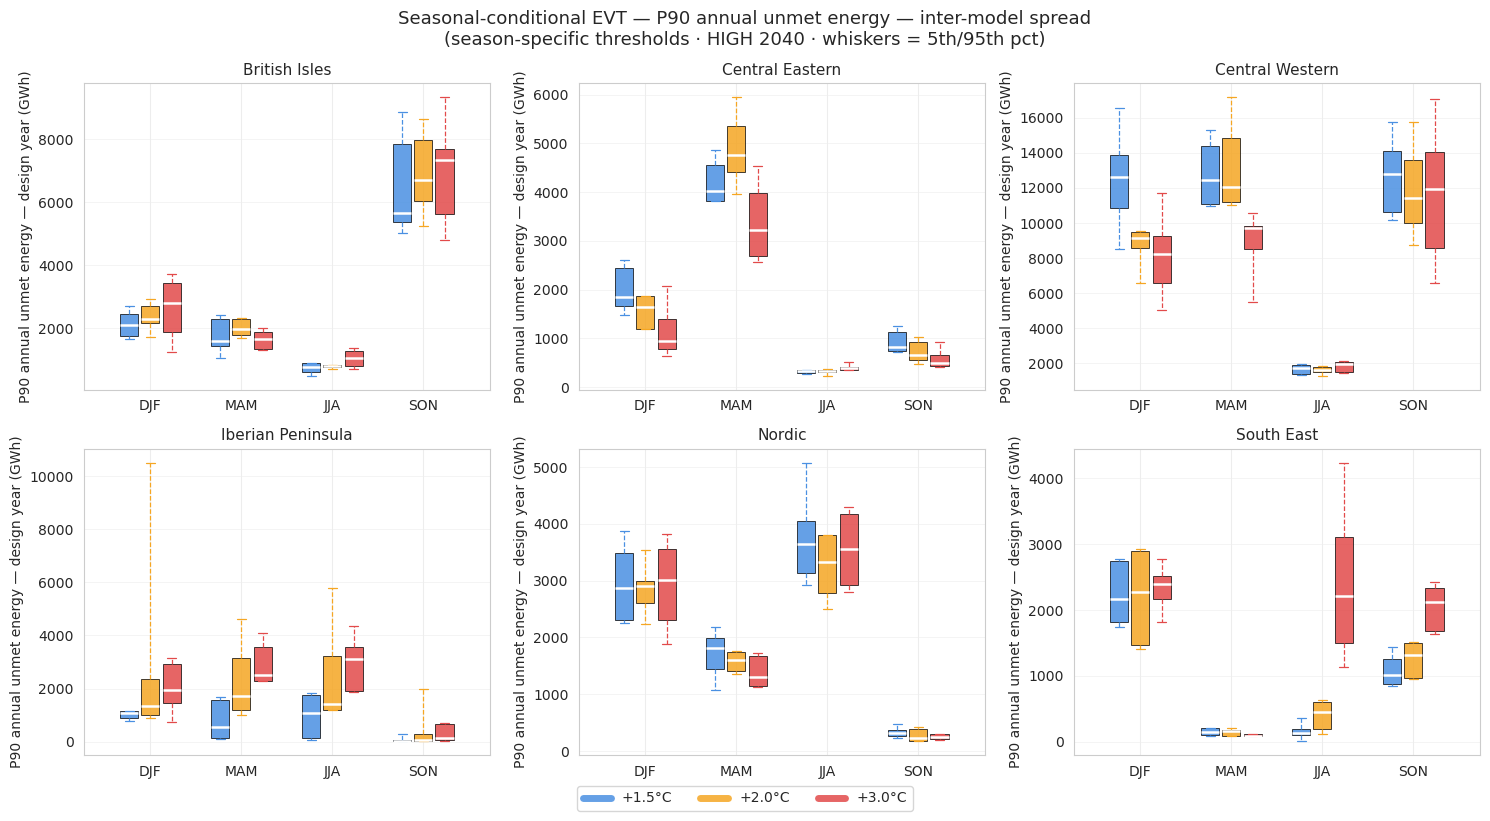

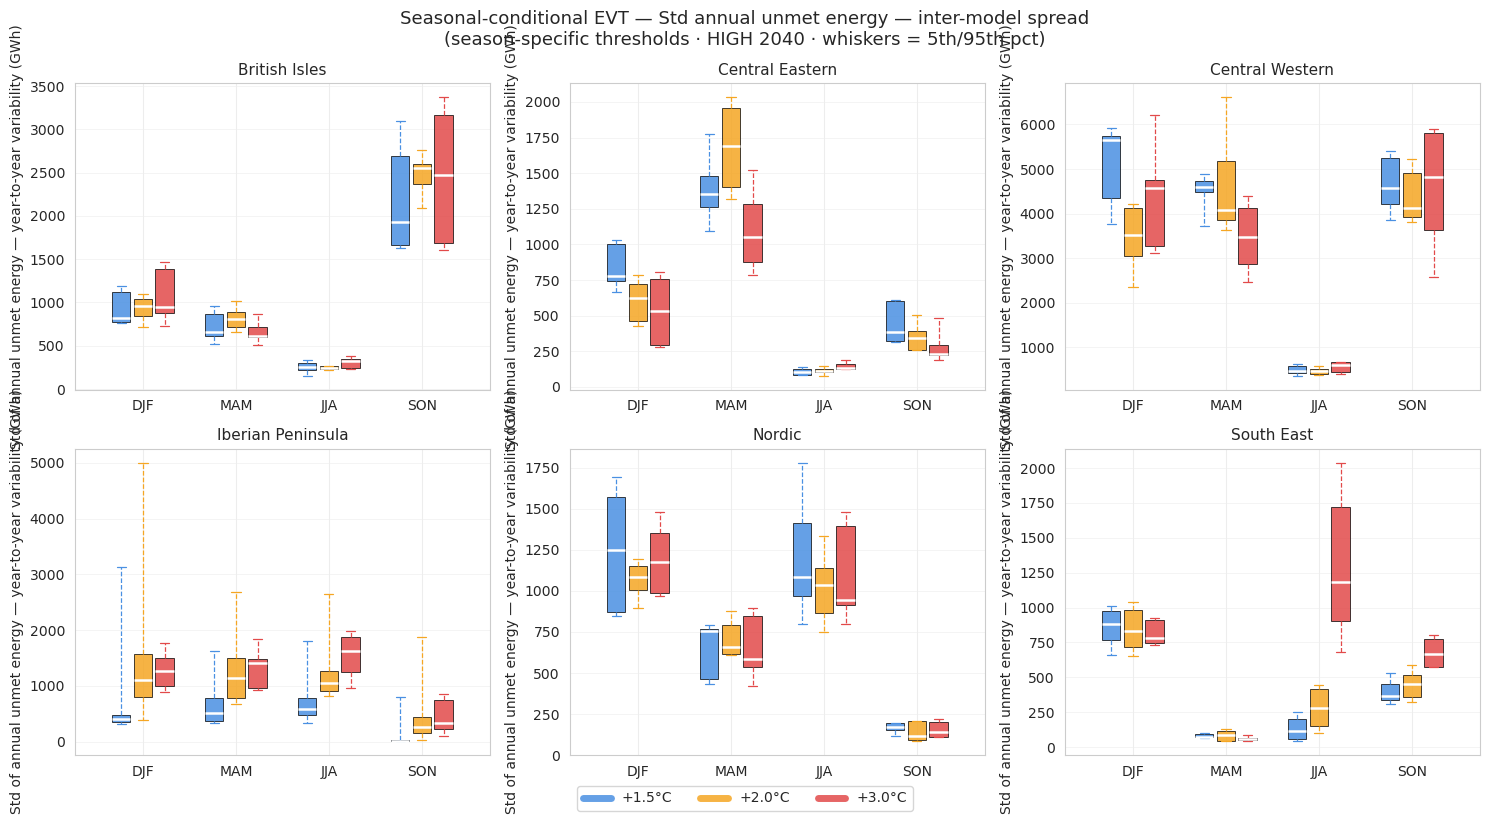

In [49]:
baseline_metrics = [
    ("Frequency",                        "Event count (whole period)",      "Frequency"),
    ("Avg_Duration_Hours",               "Mean event duration (h)",         "Mean duration"),
    ("Max_Duration_Hours", "Longest extreme event (h)", "Max duration"),
    ("Avg_Energy_Severity_GWh",          "Mean event energy severity (GWh)", "Mean severity"),
    ("Total_Annual_Energy_Severity_GWh", "Mean annual unmet energy (GWh)", "Mean annual unmet energy"),
    ("P90_Annual_Energy_Severity_GWh",   "P90 annual unmet energy — design year (GWh)", "P90 annual unmet energy"),
    ("Std_Annual_Energy_Severity_GWh",   "Std of annual unmet energy — year-to-year variability (GWh)", "Std annual unmet energy"),
]

plot_seasonal_conditional_metrics(
    df_seasonal_evt,
    metrics=baseline_metrics,
    zones=zones,
    period_defs=period_defs,
    season_order=season_order,
    period_colors=period_colors,
    supply_scenario=supply_scenario,
    supply_year=supply_year,
)


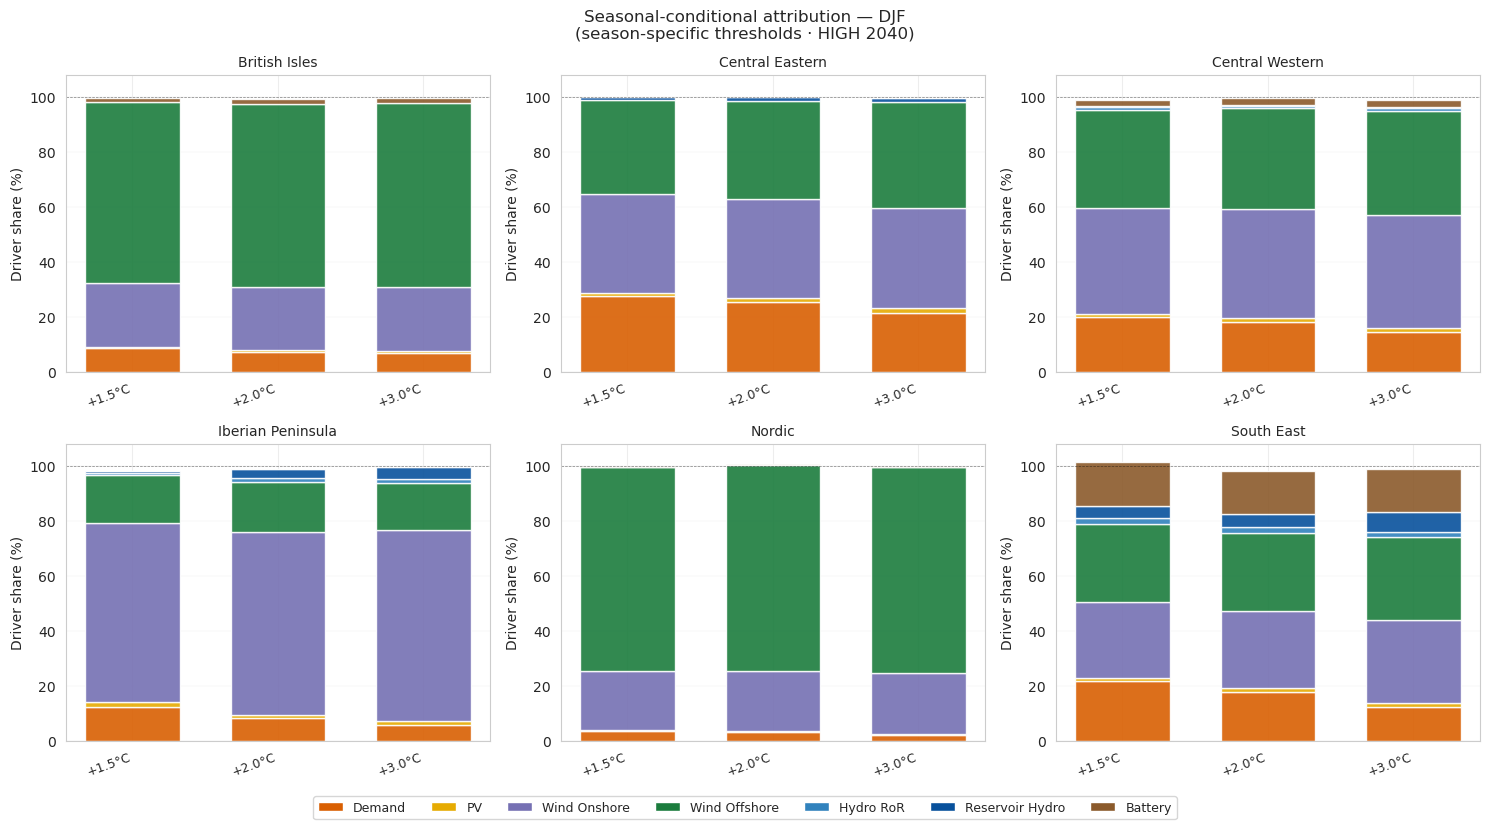

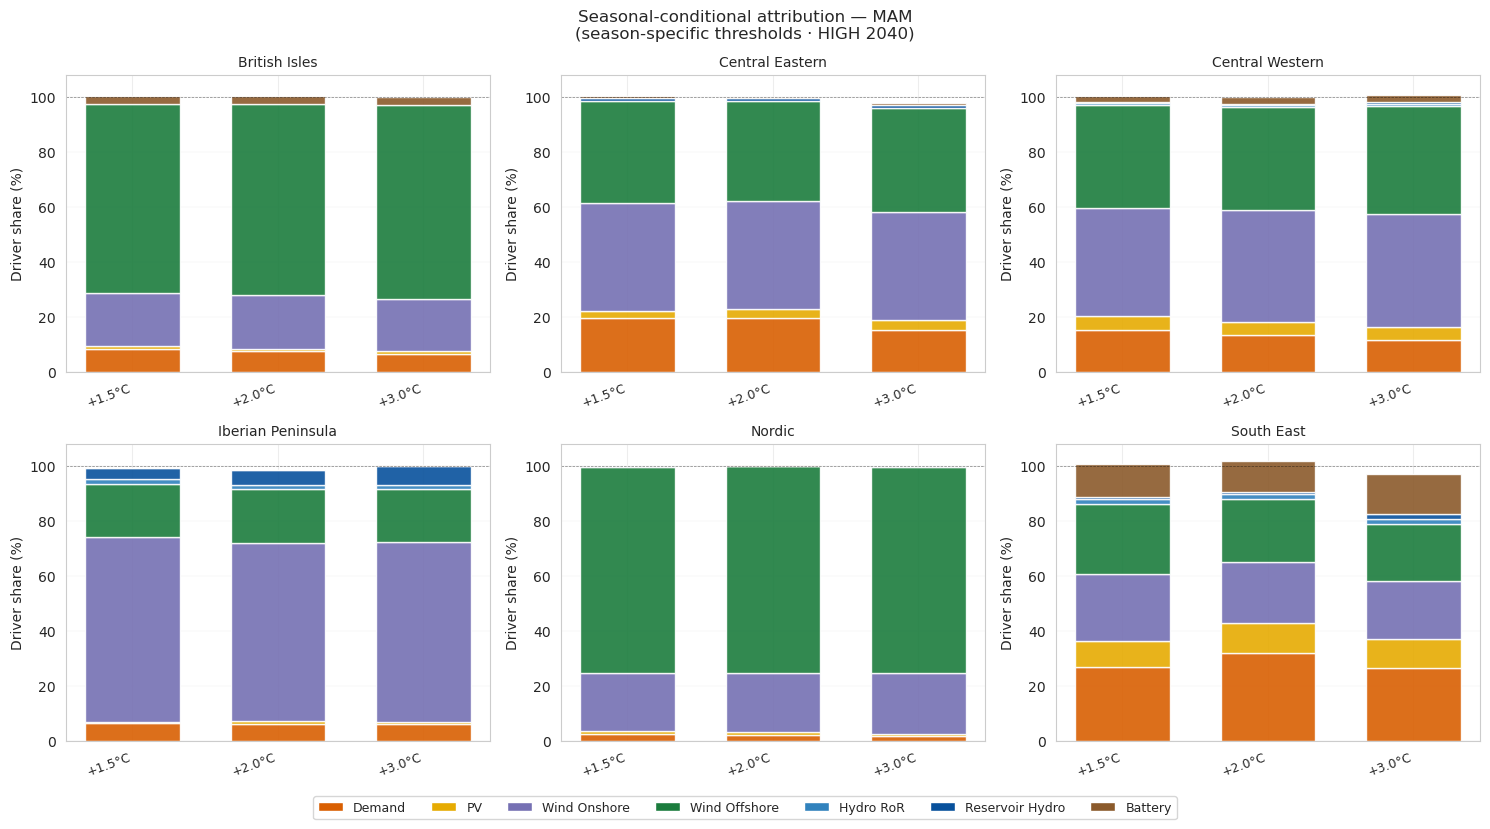

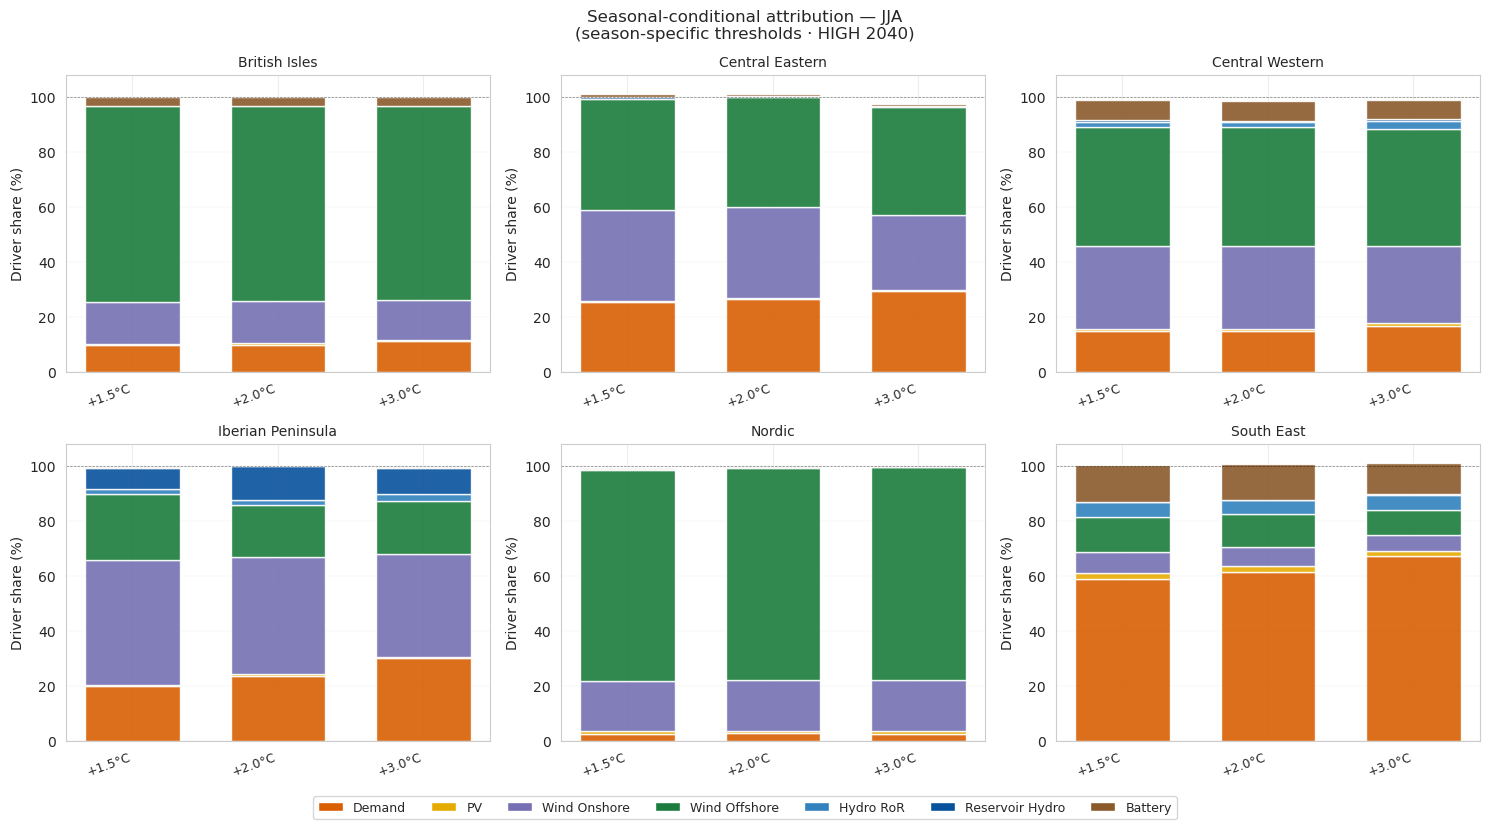

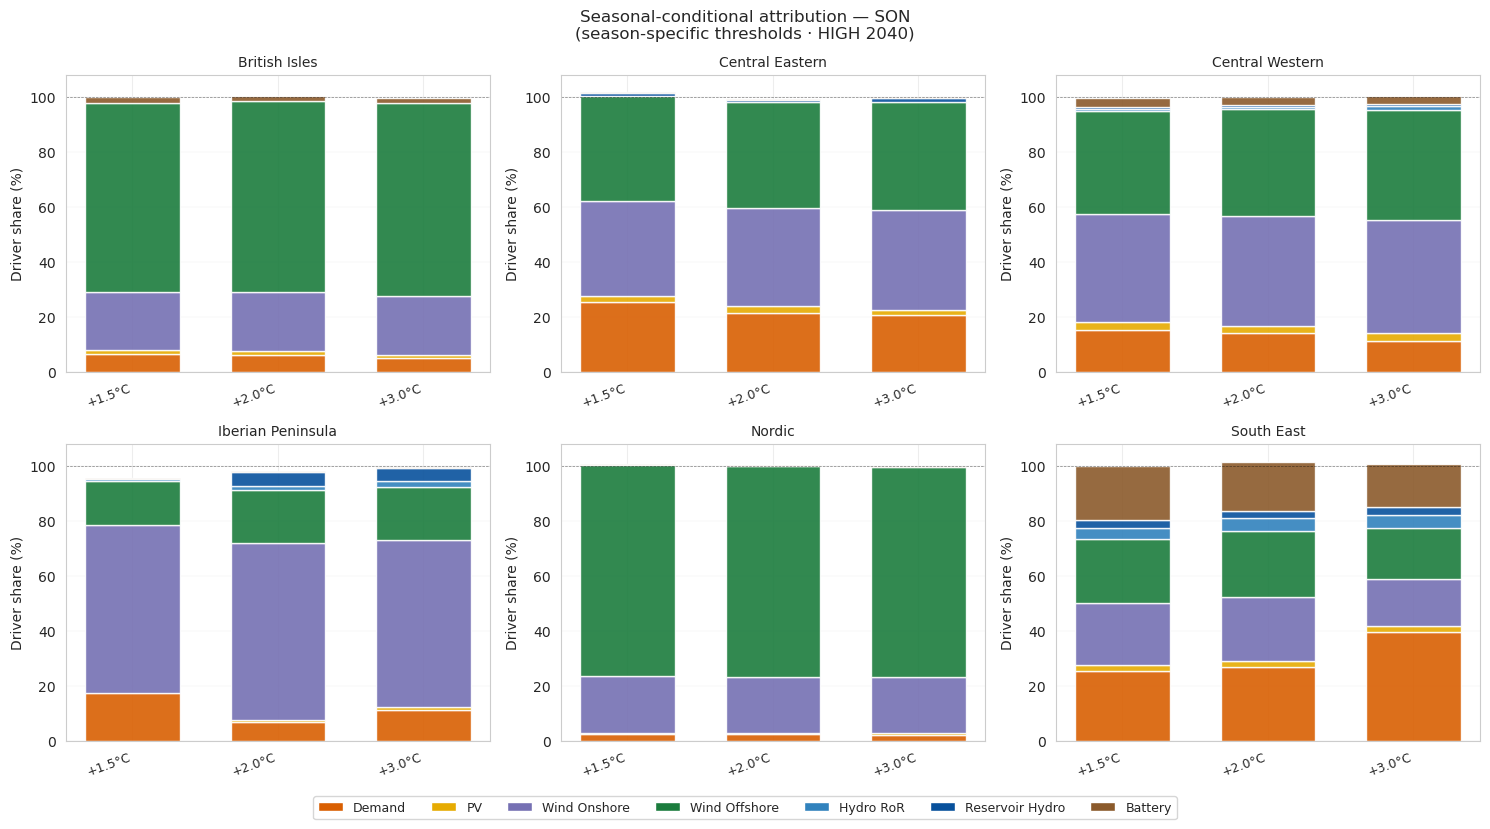

In [50]:
plot_seasonal_attribution(
    df_seasonal_evt,
    zones=zones,
    season_order=season_order,
    period_defs=period_defs,
    driver_cols=driver_cols,
    driver_palette=driver_palette,
    supply_scenario=supply_scenario,
    supply_year=supply_year,
)


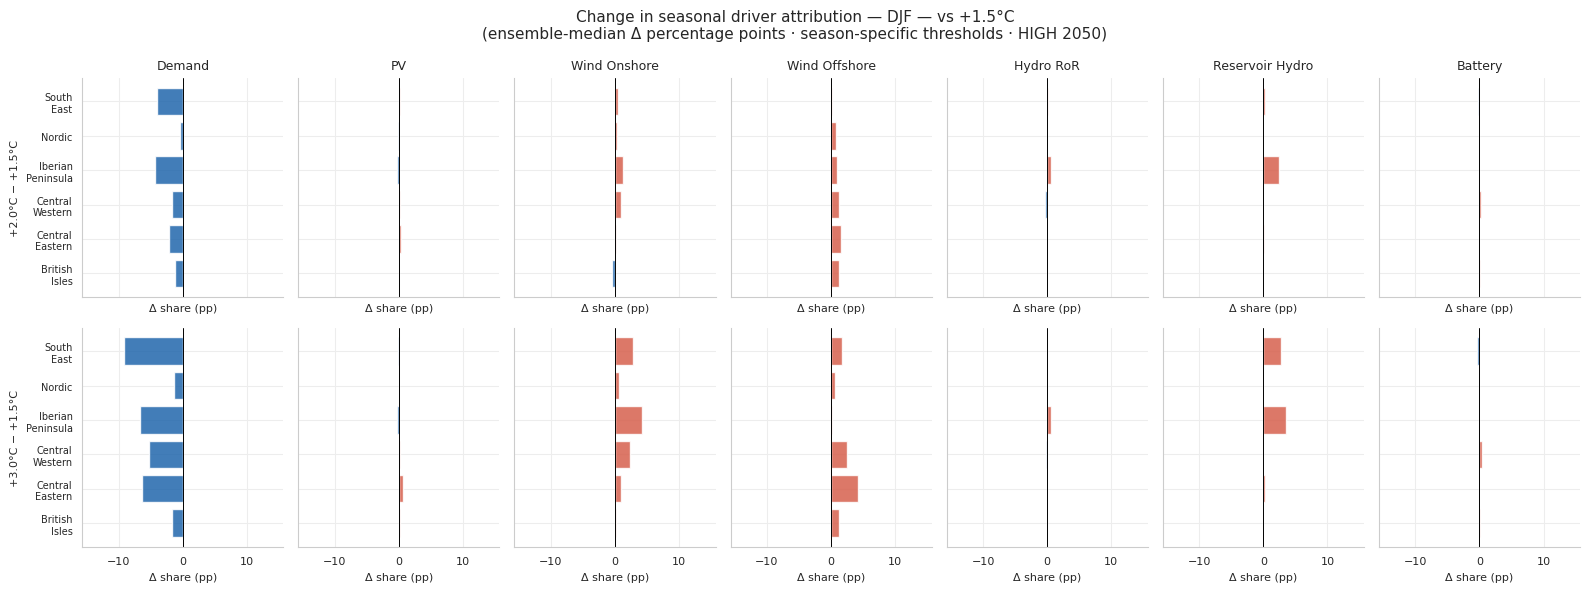

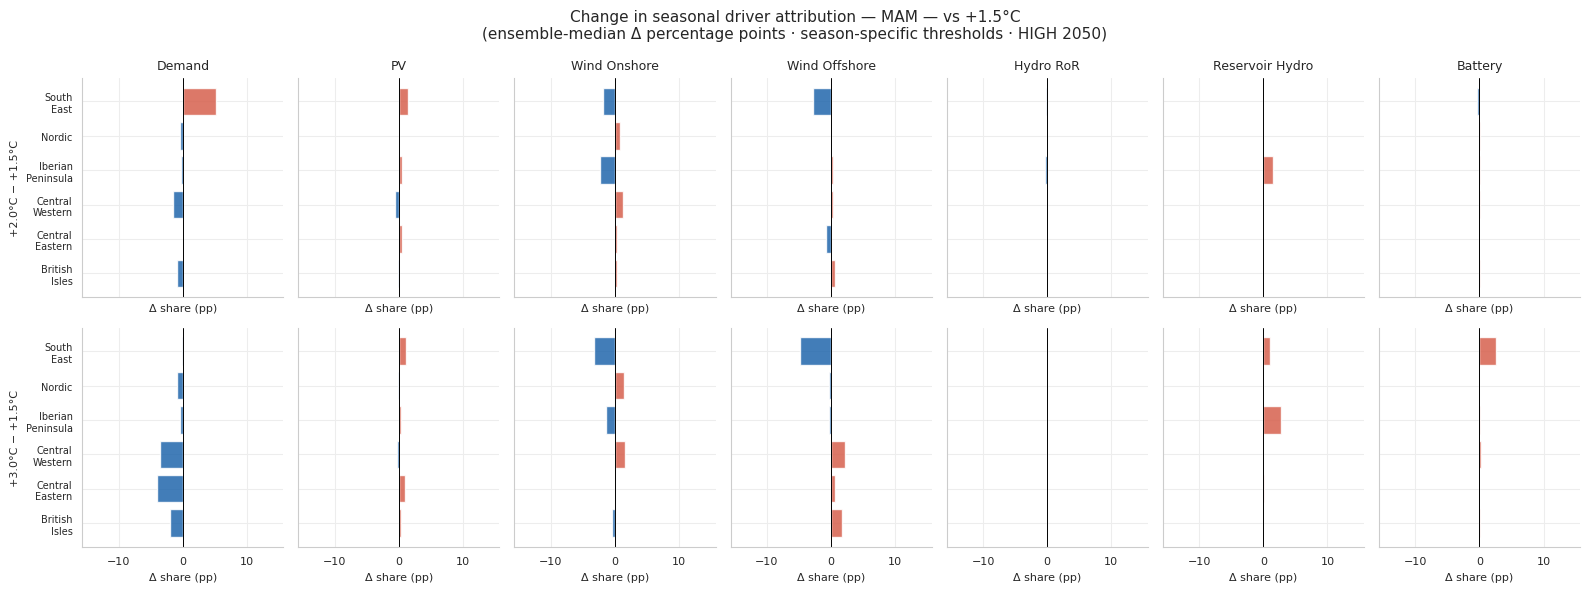

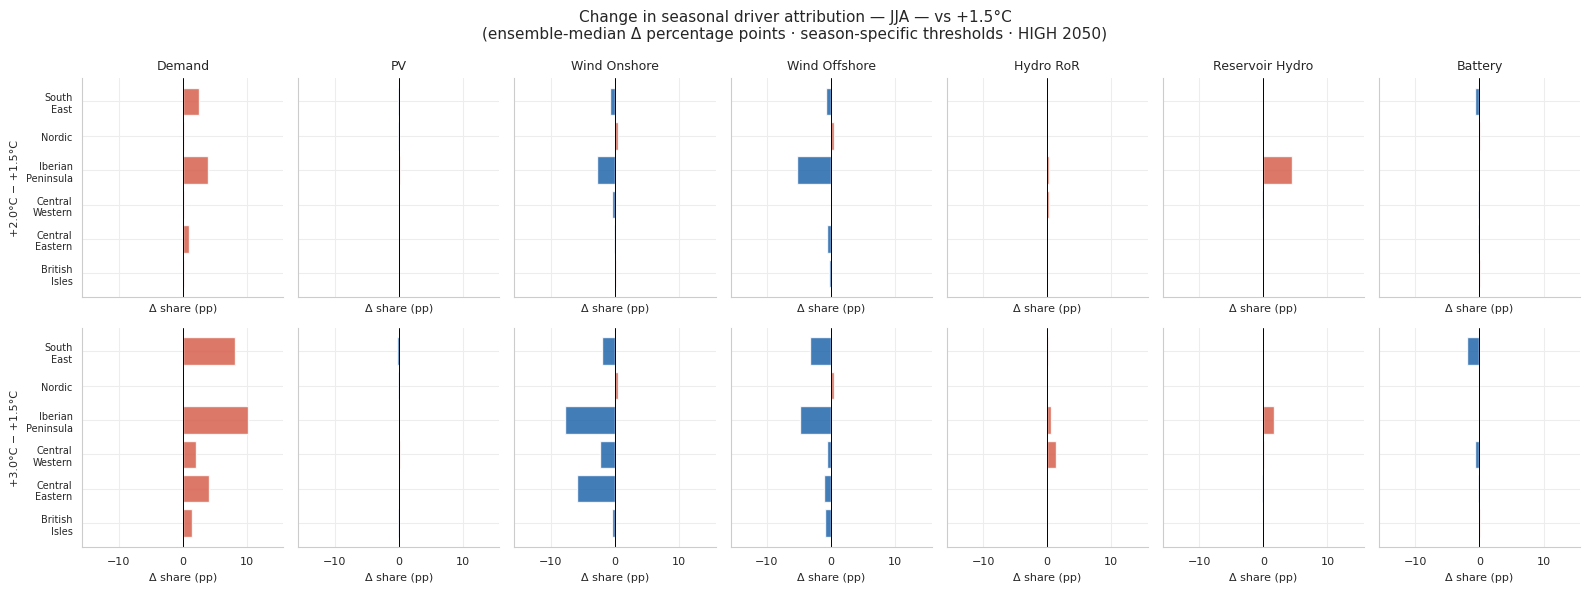

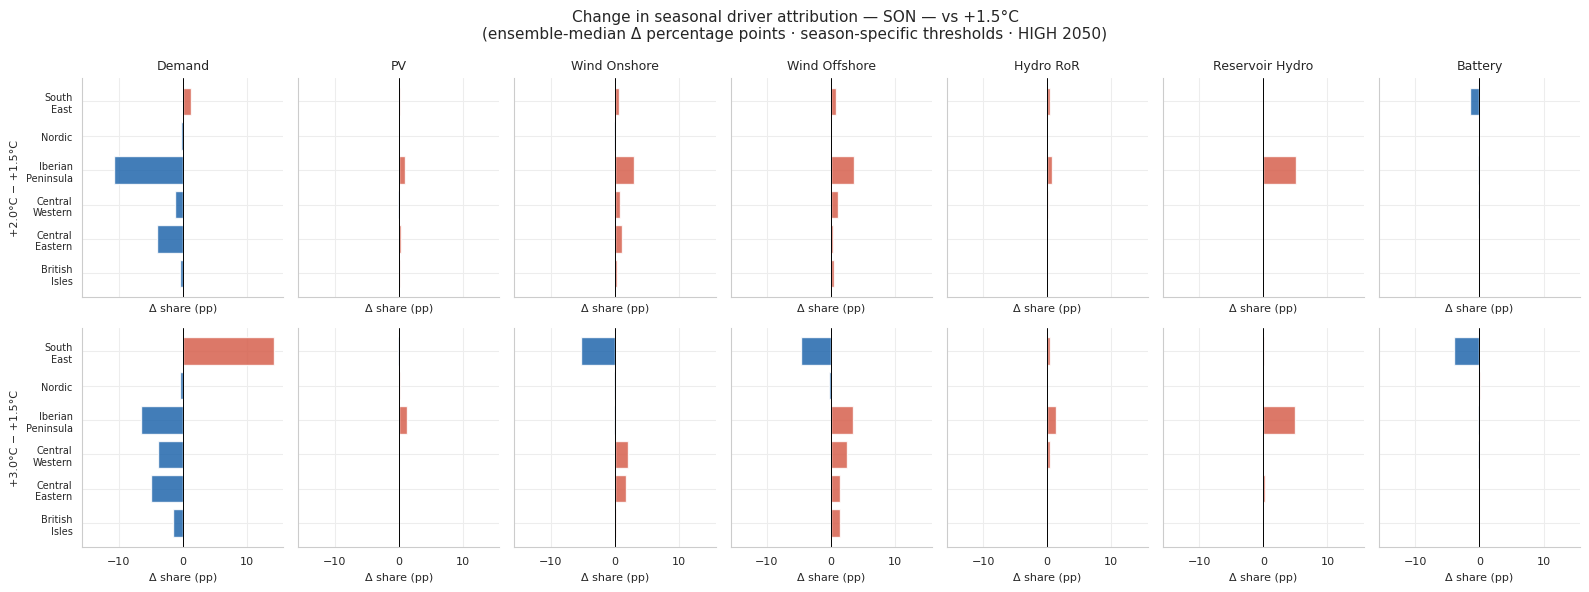

In [51]:
plot_seasonal_attribution_change(
    df_seasonal_evt,
    zones=zones,
    season_order=season_order,
    period_defs=period_defs,
    driver_cols=driver_cols,
    reference_period_name=None,  # defaults to first period
    supply_scenario=supply_scenario,
    supply_year=demand_year,
    share_x_across_seasons=True
)

## Seasonal driver anomaly distributions

Signed GWh anomaly per component during EVT events, broken down by season.

- **Per-period figures**: one figure per warming level, `x = Component, hue = Season` — shows how each driver's contribution varies across seasons within a given warming level.
- **Per-season figures**: one figure per season, `x = Component, hue = Period` — shows how the warming level shifts each driver's anomaly within that season.

Sign convention: demand anomaly positive (excess demand above baseline); generation and flexibility anomalies negative (shortfall / under-dispatch below baseline).

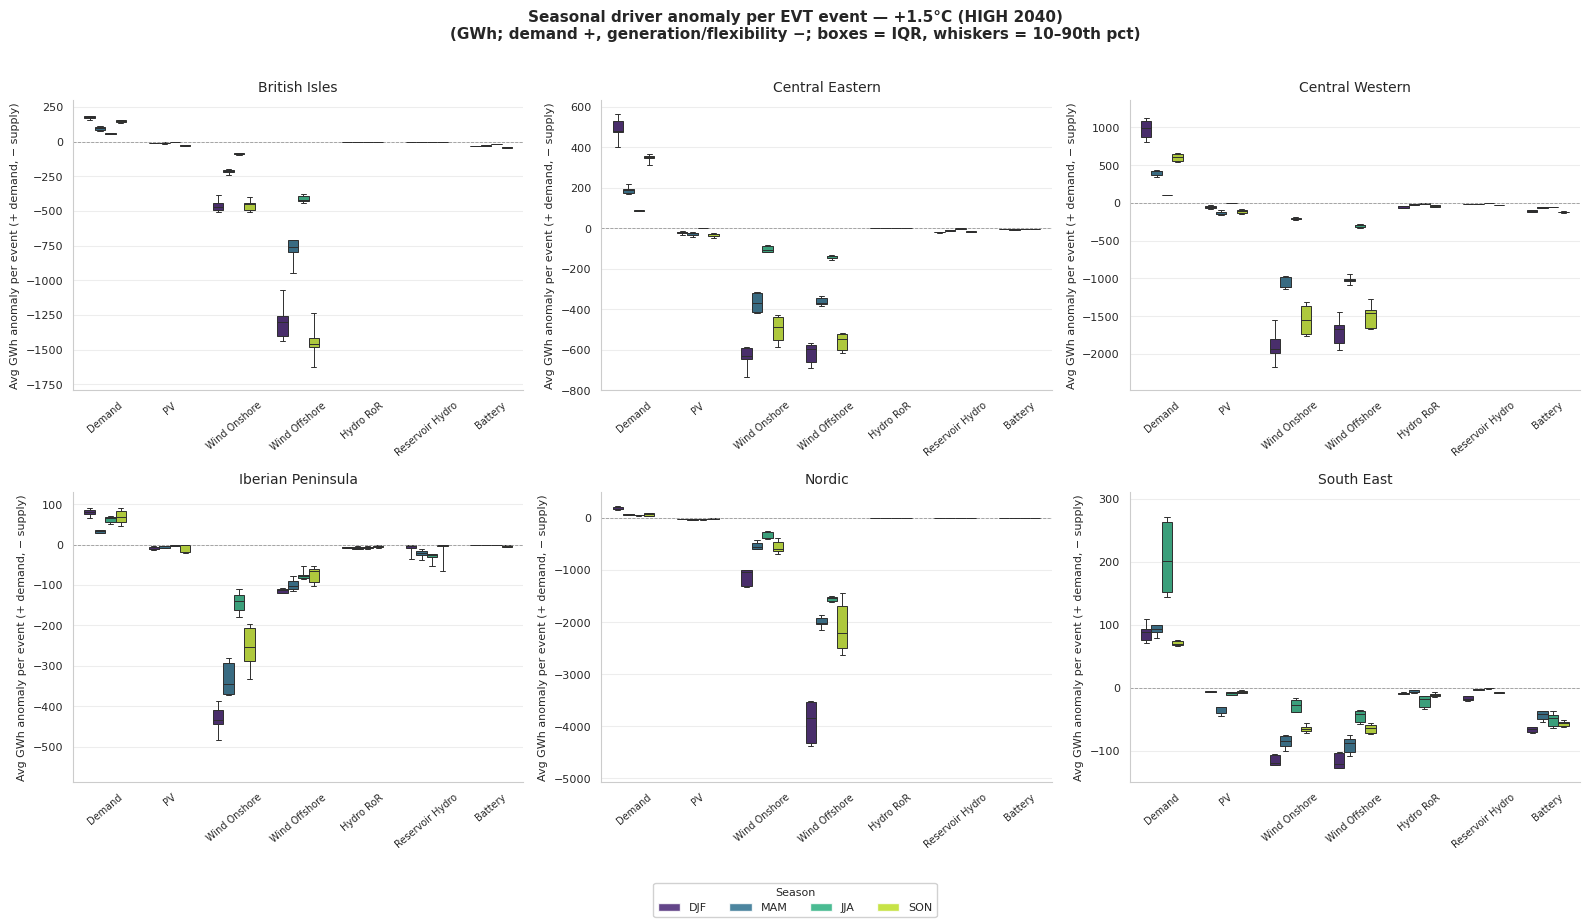

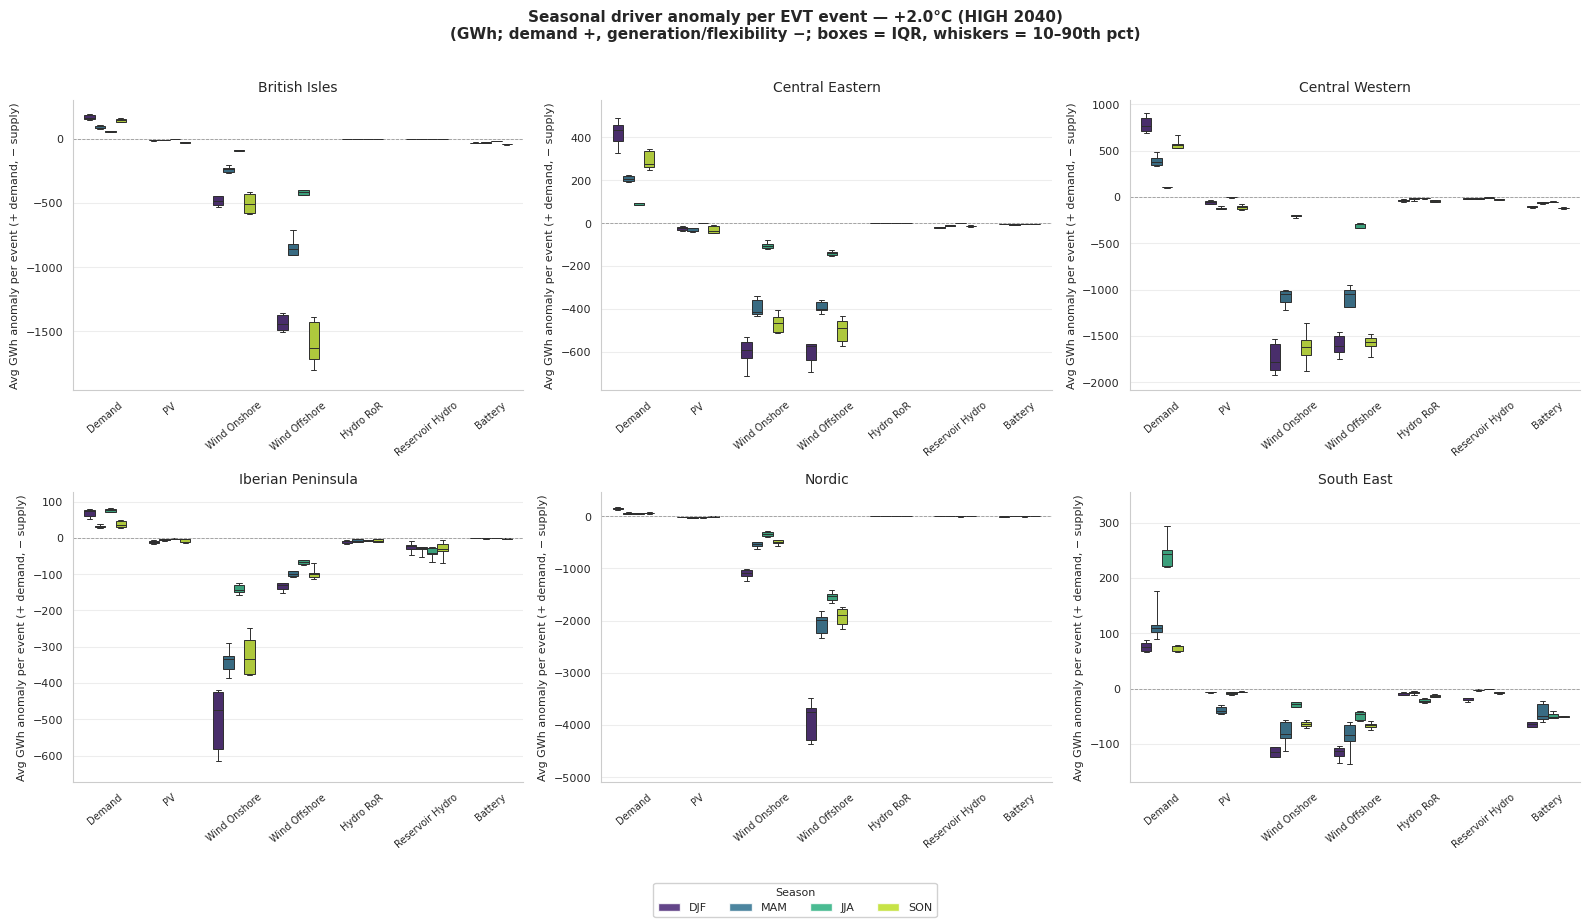

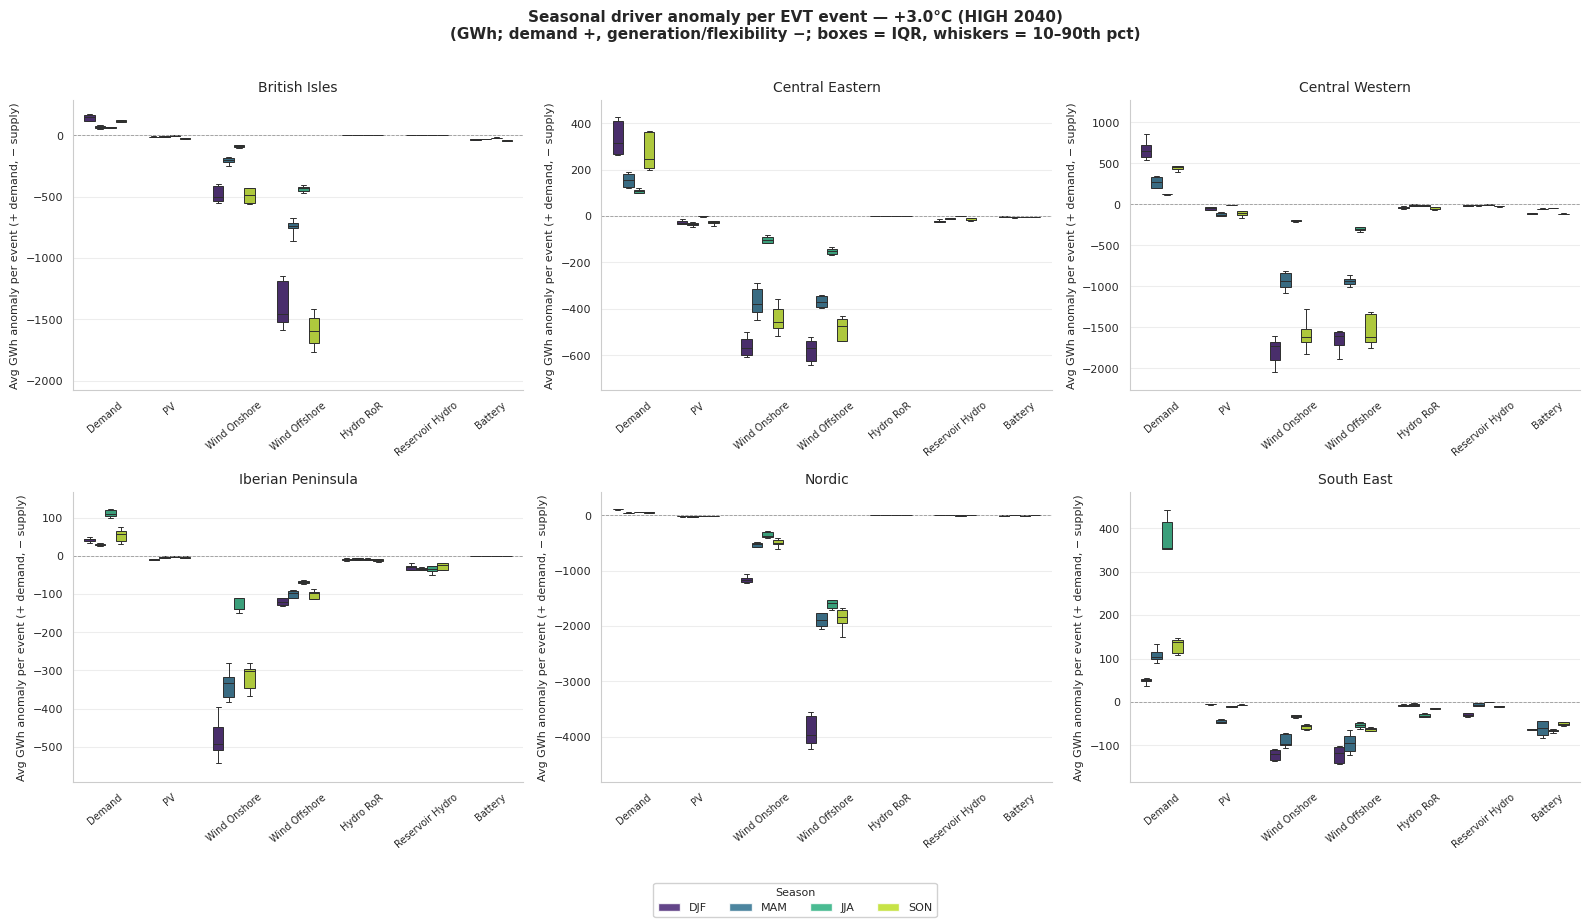

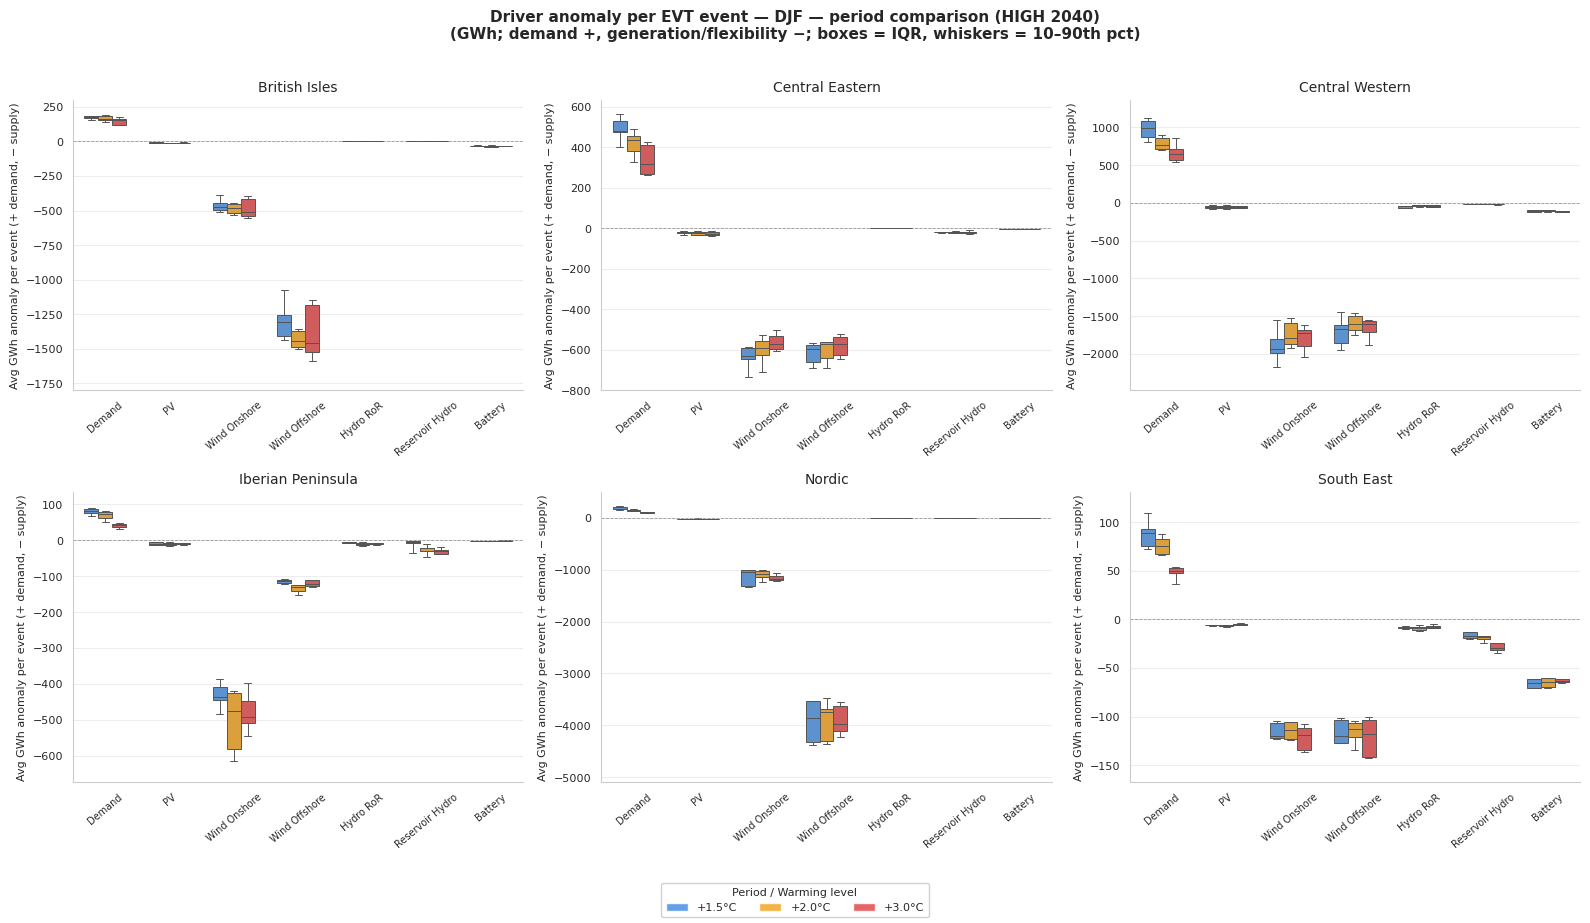

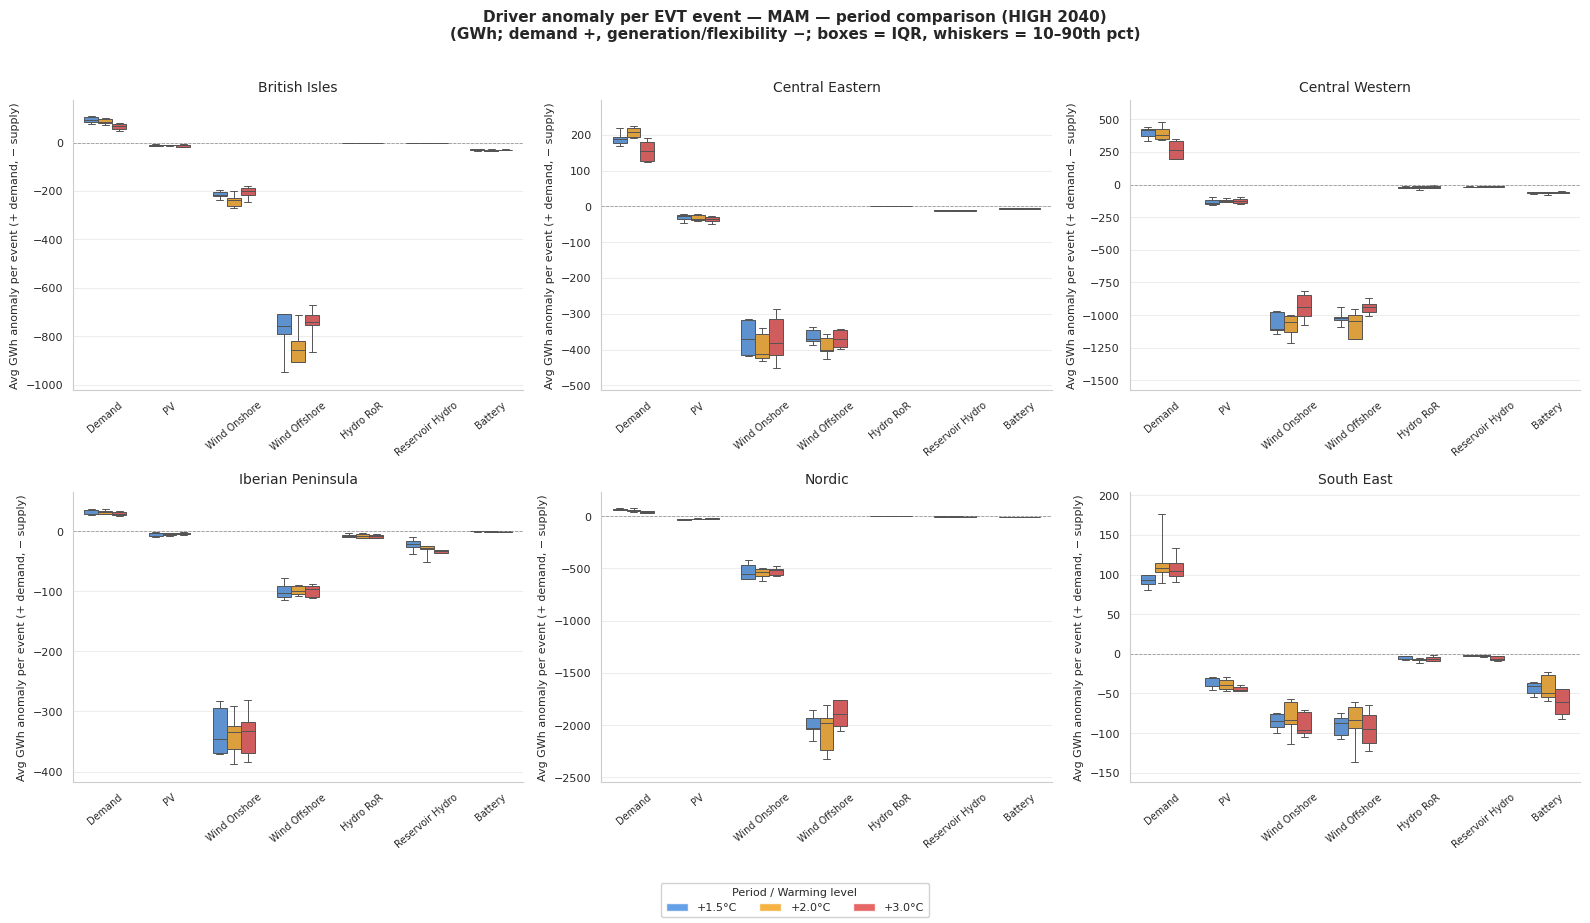

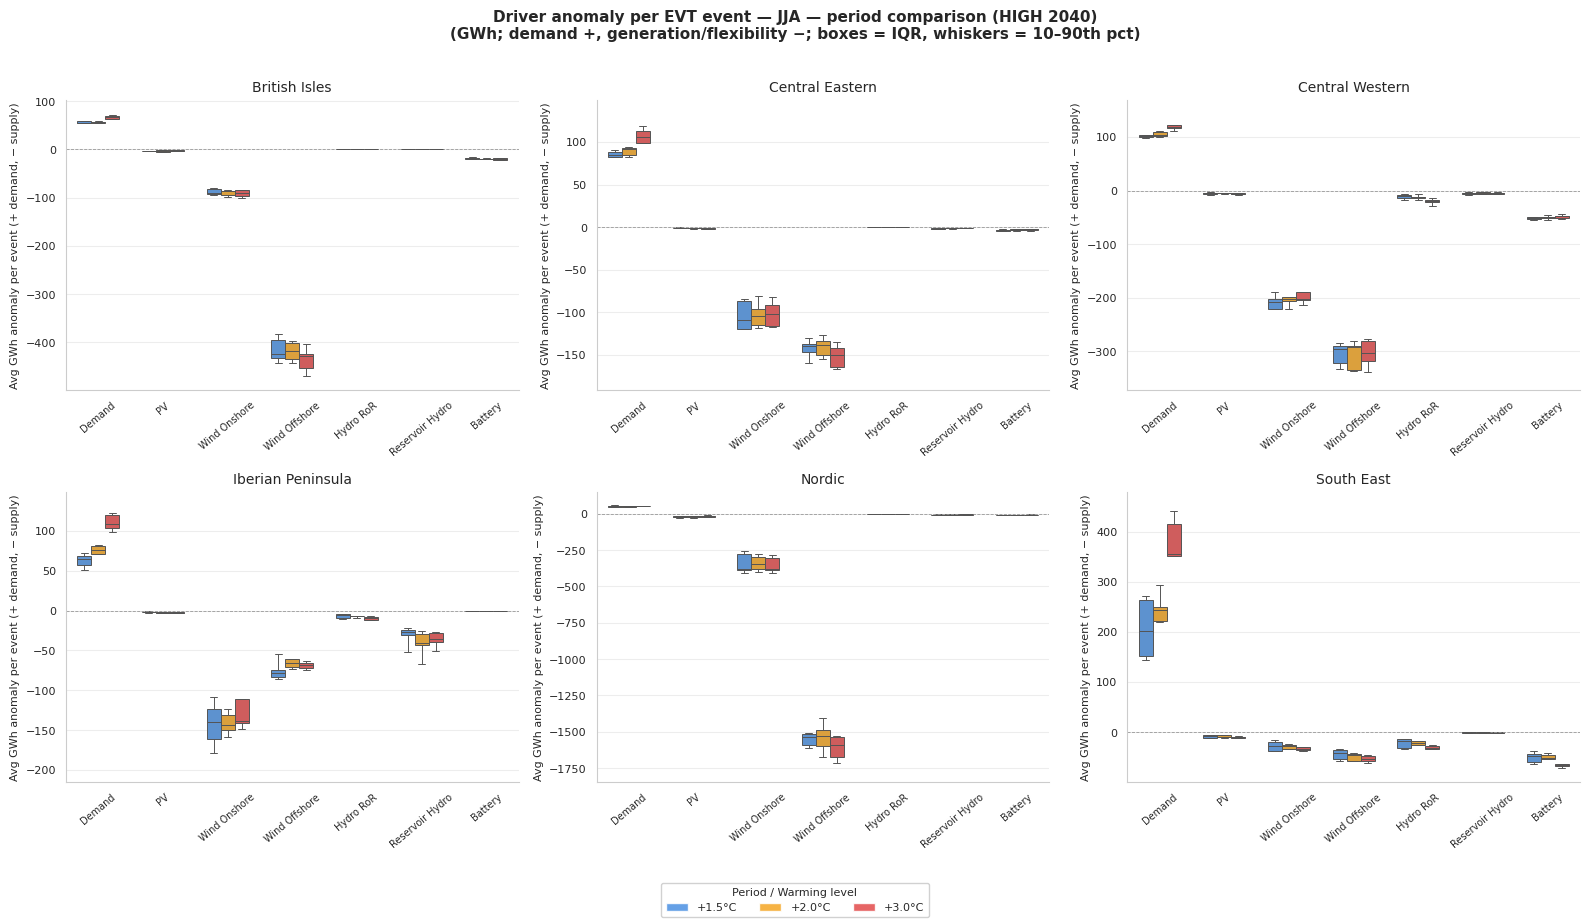

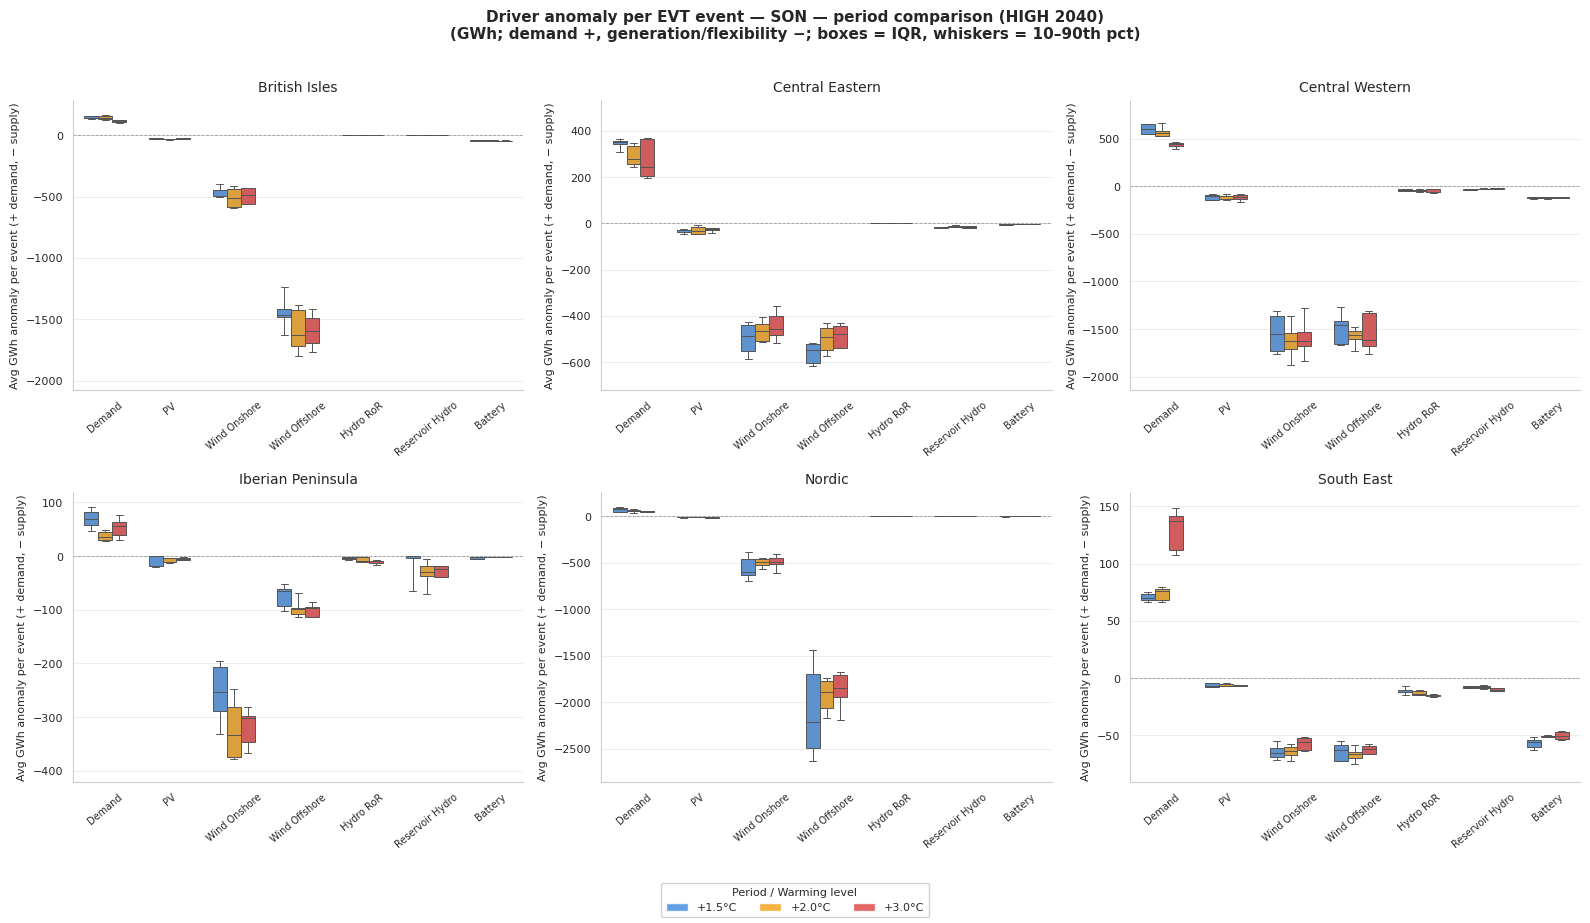

In [52]:
plot_seasonal_component_anomaly_distributions(
    df_seasonal_evt,
    zones=zones,
    season_order=season_order,
    period_defs=period_defs,
    component_cols=anomaly_component_cols,
    component_palette=driver_palette,
    period_palette=period_colors,
    supply_scenario=supply_scenario,
    supply_year=supply_year,
)

## Diurnal profile of extreme events

At what time of day do extreme residual-load events preferentially occur, and how does that interact with PV generation?

Two complementary views:
1. **Event distribution by hour** — for each season, the percentage of all event timesteps falling in each hour of the day.
2. **PV context by zone** — mean PV generation during event timesteps (solid) vs the reference-period climatological PV (dashed), averaged over the season's months for each hour.  The dashed line uses the same `(month, hour)` baseline as the driver-attribution computation, so the gap between the two lines is directly comparable to the PV anomaly in the attribution plots.

In [53]:
df_diurnal = extract_event_diurnal_profiles(
    _cache_rl,
    _cache_comp,
    season_active_thresholds,
    period_defs,
    models,
    zones,
    season_order,
    season_months,
    cache_clim=_cache_clim,
    method=EVENT_DETECTION_METHOD,
)
print(
    f"df_diurnal: {df_diurnal.shape[0]} rows × {df_diurnal.shape[1]} columns  "
    f"[events={EVENT_DETECTION_METHOD}]"
)
df_diurnal.groupby(["season", "hour"])["pct_event_steps"].median().unstack("hour").round(2)

df_diurnal: 5184 rows × 13 columns  [events=spa]


hour,0,3,6,9,12,15,18,21
season,,,,,,,,
DJF,8.81,9.23,10.32,3.71,3.50,22.15,22.99,16.19
JJA,10.77,7.16,0.00,0.00,0.00,1.69,41.26,23.34
MAM,13.31,15.53,6.20,1.84,0.89,12.23,22.95,19.87
SON,8.05,8.50,5.93,2.90,4.75,22.75,23.61,16.20


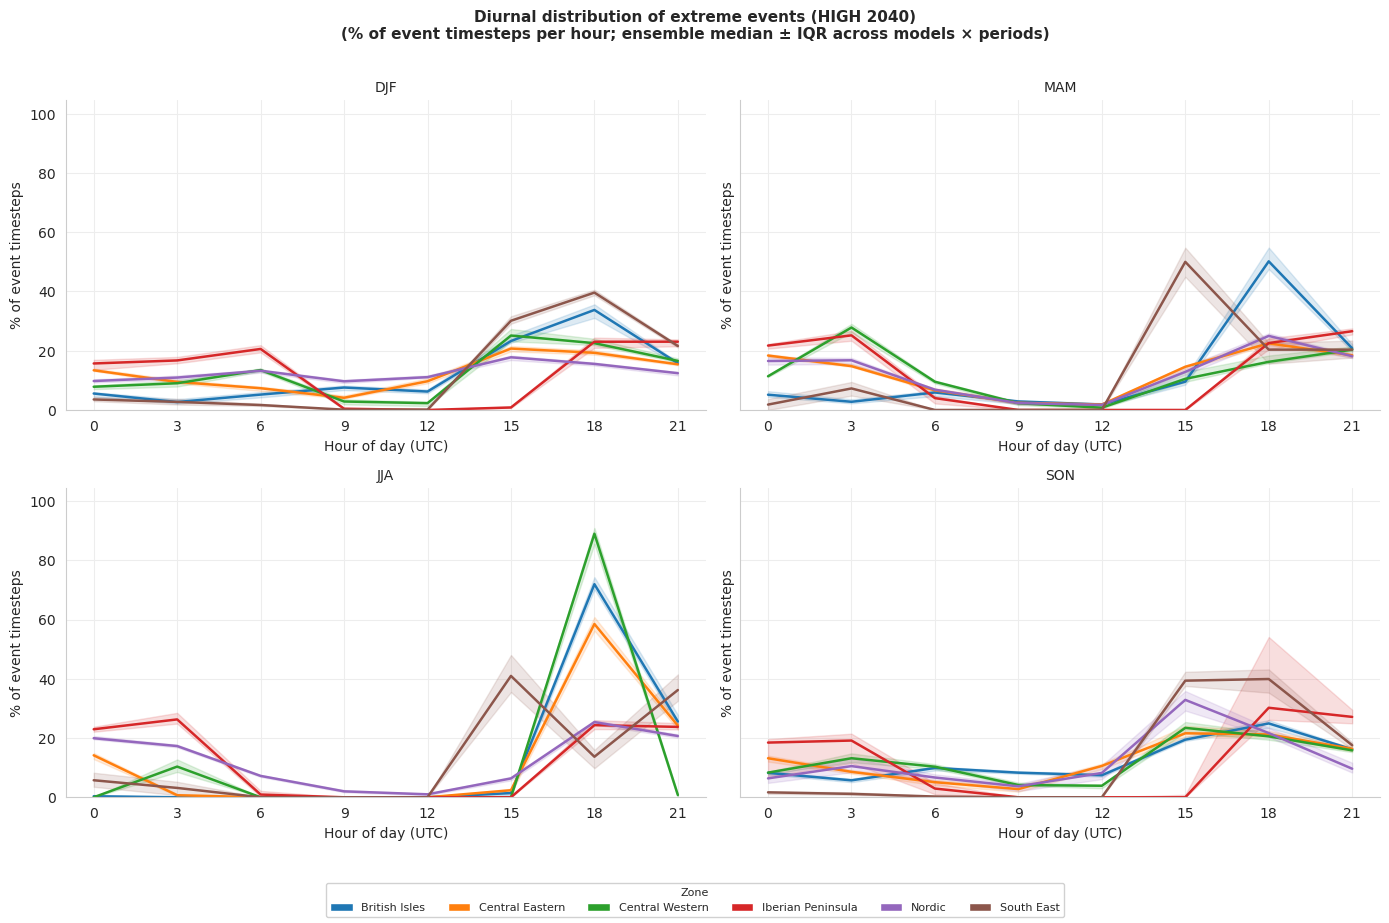

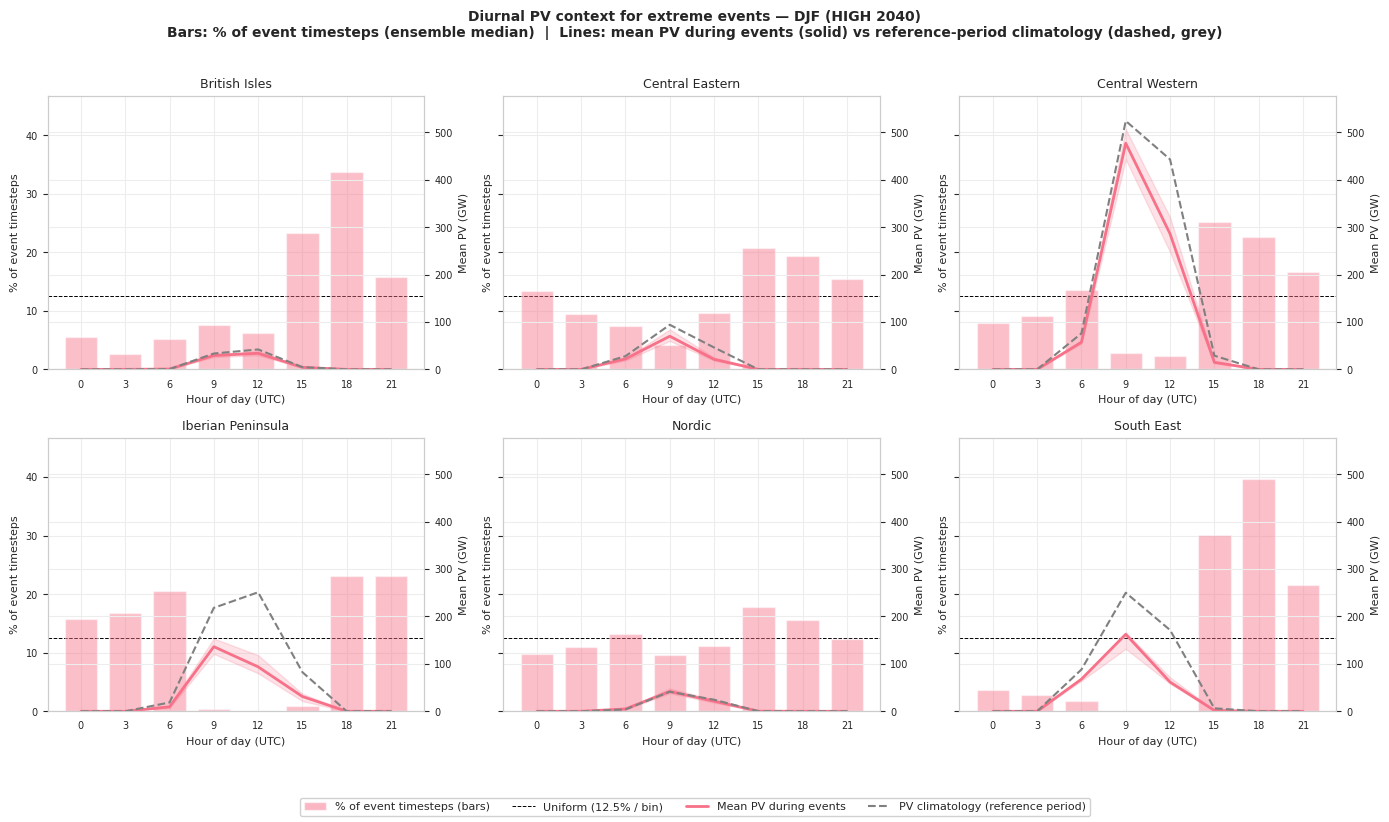

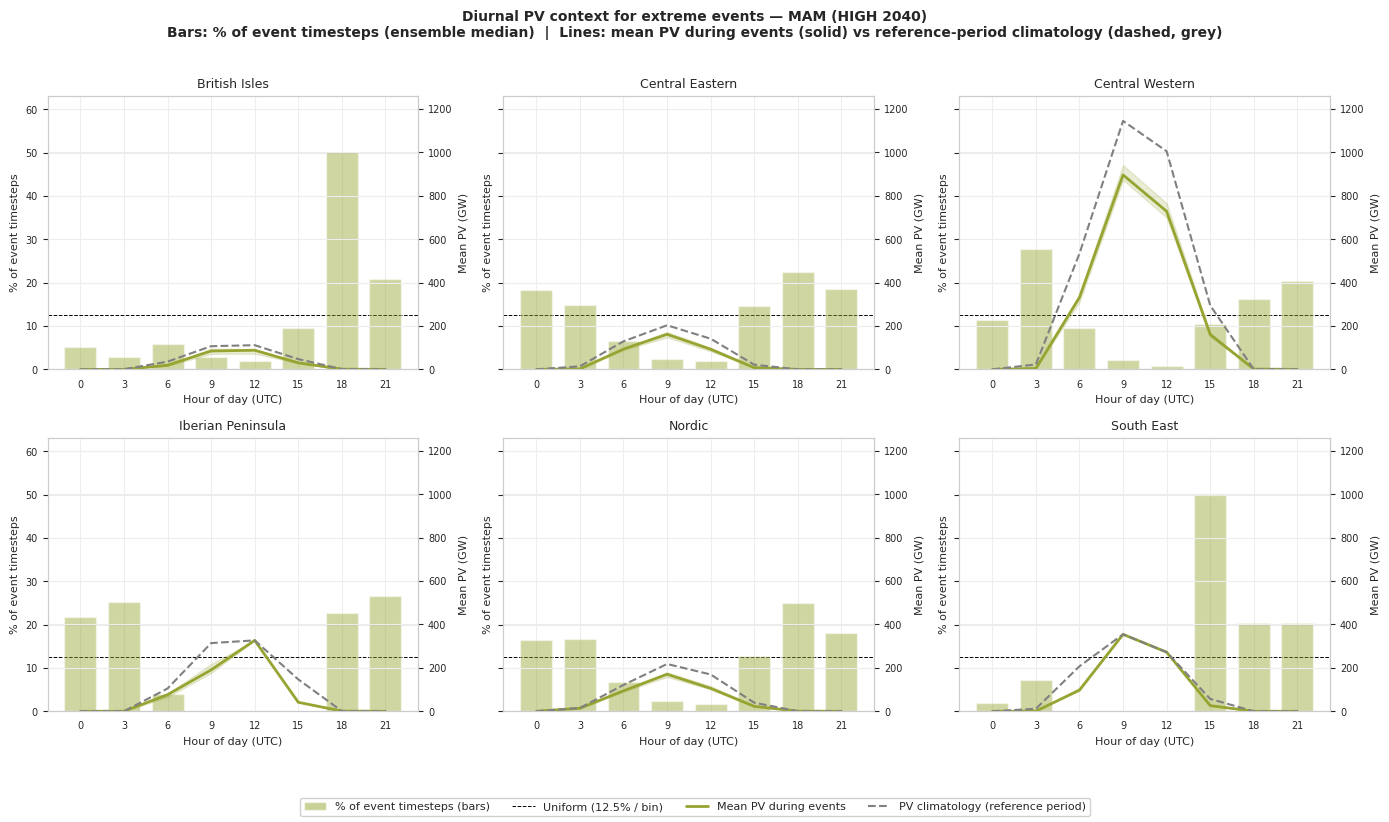

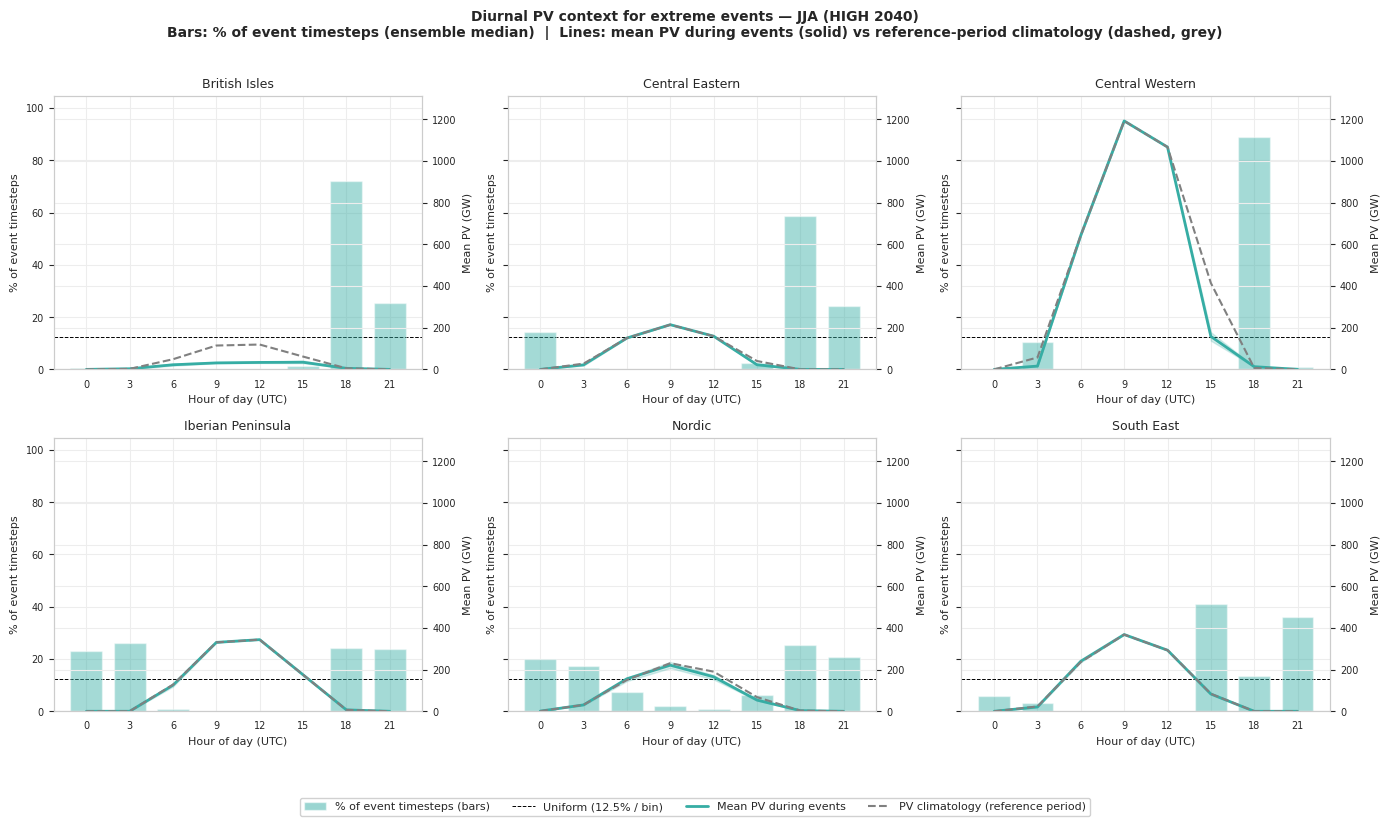

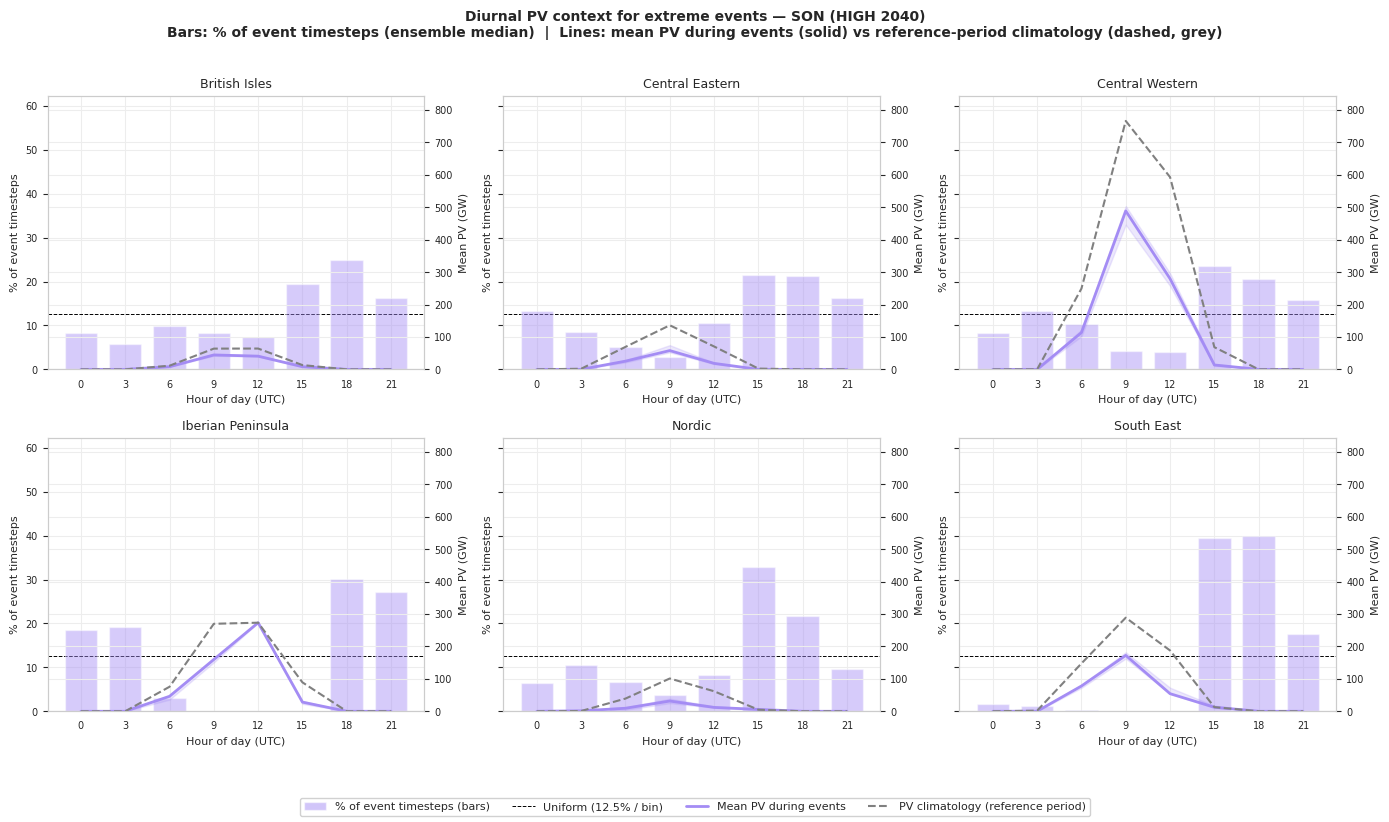

In [54]:
plot_event_diurnal_profile(
    df_diurnal,
    zones=zones,
    season_order=season_order,
    period_defs=period_defs,
    period_colors=period_colors,
    supply_scenario=supply_scenario,
    supply_year=supply_year,
)

## Seasonal decomposition of exceedances

Uses the **common annual threshold** (same for all seasons) to show which season
dominates absolute system-level stress. This is complementary to the season-specific
analysis above: it answers *when* extremes occur, not *how each season's tail evolves*.

df_seasonal: (162, 7)


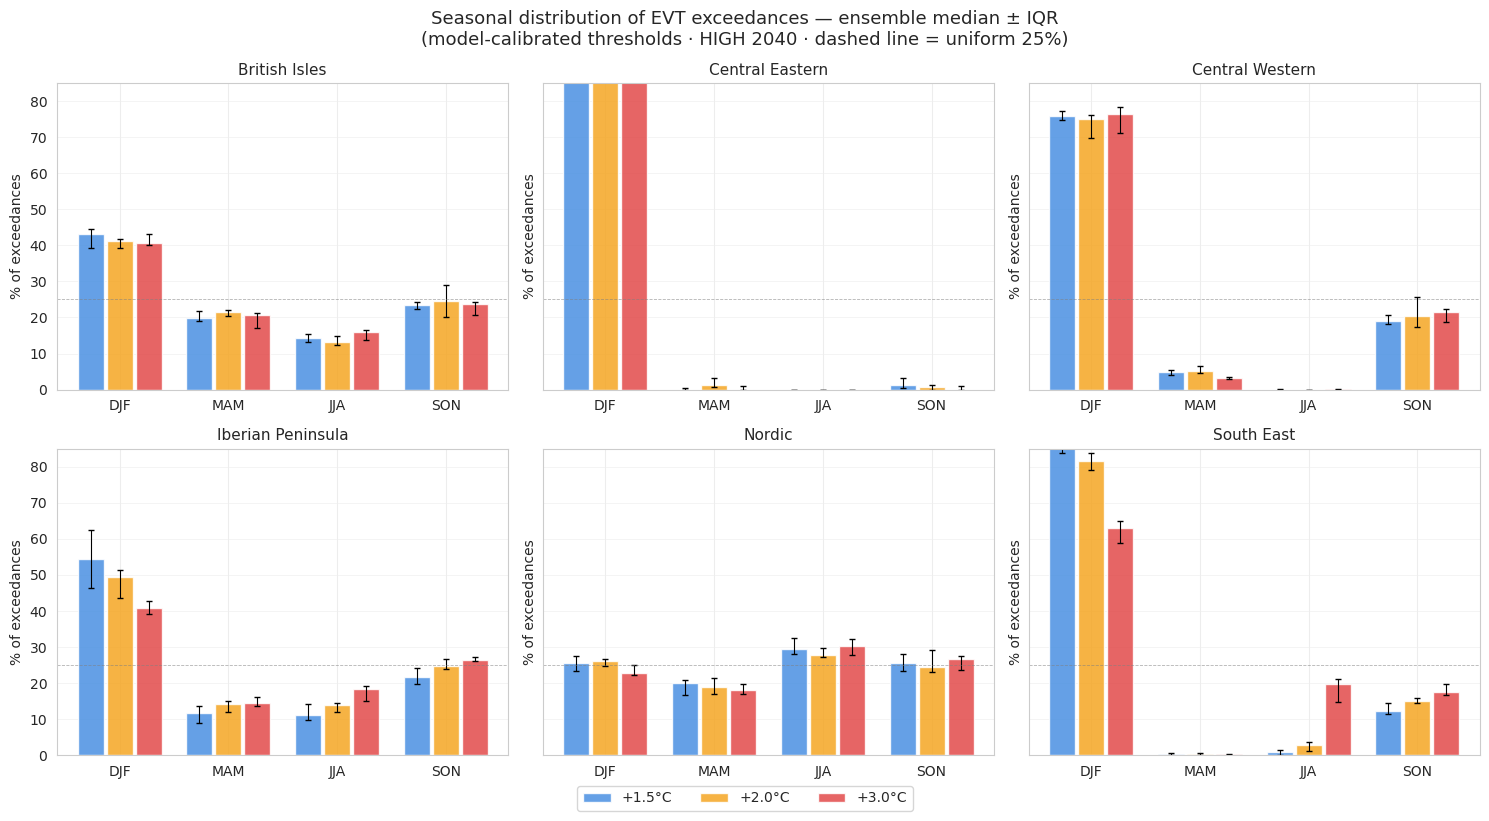

In [55]:
df_seasonal = compute_seasonal_exceedance_fractions(
    _cache_rl, active_thresholds, period_defs, models, season_map, season_order
)
print(f"df_seasonal: {df_seasonal.shape}")

plot_seasonal_exceedance_distribution(
    df_seasonal,
    zones=zones,
    season_order=season_order,
    period_defs=period_defs,
    period_colors=period_colors,
    supply_scenario=supply_scenario,
    supply_year=supply_year,
)

## Seasonal co-occurrence of compound events

Co-occurrence is computed per season using the **common annual threshold**.
For each zone-pair (A, B) and season, the fraction of Zone A exceedance timesteps
that fall within ±72 h of a Zone B exceedance is reported.

In [56]:
df_coo_seasonal = compute_zone_pair_cooccurrence(
    _cache_rl,
    season_active_thresholds,  # {model: {zone: {season: float}}}
    period_defs,
    models,
    zones,
    season_map=season_map,
)
df_coo_seasonal.head()

,model,period,zone_a,zone_b,co_occurrence_pct,season
0,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1,+1.5°C,British_Isles,British_Isles,100.000000,MAM
1,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1,+1.5°C,British_Isles,Central_Eastern,61.797753,MAM
2,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1,+1.5°C,British_Isles,Central_Western,72.471910,MAM
3,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1,+1.5°C,British_Isles,Iberian_Peninsula,12.921348,MAM
4,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1,+1.5°C,British_Isles,Nordic,40.449438,MAM


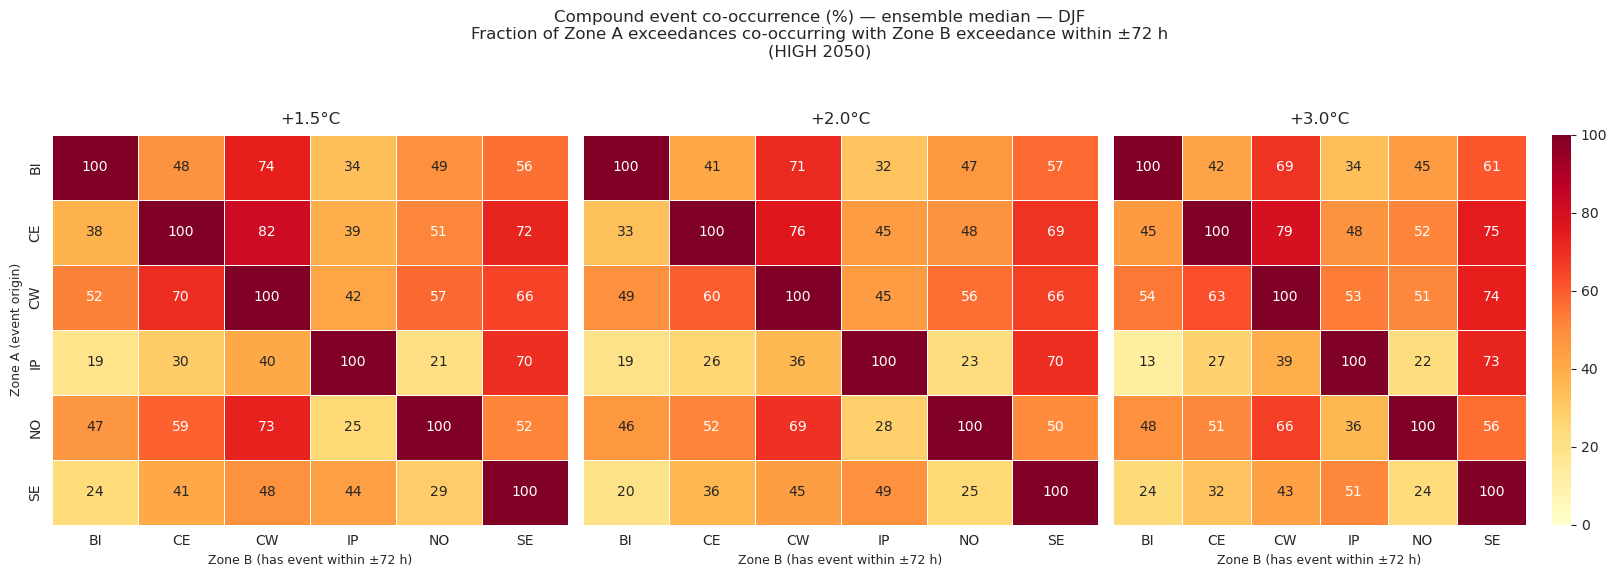

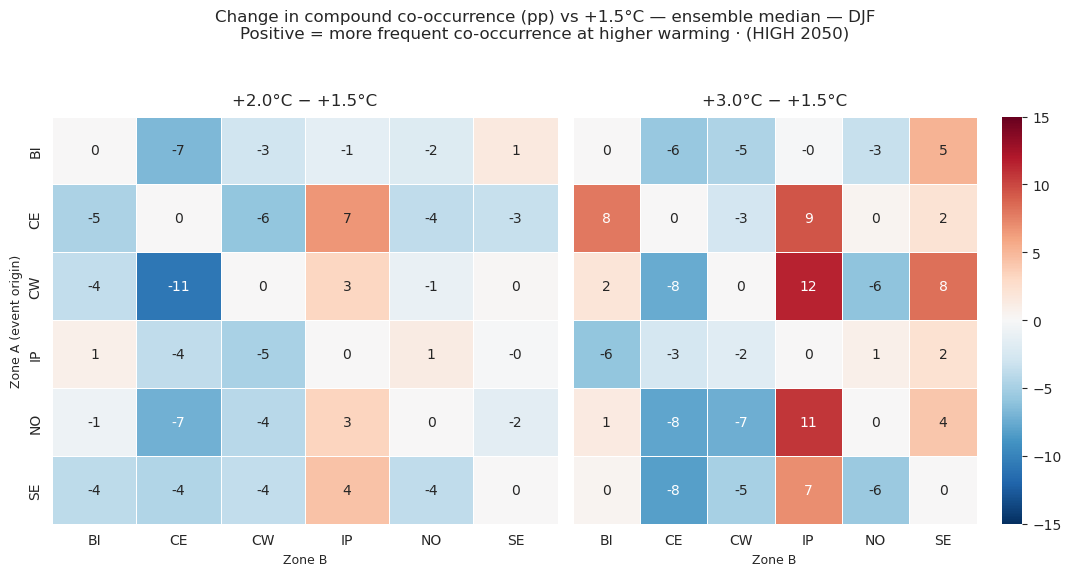

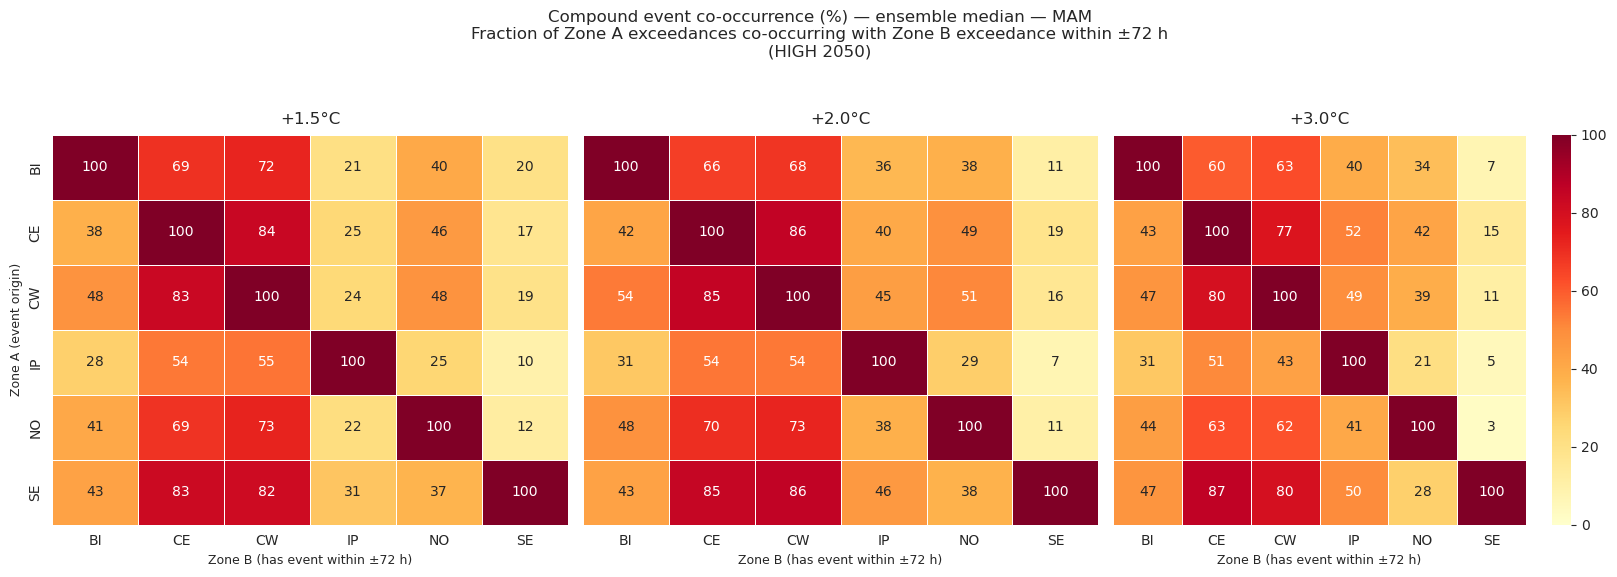

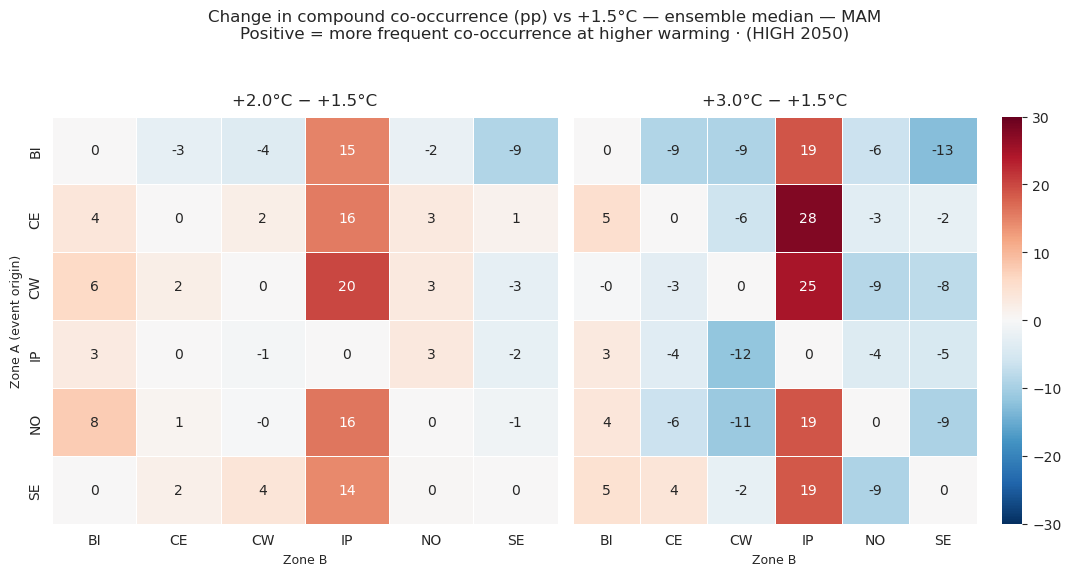

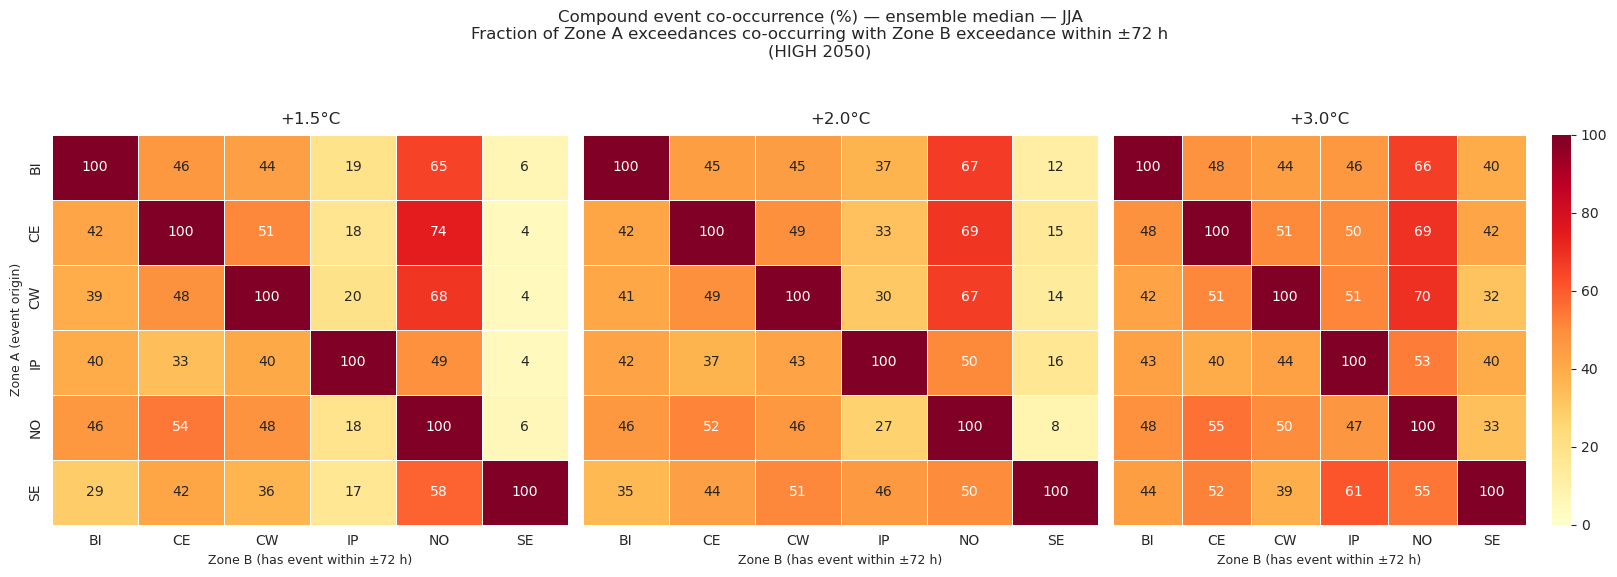

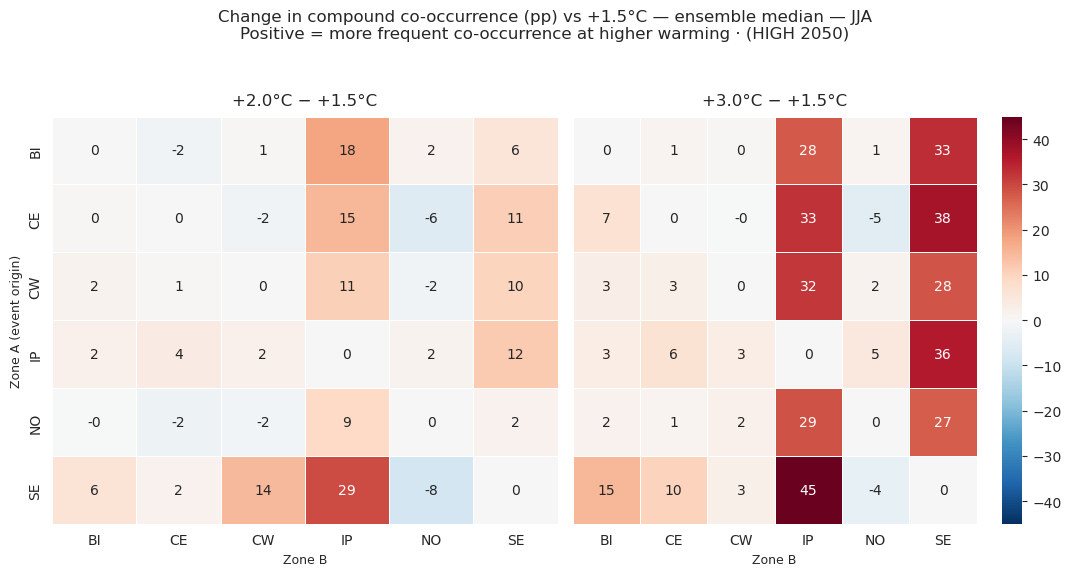

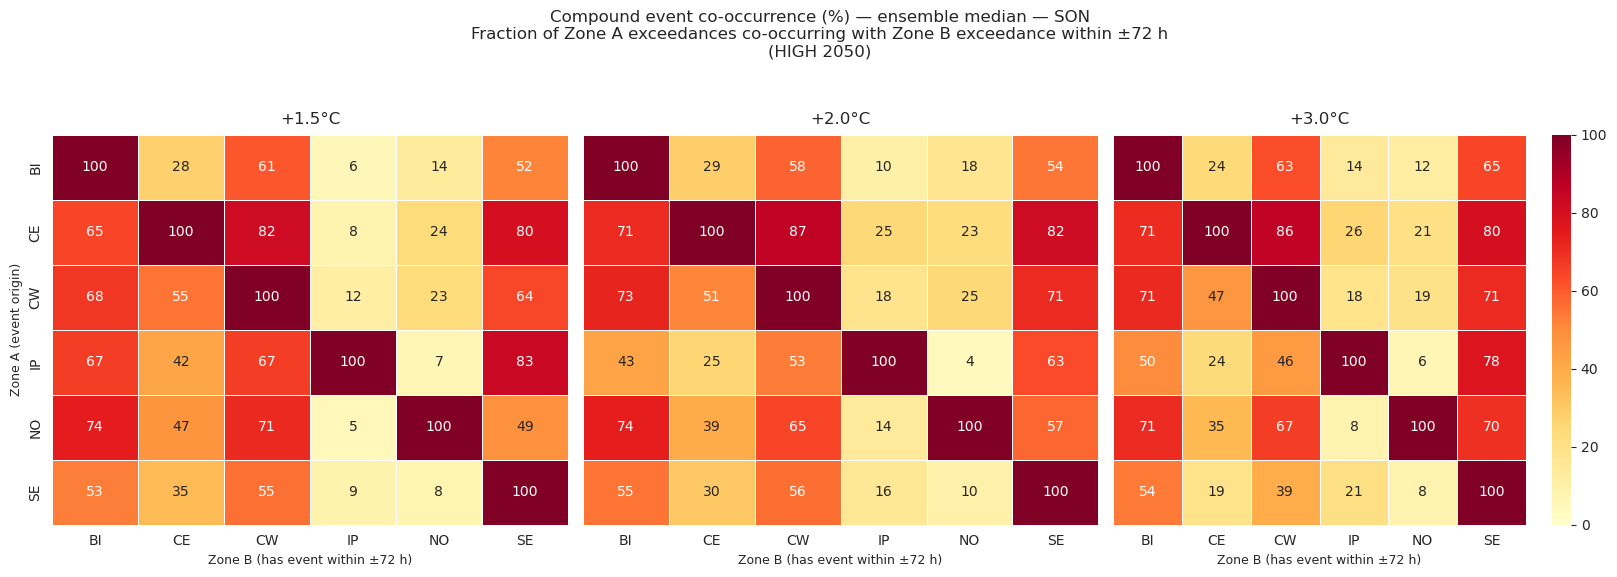

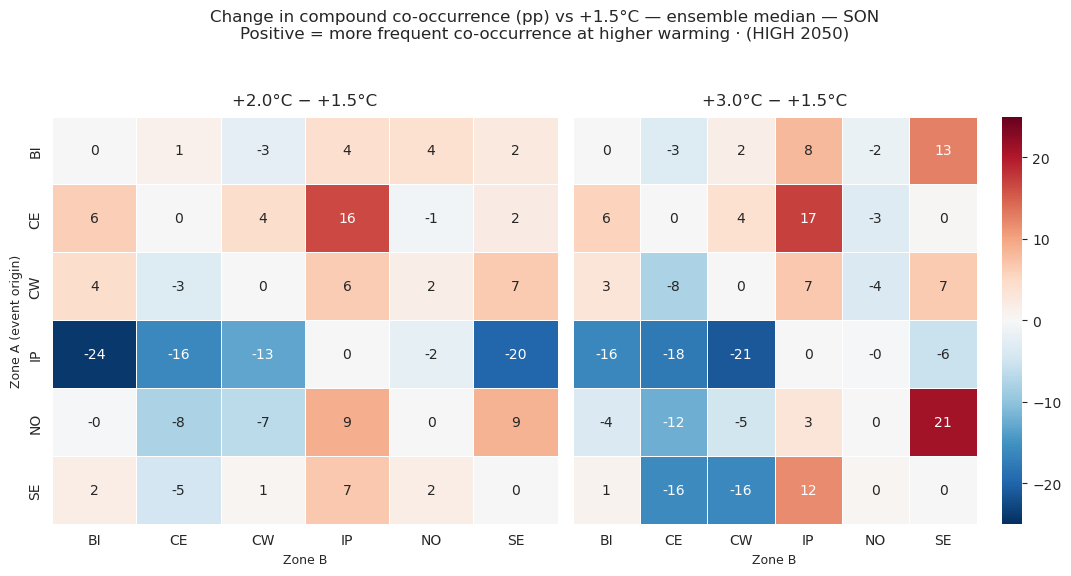

In [57]:
plot_zone_cooccurrence_heatmaps(
    df_coo_seasonal,
    zones=zones,
    period_defs=period_defs,
    season_order=season_order,
    supply_scenario=supply_scenario,
    supply_year=demand_year,
)

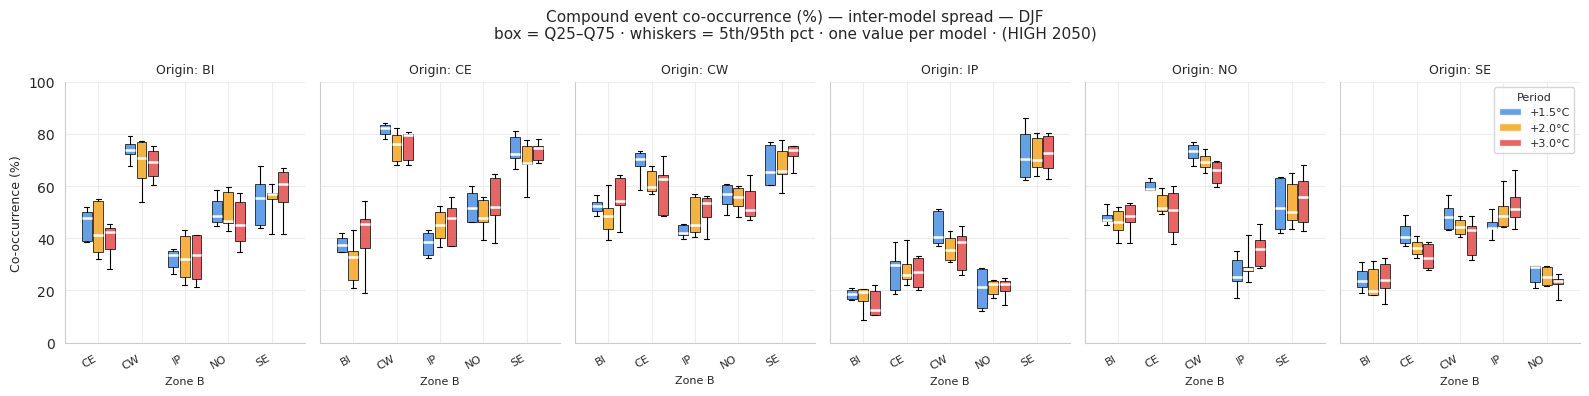

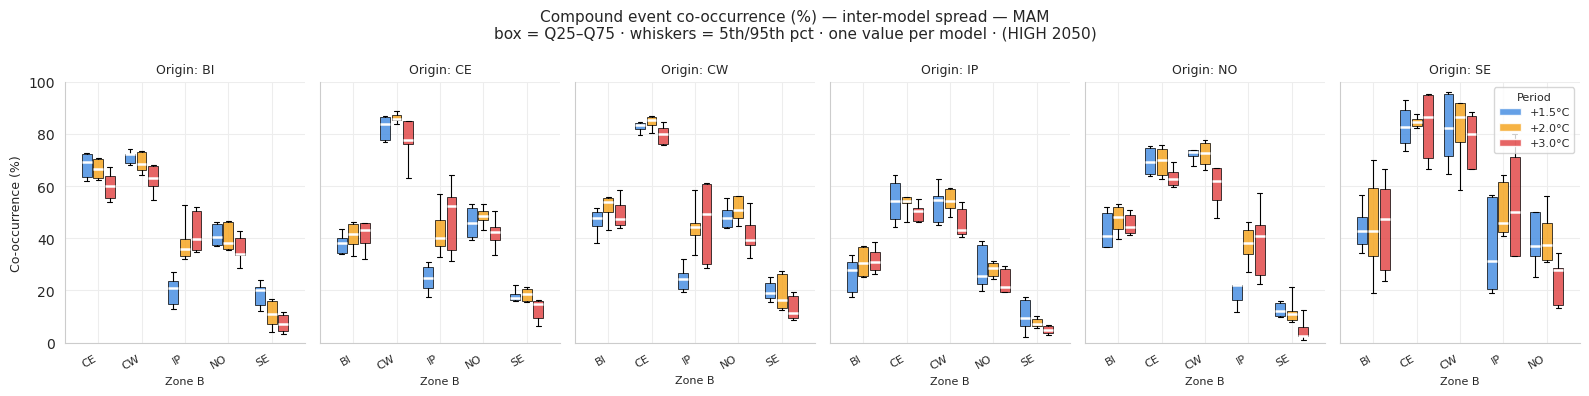

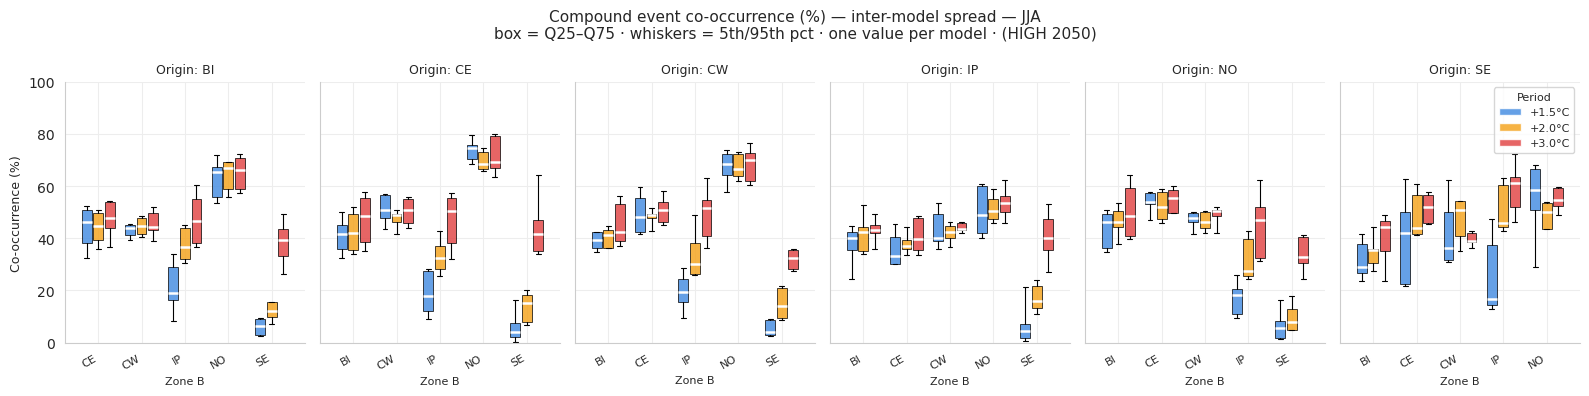

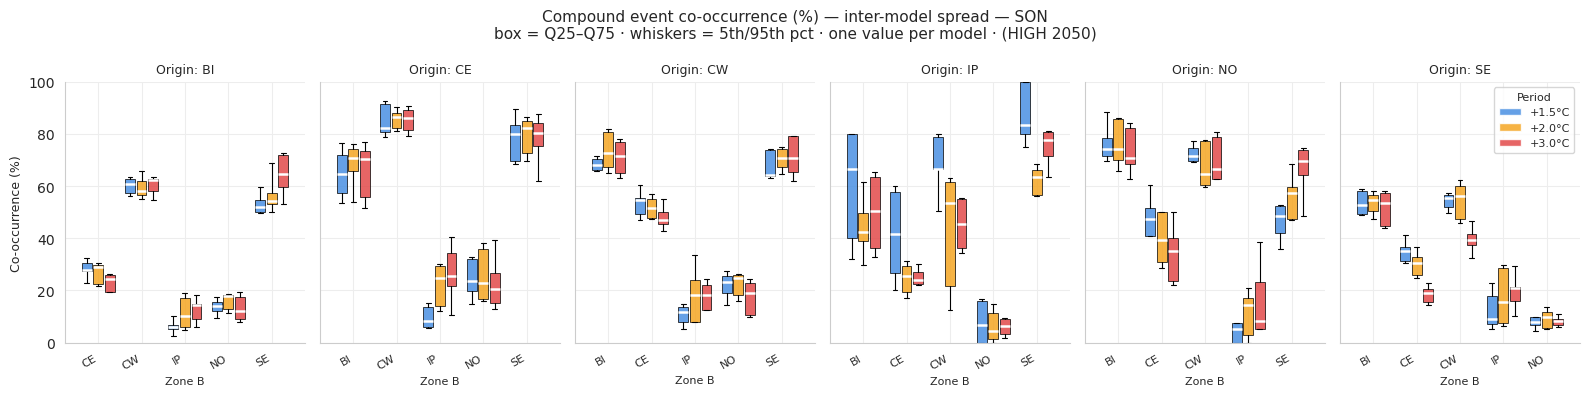

In [58]:
plot_zone_cooccurrence_boxplots(
    df_coo_seasonal,
    zones=zones,
    period_defs=period_defs,
    period_colors=period_colors,
    season_order=season_order,
    supply_scenario=supply_scenario,
    supply_year=demand_year,
    figsize=(16, 4)
)

## Seasonal unserved energy fraction

Share of seasonal electricity demand not met by generation after battery dispatch.
Computed per season, zone, model, and year — then aggregated to mean and worst year
per (model, period, zone, season) and merged into `df_seasonal_evt`.

In [59]:
df_use_seasonal_raw = compute_unserved_energy_fraction(
    _cache_rl,
    _cache_comp,
    period_defs,
    models,
    zones,
    season_map=season_map,
)

df_use_seasonal_agg = (
    df_use_seasonal_raw
    .groupby(["model", "period", "zone", "season"])["use_fraction"]
    .agg(Mean_USE_pct="mean", Max_USE_pct="max")
    .reset_index()
)
df_use_seasonal_agg["Mean_USE_pct"] *= 100
df_use_seasonal_agg["Max_USE_pct"]  *= 100
df_use_seasonal_agg = df_use_seasonal_agg.rename(columns={"period": "Period"})

df_seasonal_evt = df_seasonal_evt.merge(
    df_use_seasonal_agg,
    on=["model", "Period", "zone", "season"],
    how="left",
)
print(f"df_seasonal_evt: {df_seasonal_evt.shape[1]} columns, "
      f"USE range: {df_seasonal_evt['Mean_USE_pct'].min():.2f}% – "
      f"{df_seasonal_evt['Mean_USE_pct'].max():.2f}%")

df_seasonal_evt: 31 columns, USE range: 0.13% – 43.08%


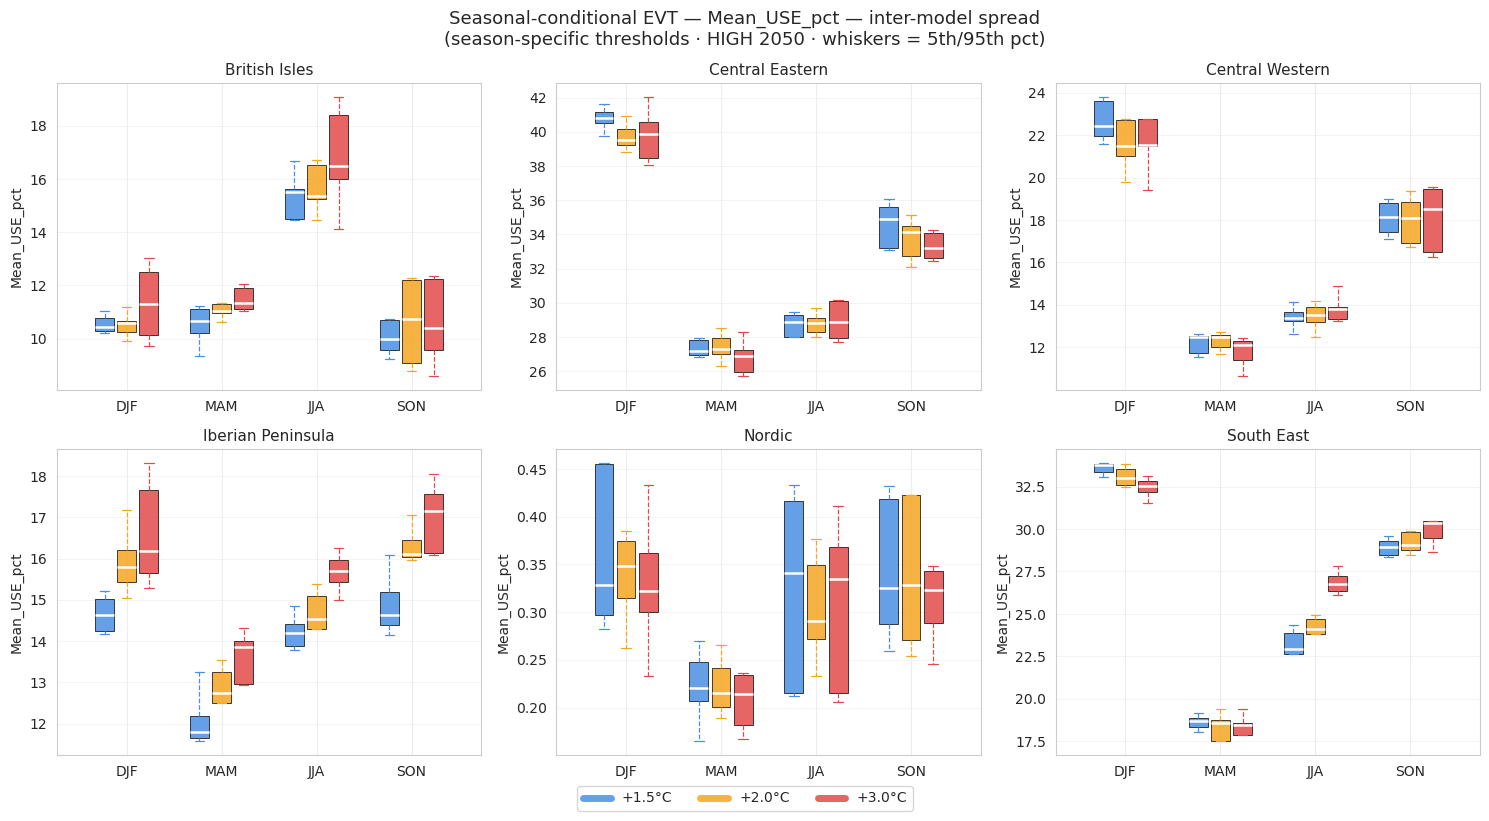

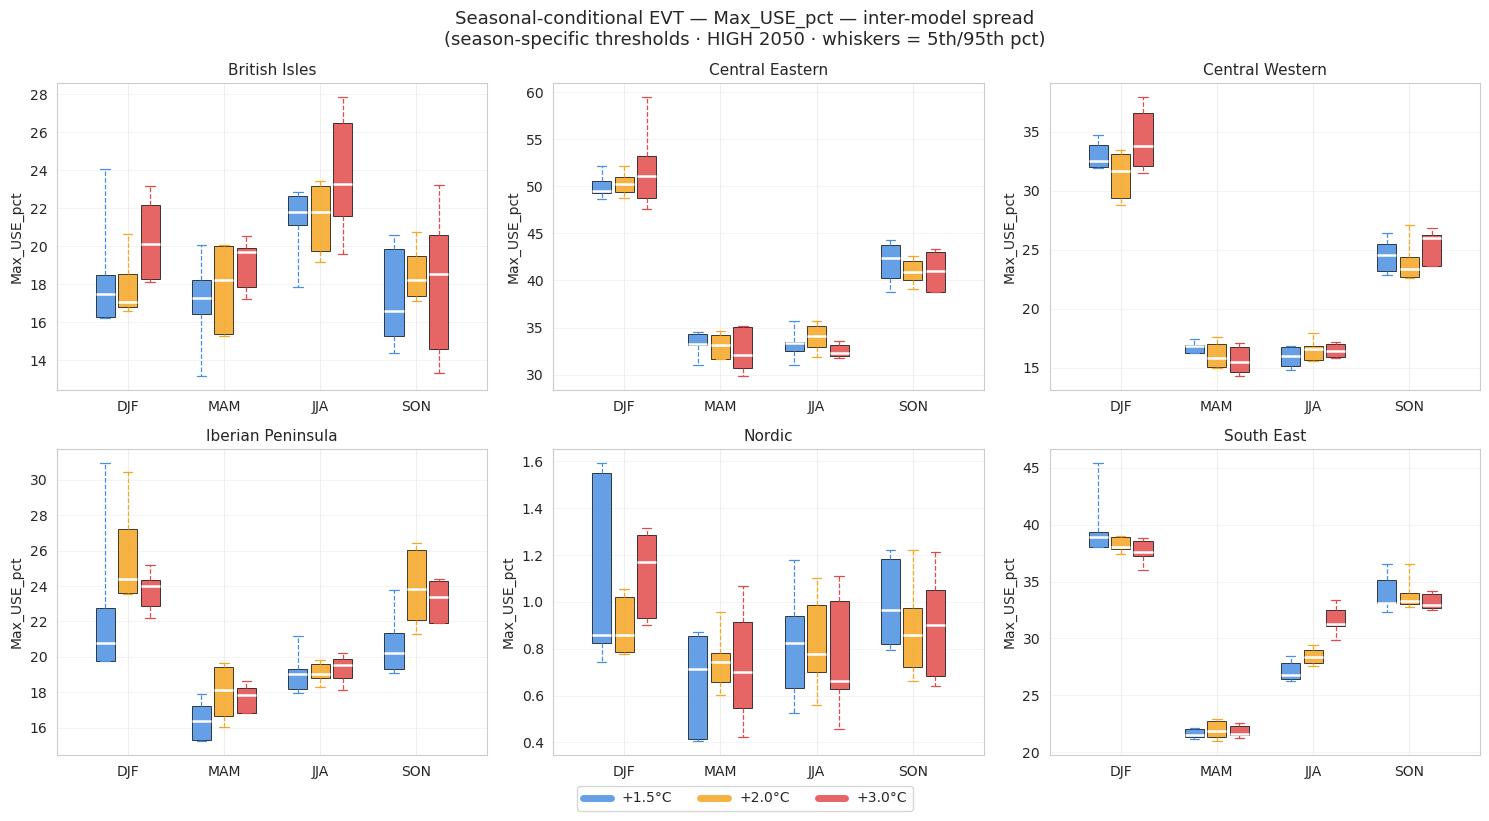

In [60]:
use_metrics = [
    ("Mean_USE_pct", "Mean seasonal unserved energy (%)", "Mean_USE_pct"),
    ("Max_USE_pct",  "Worst-year seasonal unserved energy (%)", "Max_USE_pct"),
]

for col, title_label, ylabel in use_metrics:
    plot_seasonal_conditional_metrics(
        df_seasonal_evt,
        metrics=[(col, ylabel, col)],
        zones=zones,
        period_defs=period_defs,
        season_order=season_order,
        period_colors=period_colors,
        supply_scenario=supply_scenario,
        supply_year=demand_year,
    )

## Seasonal flexibility attenuation

How much do battery and reservoir dispatch reduce the severity of extreme residual
load events **within each season**? For every detected exceedance event the function
reconstructs a counterfactual residual load (re-adding the dispatch at event
timesteps) and computes the percentage severity reduction that the flexibility
resource provides. Events are season-contained — non-season timesteps are masked to
`threshold − ε` before event detection so events cannot straddle season boundaries.

Seasonal thresholds from `season_active_thresholds` are used, consistent with the
threshold method selected by `THRESHOLD_METHOD`.

In [61]:
df_flex_seasonal = compute_flexibility_attenuation_metrics(
    _cache_rl,
    _cache_comp,
    season_active_thresholds,  # {model: {zone: {season: float}}}
    period_defs,
    models,
    zones,
    season_map=season_map,
    method=EVENT_DETECTION_METHOD,
)

# Rename to match df_seasonal_evt merge keys (period → Period, zone kept lowercase)
df_flex_seasonal = df_flex_seasonal.rename(columns={"period": "Period"})

df_seasonal_evt = df_seasonal_evt.merge(
    df_flex_seasonal[[
        "model", "Period", "zone", "season",
        "n_events",
        "battery_deployed_gwh_per_event",
        "prosumer_deployed_gwh_per_event",
        "utility_deployed_gwh_per_event",
        "reservoir_deployed_gwh_per_event",
        "battery_attenuation_pct",
        "prosumer_attenuation_pct",
        "utility_attenuation_pct",
        "reservoir_attenuation_pct",
        "combined_attenuation_pct",
    ]],
    on=["model", "Period", "zone", "season"],
    how="left",
    suffixes=("", "_flex"),
)

print(f"df_seasonal_evt: {df_seasonal_evt.shape[1]} columns after flexibility merge  "
      f"[events={EVENT_DETECTION_METHOD}]")
df_seasonal_evt.groupby(["zone", "season", "Period"])["battery_attenuation_pct"].median().unstack("Period").round(1)

df_seasonal_evt: 41 columns after flexibility merge  [events=spa]


Period                    +1.5°C  +2.0°C  +3.0°C
zone              season                        
British_Isles     DJF       21.8    19.3    20.3
                  JJA       19.0    19.3    17.8
                  MAM       24.5    23.2    22.9
                  SON       23.2    21.7    24.2
Central_Eastern   DJF       18.1    18.5    17.9
                  JJA       53.7    53.4    53.9
                  MAM       32.8    32.9    35.8
                  SON       20.4    21.7    23.1
Central_Western   DJF       19.2    20.2    20.0
                  JJA       48.5    47.1    47.4
                  MAM       45.4    45.1    45.7
                  SON       31.3    32.4    32.2
Iberian_Peninsula DJF       51.1    52.8    54.9
                  JJA       68.9    64.0    63.2
                  MAM       65.1    63.0    61.8
                  SON       59.6    68.4    71.5
Nordic            DJF       11.4    12.3    12.4
                  JJA       14.4    15.6    15.4
                  MAM       19.2    21.1    20.5
                  SON       17.2    22.4    25.1
South_East        DJF       49.3    49.7    46.8
                  JJA       70.9    72.7    71.6
                  MAM       75.4    73.8    74.6
                  SON       57.4    58.3    61.4

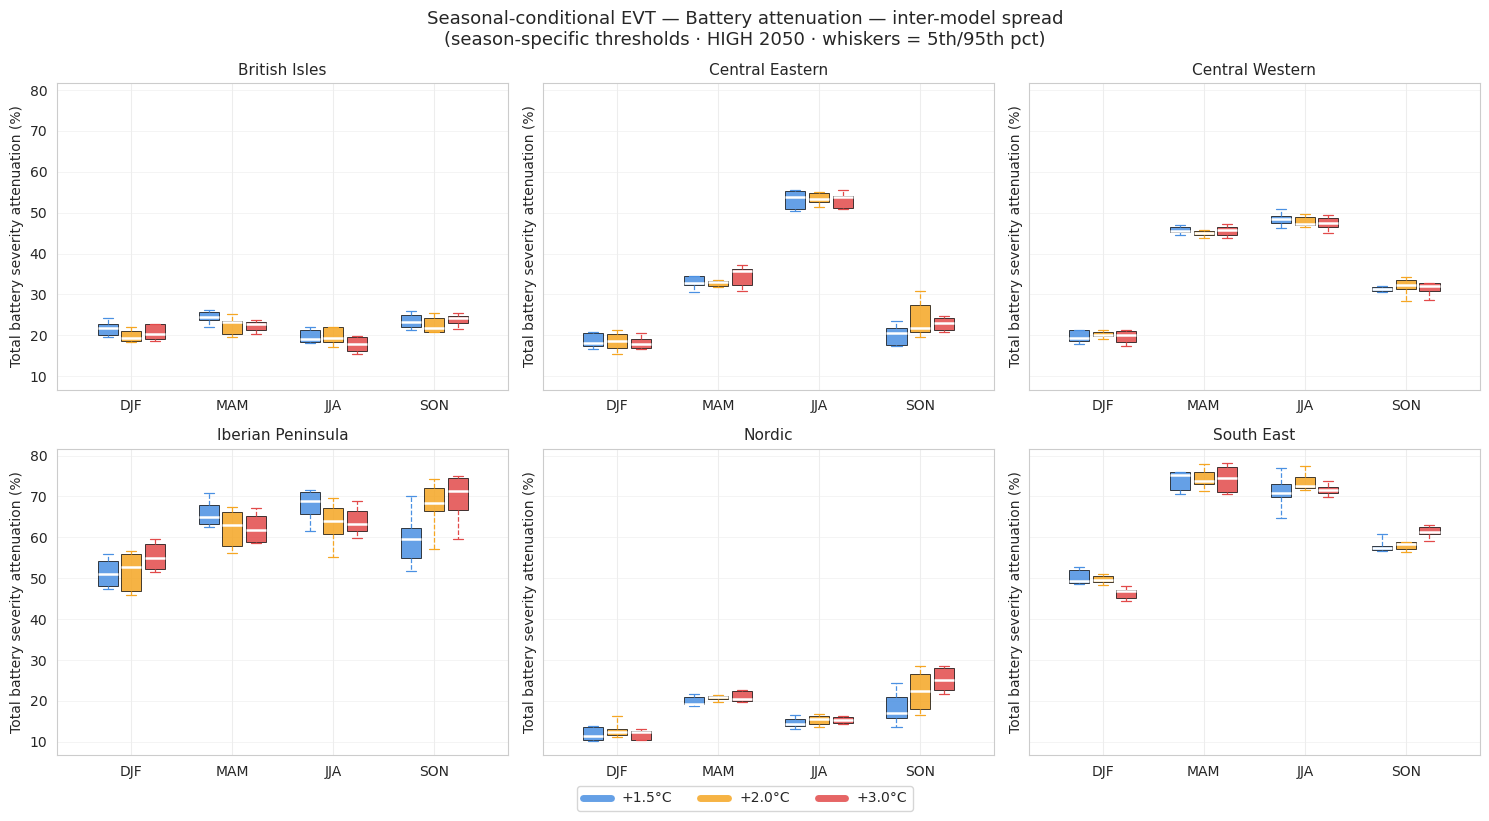

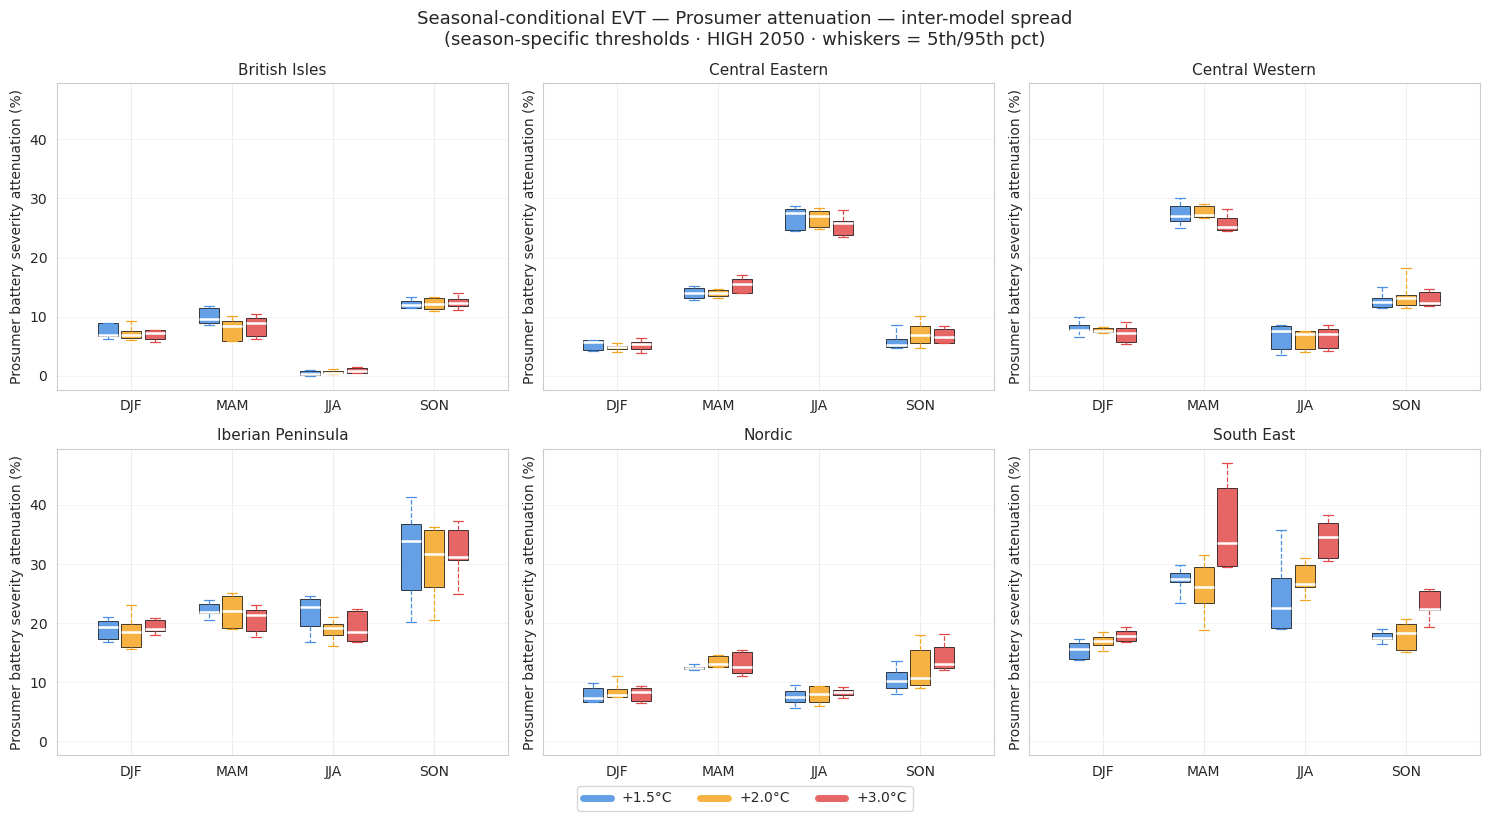

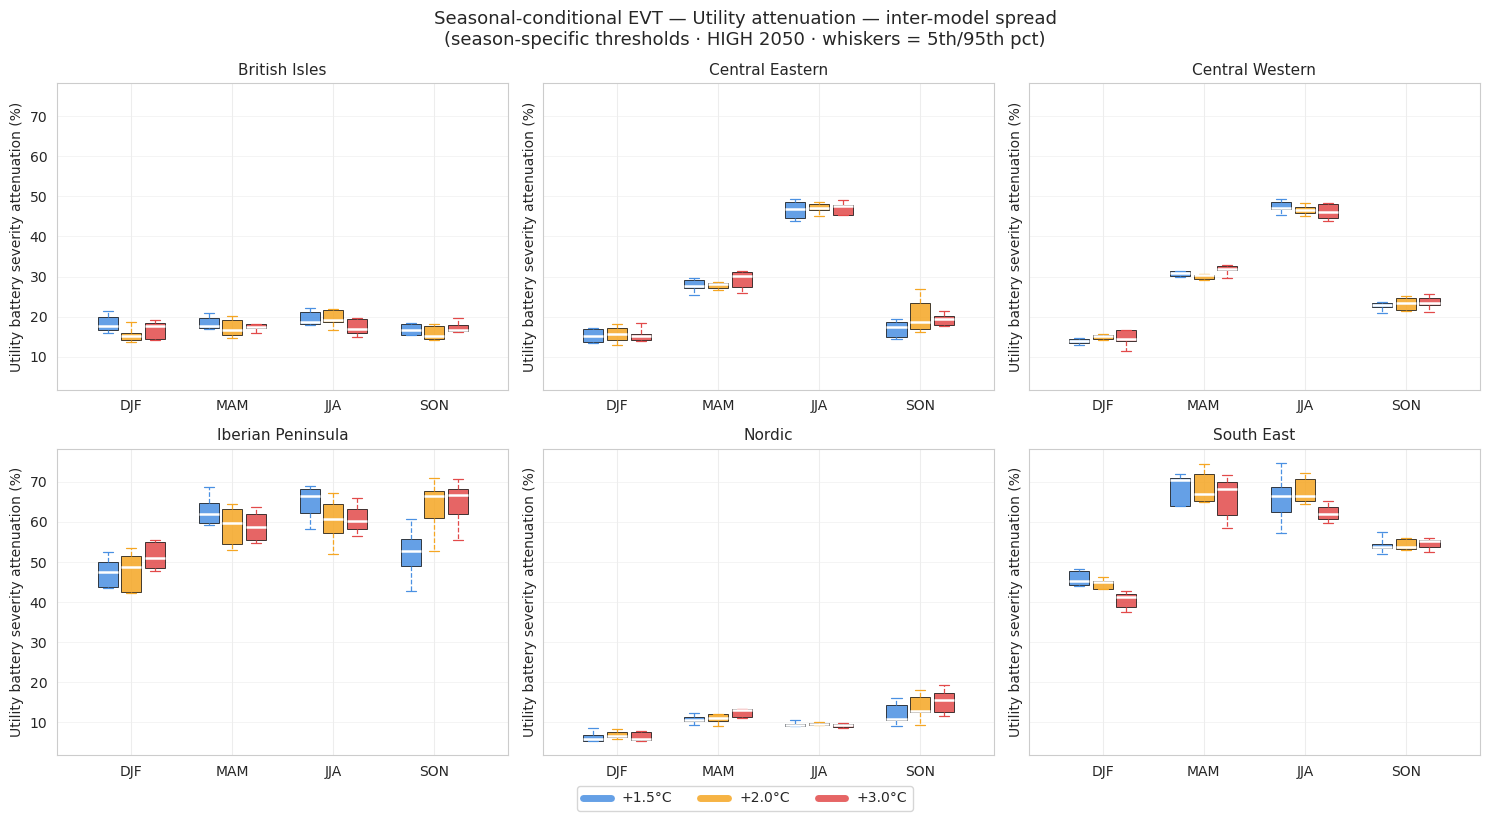

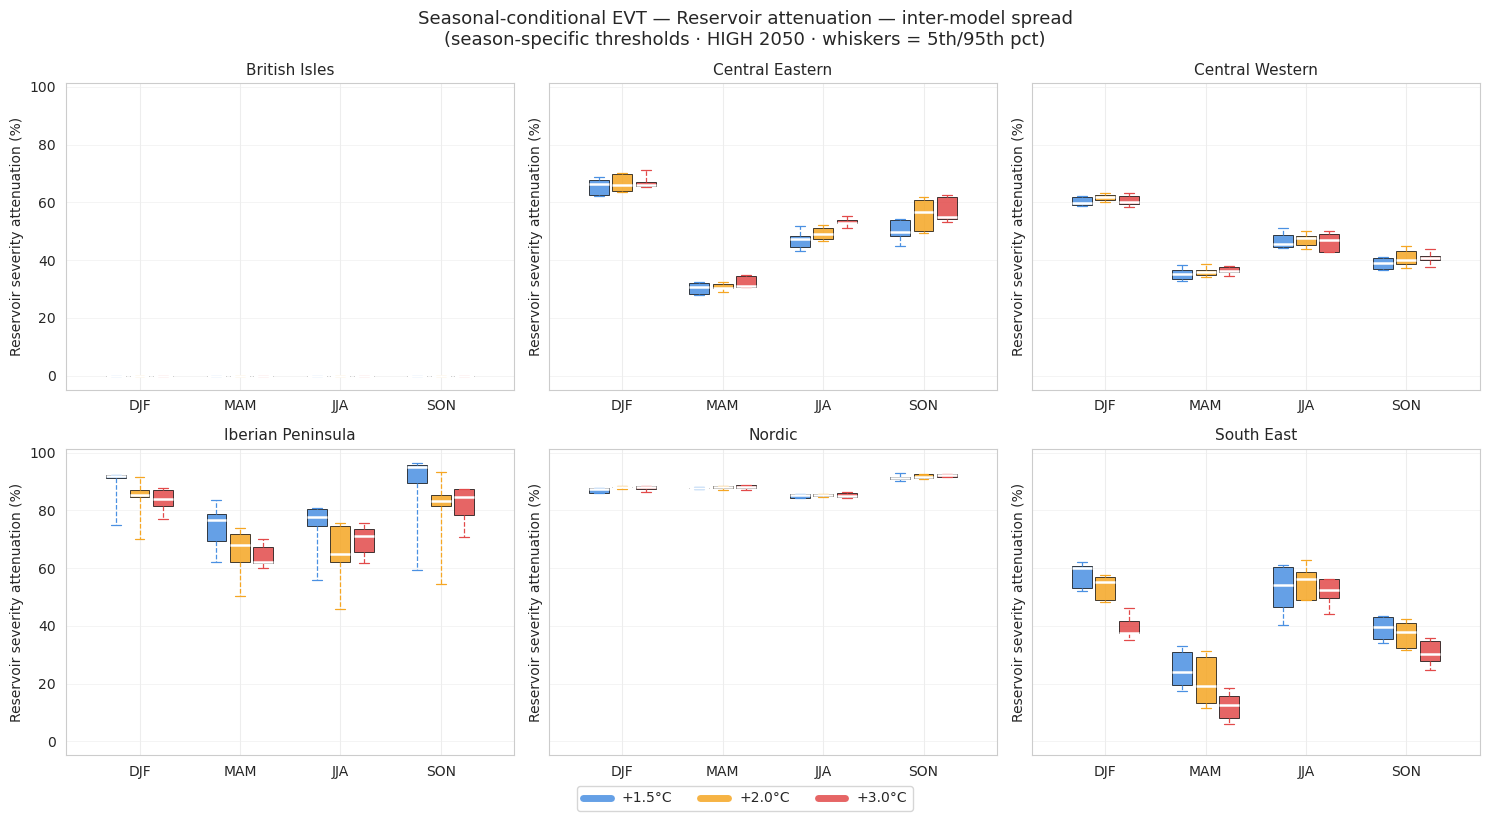

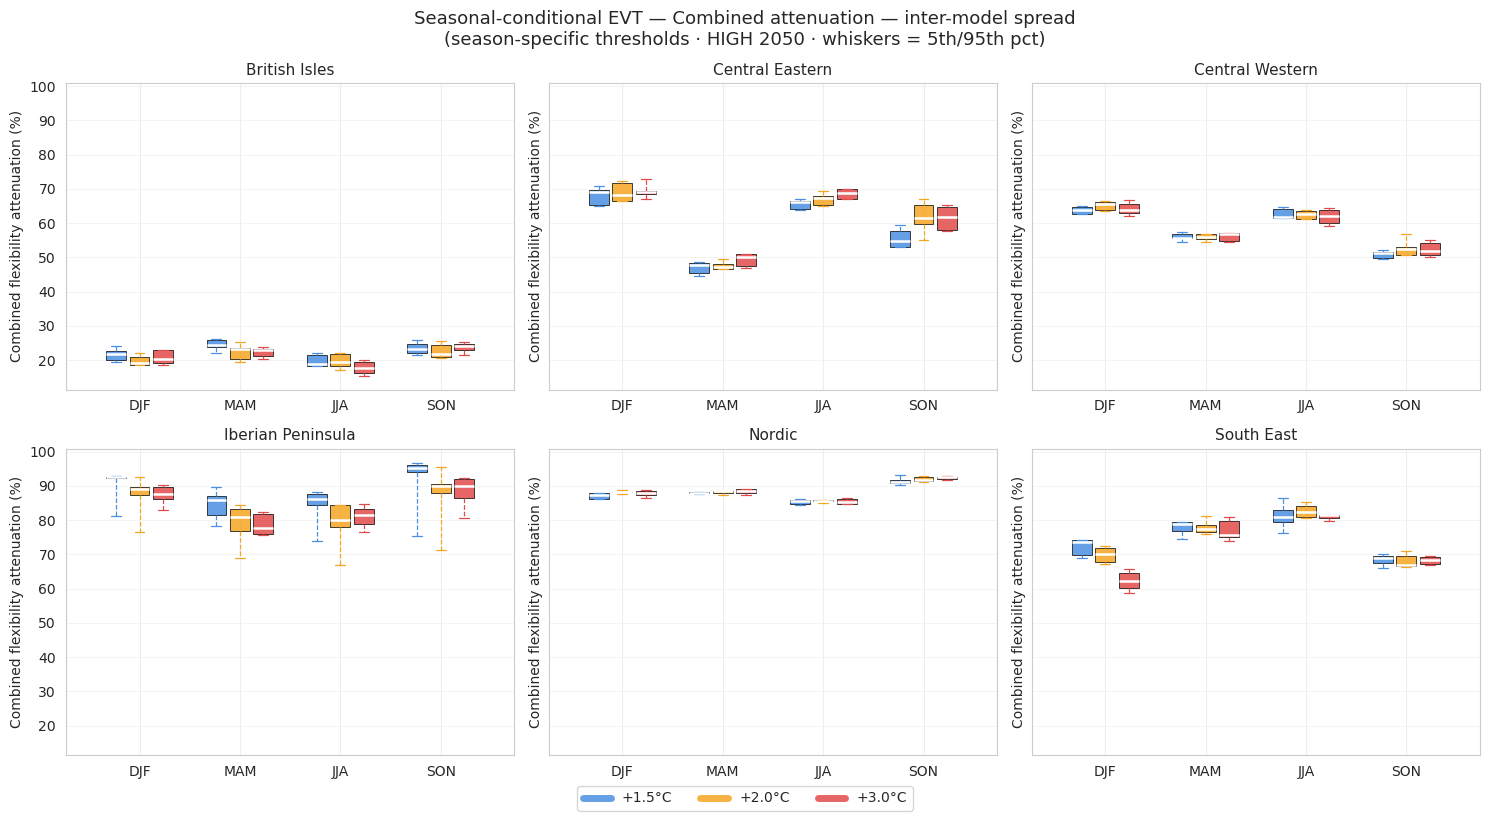

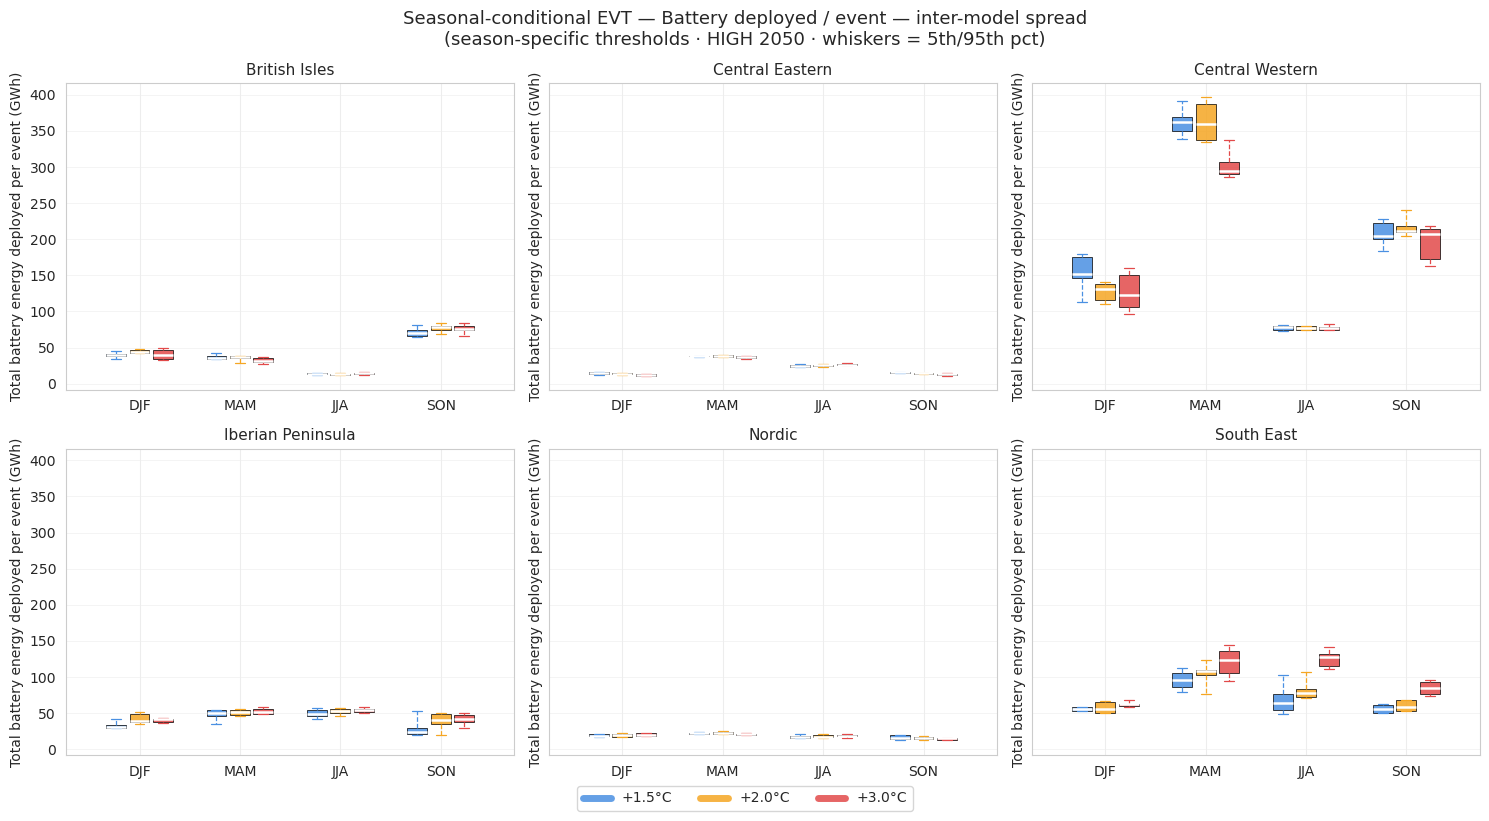

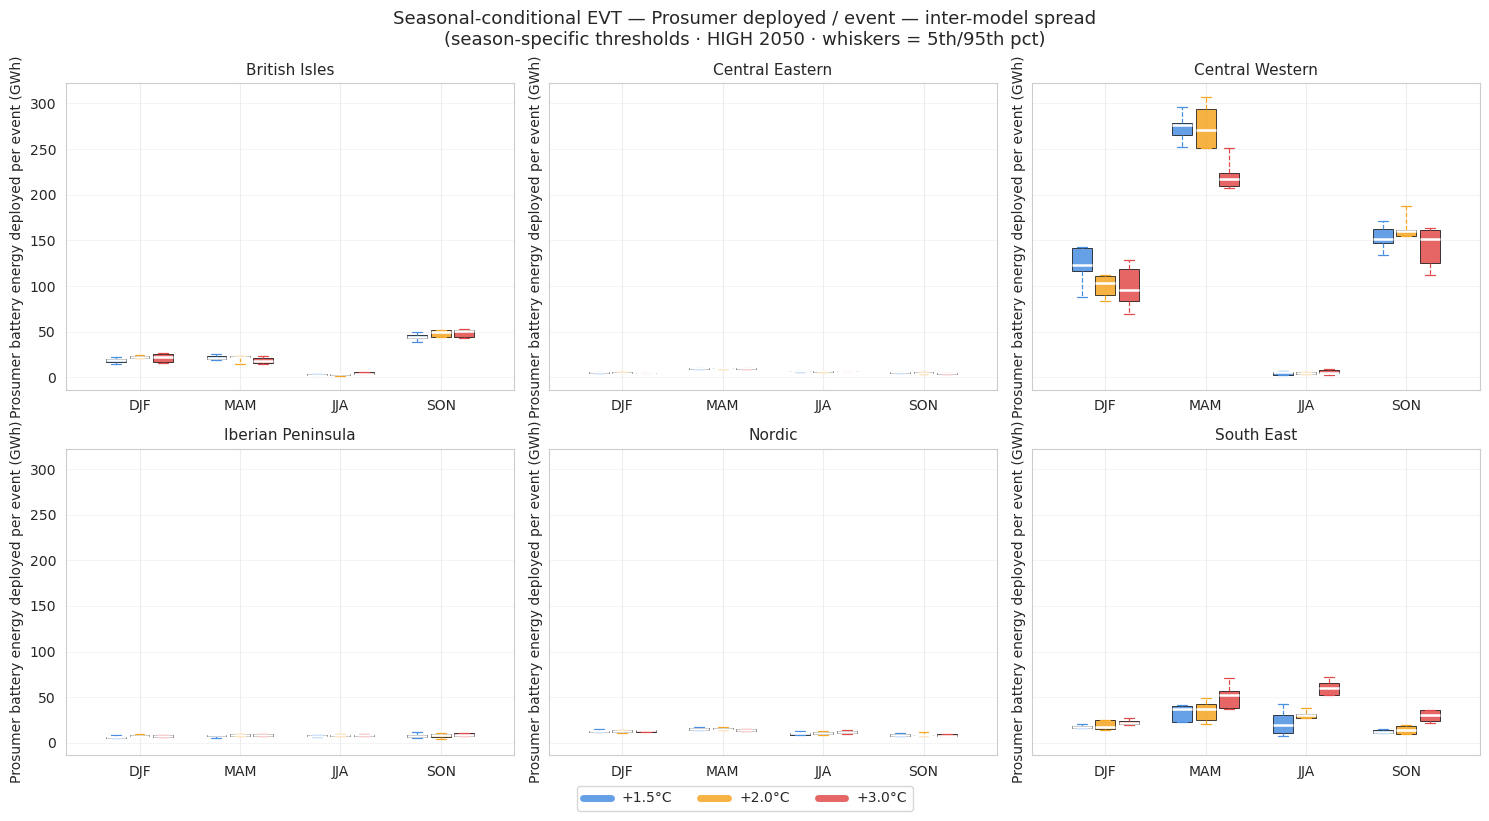

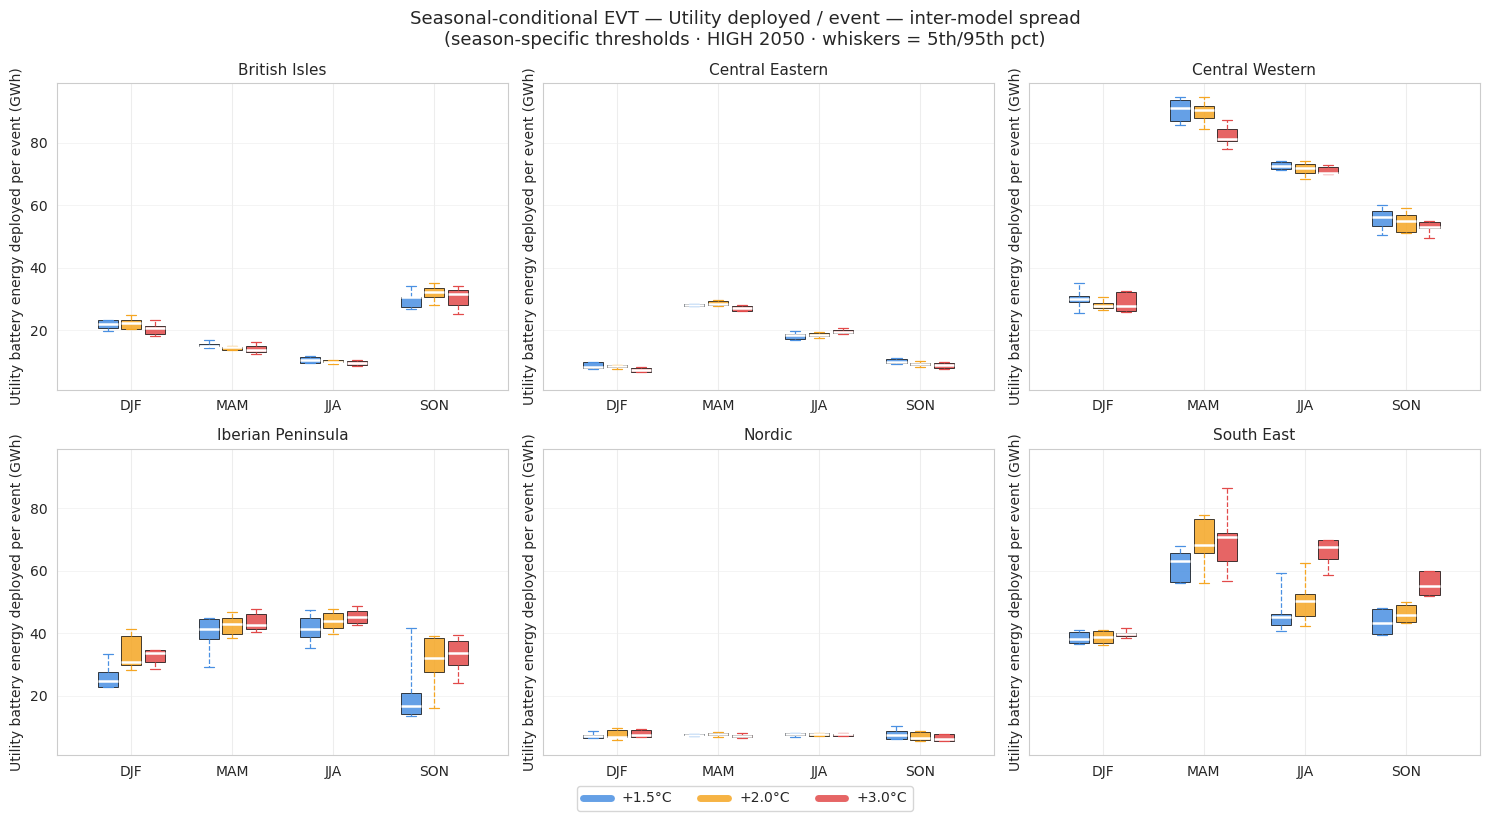

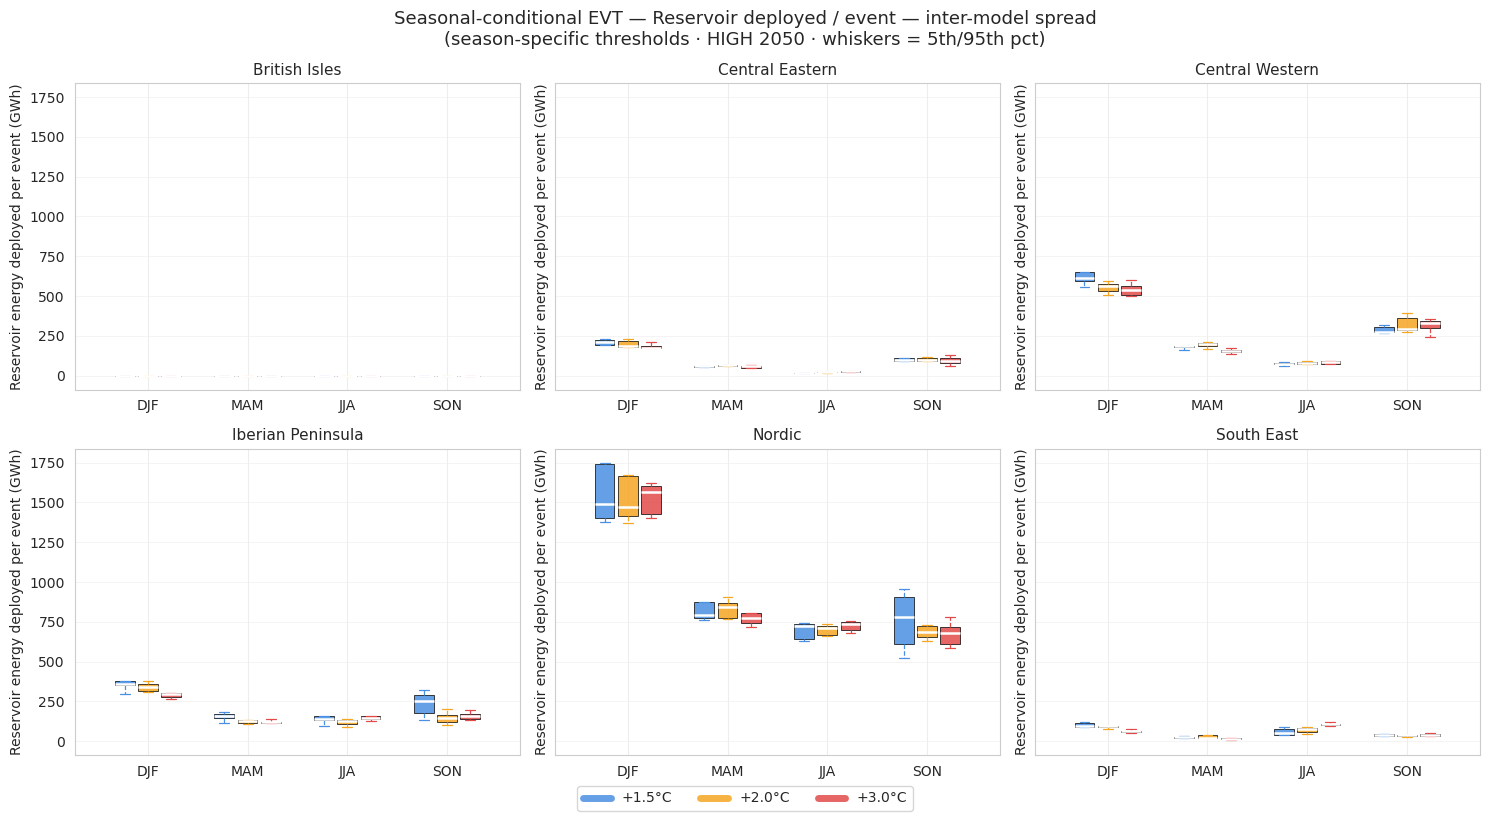

In [62]:
flex_metrics = [
    # ── Attenuation ───────────────────────────────────────────────────────────
    (
        "battery_attenuation_pct",
        "Total battery severity attenuation (%)",
        "Battery attenuation",
    ),
    (
        "prosumer_attenuation_pct",
        "Prosumer battery severity attenuation (%)",
        "Prosumer attenuation",
    ),
    (
        "utility_attenuation_pct",
        "Utility battery severity attenuation (%)",
        "Utility attenuation",
    ),
    (
        "reservoir_attenuation_pct",
        "Reservoir severity attenuation (%)",
        "Reservoir attenuation",
    ),
    (
        "combined_attenuation_pct",
        "Combined flexibility attenuation (%)",
        "Combined attenuation",
    ),
    # ── Deployed energy ───────────────────────────────────────────────────────
    (
        "battery_deployed_gwh_per_event",
        "Total battery energy deployed per event (GWh)",
        "Battery deployed / event",
    ),
    (
        "prosumer_deployed_gwh_per_event",
        "Prosumer battery energy deployed per event (GWh)",
        "Prosumer deployed / event",
    ),
    (
        "utility_deployed_gwh_per_event",
        "Utility battery energy deployed per event (GWh)",
        "Utility deployed / event",
    ),
    (
        "reservoir_deployed_gwh_per_event",
        "Reservoir energy deployed per event (GWh)",
        "Reservoir deployed / event",
    ),
]

plot_seasonal_conditional_metrics(
    df_seasonal_evt,
    metrics=flex_metrics,
    zones=zones,
    period_defs=period_defs,
    season_order=season_order,
    period_colors=period_colors,
    supply_scenario=supply_scenario,
    supply_year=demand_year,
    sharey=True
)